# Spatial features of the NSCLC tumor microenvironment (TECBio REU 2026, PredxBio / University of Pittsburgh)

Notebook by Prisha Bhanushali. It builds per-cell features (area, eccentricity, darkness, entropy, density) from cell segmentation output and H&E images, summarises tumor and immune organisation per region of interest, groups regions into immune architecture classes (hot, excluded, cold) and relates the features to overall survival in the 14 patients with linked TCGA outcome data.

* Input data (segmentation JSON, H&E images, clinical tables) are not included. Paths below are relative to a local `data/` folder.
* Run the cells top to bottom in one session.
* The Cox analysis is exploratory (n = 14). See the note above that section.
* Figure-polishing cells from the end of the original notebook were removed. The full original is in the repository history (commit 87932cc).

In [1]:
import json
import gzip
import os
#import libarares
    #json knows how to read JSON file
    #gzip knows how to decompress .gz compressed files
    #os handles file paths

file1_path = os.path.expanduser("data/patient11_he_roi4.json.gz")
file2_path = os.path.expanduser("data/patient12_he_roi2.json.gz")
file4_path = os.path.expanduser("data/patient4_he_roi4.json.gz")
file5_path = os.path.expanduser("data/patient5_he_roi4.json.gz")
#load JSON files 


with gzip.open(file1_path, "rt") as f:
    data1 = json.load(f)
with gzip.open(file2_path, "rt") as f:
    data2 = json.load(f)
with gzip.open(file4_path, "rt") as f:
    data4 = json.load(f)
with gzip.open(file5_path, "rt") as f:
    data5 = json.load(f)
#gzip.open opens compressed file & decompresses it
#json.load(f) parses decompressed text into Python list -> each element = one cell's data
#with closes file once done reading 
#data1 stores results

print("Patient 11 cells:", len(data1))
print("Patient 12 cells:", len(data2))
print("Patient 4 cells:", len(data4))
print("Patient 5 cells:", len(data5))

#confirms files loaded correctly
#<class 'list'> says Python read JSON file and stored it as list (one entry per cell)

Patient 11 cells: 1684
Patient 12 cells: 2224
Patient 4 cells: 5159
Patient 5 cells: 4230


In [2]:
print("File 1 - number of entries:", len(data1))
print("File 2 - number of entries:", len(data2))
#len() counts item # in list
    #tells you how many cells detected in image

print("\nFile 1 - first entry:")
print(data1[0])

print("\nFile 2 - first entry:")
print(data2[0])

#data1[0] accesses 1st element in list

File 1 - number of entries: 1684
File 2 - number of entries: 2224

File 1 - first entry:
{'geometry': {'type': 'Polygon', 'coordinates': [[[655.0, 952.0], [648.0, 948.0], [647.0, 949.0], [637.0, 949.0], [634.0, 951.0], [632.0, 951.0], [628.0, 961.0], [628.0, 964.0], [622.0, 972.0], [622.0, 977.0], [623.0, 979.0], [630.0, 982.0], [634.0, 982.0], [642.0, 979.0], [651.0, 970.0], [655.0, 963.0], [655.0, 952.0]]], 'centroid': [639, 964]}, 'properties': {'object_type': 'cell', 'classification': {'name': 'Nuclei', 'colorRGB': -65536}, 'isLocked': False}, 'type': 'Feature'}

File 2 - first entry:
{'geometry': {'type': 'Polygon', 'coordinates': [[[536.0, 1836.0], [529.0, 1832.0], [522.0, 1832.0], [505.0, 1840.0], [496.0, 1848.0], [492.0, 1848.0], [485.0, 1855.0], [485.0, 1882.0], [503.0, 1890.0], [511.0, 1890.0], [516.0, 1893.0], [520.0, 1893.0], [527.0, 1889.0], [543.0, 1860.0], [542.0, 1846.0], [536.0, 1836.0]]], 'centroid': [514, 1862]}, 'properties': {'object_type': 'cell', 'classification'

In [3]:
import pandas as pd
import numpy as np
#pandas working with data format
#numpy for calculations

def parse_cells(data):
    rows = []
#function parse_cells takes JSON list & converts into table
#rows = empty list -> get filled by cells
    for cell in data:
        centroid = cell['geometry']['centroid']
        coords = cell['geometry']['coordinates'][0]
#loops through every cell
#cell['geometry']['centroid'] gets center point
#cell['geometry']['coordinates'][0] gives polygon boundaries
        rows.append({
            'x': centroid[0],
            'y': centroid[1],
            'polygon': coords
        })
#creates dictionary 
#x(horizontal position); y(vertical position); polygon(boundary coord.) -> adds to rows list
    #rows = list of 1684 dictionaries(one per cell)
    return pd.DataFrame(rows)
#converts list of dictionaries into pandas DataFrame

df1 = parse_cells(data1)
df2 = parse_cells(data2)
#runs functions on patients data 
#df1 & df2 store results

print("File 1 shape:", df1.shape)
print(df1.head())
#df1.shape gives dimensions of the table
#df1.head() shows 1st 5 rows (make sure table looks correct)

File 1 shape: (1684, 3)
     x    y                                            polygon
0  639  964  [[655.0, 952.0], [648.0, 948.0], [647.0, 949.0...
1  572  962  [[557.0, 942.0], [552.0, 947.0], [551.0, 950.0...
2  743  965  [[731.0, 946.0], [727.0, 950.0], [724.0, 960.0...
3  900  961  [[886.0, 953.0], [884.0, 958.0], [884.0, 963.0...
4  701  970  [[683.0, 953.0], [680.0, 961.0], [685.0, 976.0...


In [4]:
from shapely.geometry import Polygon
#shapely for geometric operations 

def compute_area(polygon):
    return Polygon(polygon).area
#compute_area function takes list of polygon objects & returns area in square pixels
#.area gives answer & shapely handles math

def compute_eccentricity(polygon):
    poly = Polygon(polygon)
    # Get the minimum bounding ellipse approximation using bounding box
    minx, miny, maxx, maxy = poly.bounds
    width = maxx - minx
    height = maxy - miny
#poly.bounds gives 4 edges of smallest rectangle that fits around polygon -> find width and height of bounding box
    if height == 0:
        return 0
#if cell has 0 height -> returns 0
    major = max(width, height)
    minor = min(width, height)
    # Eccentricity: 0 = perfect circle, closer to 1 = very elongated
    eccentricity = np.sqrt(1 - (minor/major)**2)
    return eccentricity
#major = longer dimension of bounding box; minor = shorter
#eccentricity formula = qrt(1 - (minor/major)**2)
#if circle -> minor/major = 1 & eccentricity = 0 -> as ratio approaches 0 eccentricity approaches 1

df1['area'] = df1['polygon'].apply(compute_area)
df1['eccentricity'] = df1['polygon'].apply(compute_eccentricity)
#.apply() runs compute_area on all polygons and stores into column -> area in dataframe
#same for eccentricity

print(df1[['x', 'y', 'area', 'eccentricity']].head())
print("\nArea stats:")
print(df1['area'].describe())
print("\nEccentricity stats:")
print(df1['eccentricity'].describe())
#prints 1st 5 rows w all 4 col. -> check values (make sure they look real)
#.describe() gives summary statistics f/each feature 
#understand distribution between cells in context of each other

     x    y    area  eccentricity
0  639  964   777.5      0.240746
1  572  962  1625.5      0.440079
2  743  965  1091.0      0.308515
3  900  961   667.5      0.574960
4  701  970  1288.5      0.625780

Area stats:
count    1684.000000
mean      539.513064
std       385.833308
min        84.500000
25%       287.875000
50%       409.250000
75%       683.625000
max      2655.500000
Name: area, dtype: float64

Eccentricity stats:
count    1684.000000
mean        0.530525
std         0.215144
min         0.000000
25%         0.407862
50%         0.552771
75%         0.689848
max         0.948030
Name: eccentricity, dtype: float64


In [5]:
!pip install shapely

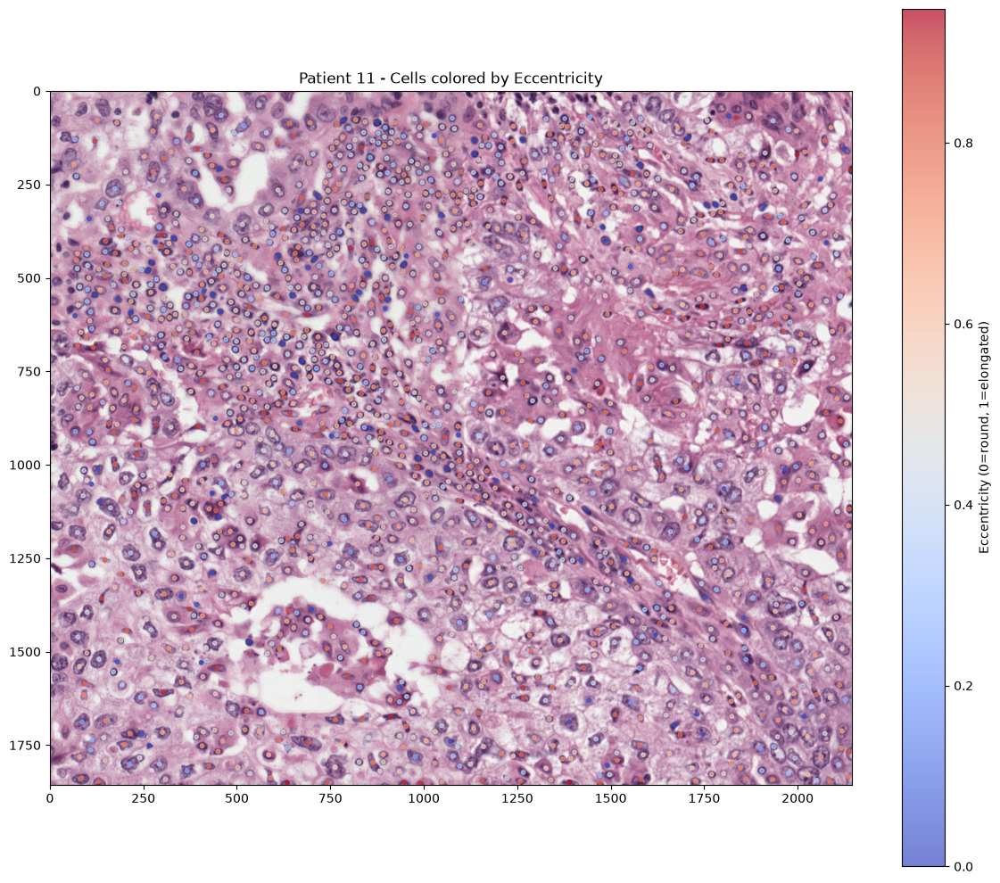

In [6]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
#matplotlib -> plotting libaray
#pyplot creates figures
#image for loading/displaying images (PNG files)

img = mpimg.imread(os.path.expanduser("data/patient11_he_roi4.png"))
#loads the PNG image for patient 11
    #mpimg.imread converts PNG file into numpy array of pixel values
    #os.path.expanduser makes code portable


fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img)
#plt.subplots creates blanks canvas
#ax.imshow(img) draws H&E image onto canvas as background layer (everything plotted is on top of it)

scatter = ax.scatter(df1['x'], df1['y'], 
                     c=df1['eccentricity'], 
                     cmap='coolwarm', 
                     s=10, 
                     alpha=0.7)
#Plot centroids colored by eccentricity
    #ax.scatter plots a dot for every cell
    #df1['x'], df1['y'] set position for dot (centroid coord.)
    #c=df1['eccentricity'] colors each dot its eccentric value
    #cmap='coolwarm' makes blue round and red elongated
    #s=10 sets dot size to 10 pixels
    #alpha=0.7 makes dots a little transparent (H&E image still shows)

plt.colorbar(scatter, ax=ax, label='Eccentricity (0=round, 1=elongated)')
ax.set_title('Patient 11 - Cells colored by Eccentricity')
plt.tight_layout()
plt.show()
#plt.colorbar = color legend
#ax.set_title sets title 
#plt.tight_layout() adjusts spacing
#plt.show() shows plot

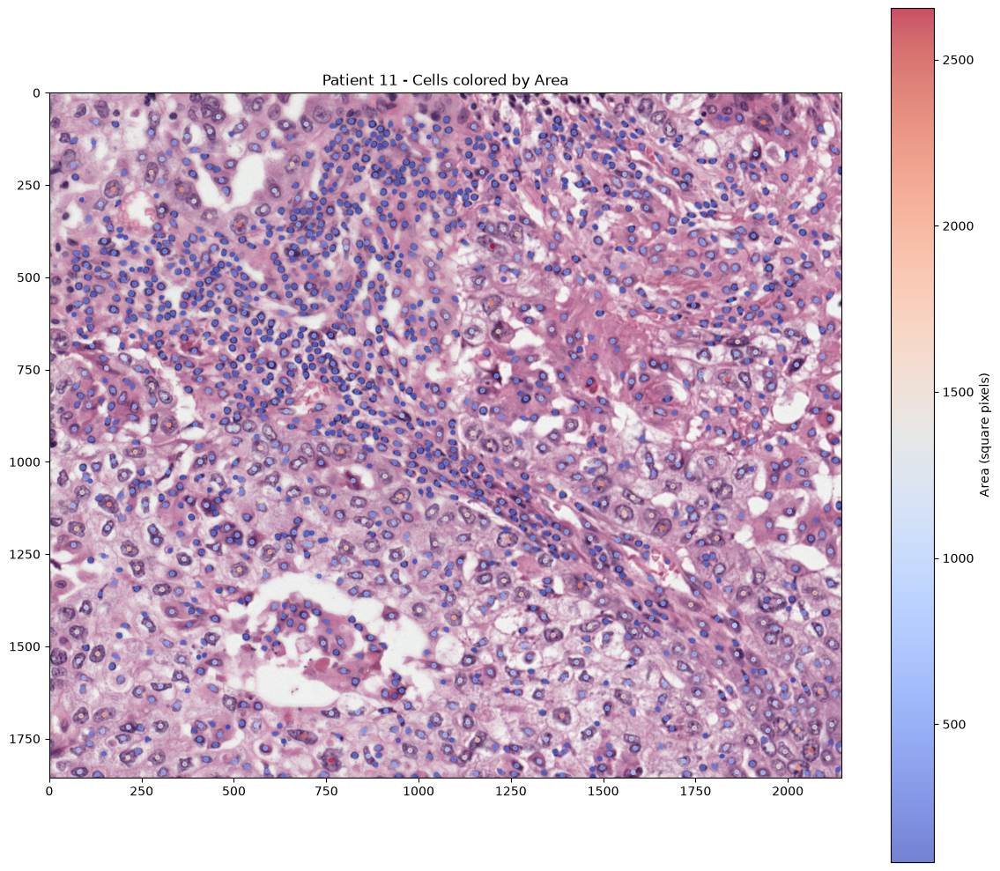

In [7]:
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img)
#creates canvas & draws H&E img in background
#fig & ax to create new plot

scatter = ax.scatter(df1['x'], df1['y'], 
                     c=df1['area'], 
                     cmap='coolwarm', 
                     s=10, 
                     alpha=0.7)
#c=df1['eccentricity'] -> plot based on area

plt.colorbar(scatter, ax=ax, label='Area (square pixels)')
ax.set_title('Patient 11 - Cells colored by Area')
plt.tight_layout()
plt.show()
#colorlabel bar updated to be based on area -> based on square pixel size

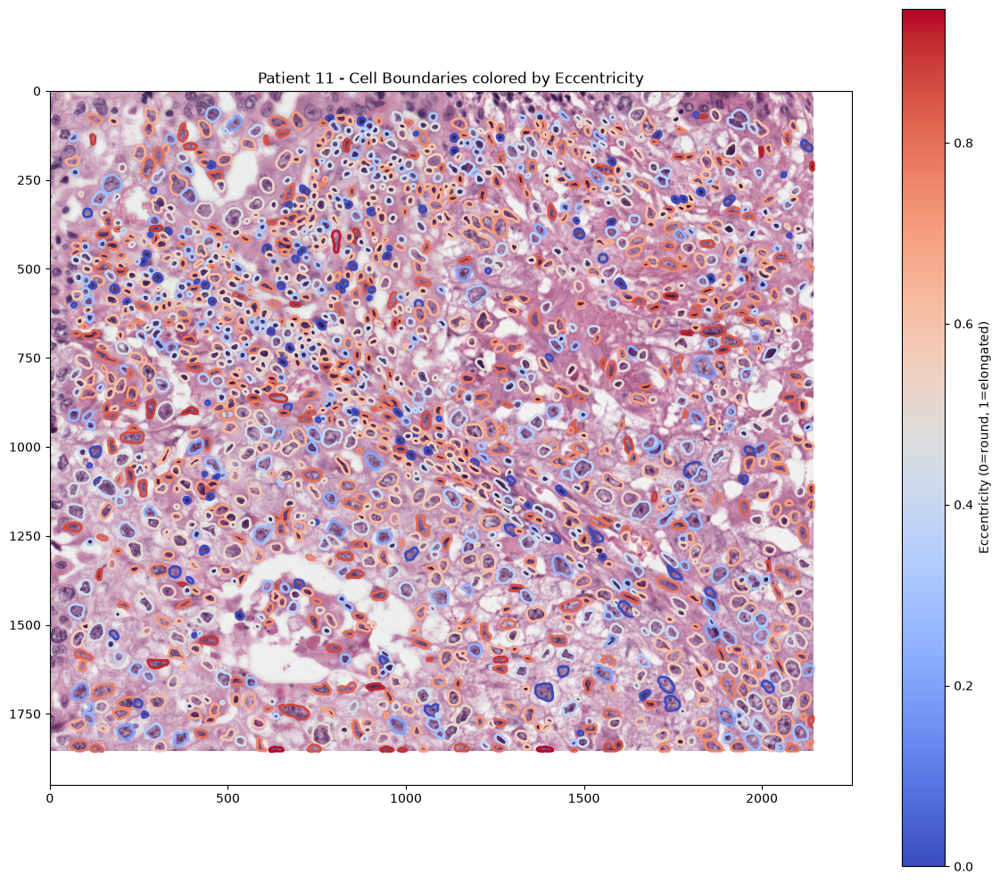

In [8]:
#patient 11 eccentricity visualization

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
#imports mcolors

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img)
#creares blank canvas then draws H&E image on it as background layer

norm = mcolors.Normalize(vmin=df1['eccentricity'].min(), vmax=df1['eccentricity'].max())
cmap = cm.coolwarm
#sets up color scale & normalizes eccentricity values to put into color map
#coolwarm creates color scheme as seen in legend

patches = []
colors = []

for _, row in df1.iterrows():
    polygon = MplPolygon(row['polygon'], closed=True)
    patches.append(polygon)
    colors.append(row['eccentricity'])
#loops through every row in dataframe so every cell converts into matplotlib Polygon object -> can be drawn on plot
#each polygon is in patches
#corresponding eccentricity value in colors

collection = PatchCollection(patches, cmap=cmap, norm=norm, alpha=1.0)
collection.set_array(np.array(colors))
collection.set_facecolor('none')
collection.set_linewidth(2.0)  # thicker lines
ax.add_collection(collection)
#PatchCollection bundles all polygons into one object -> matplotlib doesn't have to draw one by one
#set_array connects polygons so eccentricity value gets right color
#set_facecolor('none') makes inside of polygon transparent -> keeps visual context of H&E image
#set_lindewidth(2.0) makes outline thick enough to see
#add_collection puts this onto plot

plt.colorbar(collection, ax=ax, label='Eccentricity (0=round, 1=elongated)')
ax.set_title('Patient 11 - Cell Boundaries colored by Eccentricity')
plt.tight_layout()
plt.show()
#adds color legend
#sets title
#corrects spacing
#sets up final plot

In [9]:
#patient 11 darkness stats

import cv2
#OpenCV library used for extracting pixel values inside each cell's polygon boundary

#load image as numpy array for pixel access
img_array = cv2.imread(os.path.expanduser("data/patient11_he_roi4.png"))
img_array = cv2.cvtColor(img_array, cv2.COLOR_BGR2RGB)  # convert from (OpenCV standard) BGR (blue, green, red) to RGB (red, green, blue)
#cv2.imread loads PNG img as numpy array of pixel values
#cv2.cvtColor changes color channel values to correct order

def compute_intensity_features(polygon, image):
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
#creates black img (all 0s) with same w&h as H&E img
    #image.shape[:2] takes w&h dimensions (doesn't inc color channels)
    #dtype=np.uint8 means each value is an integer between 0 and 255
    
    #convert polygon coordinates to integer numpy array for cv2
    pts = np.array(polygon, dtype=np.int32)
    cv2.fillPoly(mask, [pts], 1)
#pt2 converts polygon coord list into numpy array of integers (OpenCV format)
#cv2.fillPoly fills polygon shape on mask w/1 (0s everywhere except inside the cells boundary (1))  
        
    #extract pixels inside the polygon
    pixels = image[mask == 1]
#uses mask as a filter to extract only pixels from real H&E img that are inside the cell boundary
    #mask == 1 creates grid that's True inside polygon & False everywhere else
    #image[mask == 1] pulls out True pixels 
#pixels = list of all RBG color values f/every pixel inside cell
    
    if len(pixels) == 0:
        return None, None, None
#makes sure no pixes found inside polygon
    
    mean_intensity = pixels.mean()
#mean_intensity averages all pixel values of 3 color channels f/every pizel in cell -> gives you one number (0=dark, 255=bright)
    
    #Hematoxylin channel approximation - high blue/purple = dark nucleus
    #In RGB: dark purple nuclei have low red, low green, higher blue
    mean_red = pixels[:, 0].mean()
    mean_blue = pixels[:, 2].mean()
#pixels[:, 0] extracts 1st col of pixel array - red channel value f/every pixel
#pixels[:, 2] extracts blue channel
#avg seperately so look at color composition independently
    #dark purple nuclei = low red & high blue
    #pink eosin stained cytoplasm = high red & low blue
    
    darkness = 255 - mean_intensity
#darkness score - lower mean intensity = darker = more hyperchromatic
    #higher darkness = dark/hyperchromatic
    #lower darkness = lightly stained

    return mean_intensity, darkness, mean_red

# Apply to all cells in df1
df1[['mean_intensity', 'darkness', 'mean_red']] = df1['polygon'].apply(
    lambda p: pd.Series(compute_intensity_features(p, img_array))
)
#.apply() runs compute_intensity_features on every polygon in df1
#lambda passes each polygon & img array into f(n) 
#pd.Series converts returned values into 3 col seperated by pandas: mean_intensity, darkness, and mean_red - added into exisiting dataframe

print(df1[['x', 'y', 'area', 'eccentricity', 'mean_intensity', 'darkness', 'mean_red']].head())
print("\nDarkness stats:")
print(df1['darkness'].describe())
#shows 1st 5 rows 
#.describe() shows summary statistics f/darkness 

     x    y    area  eccentricity  mean_intensity    darkness    mean_red
0  639  964   777.5      0.240746      143.220748  111.779252  155.174910
1  572  962  1625.5      0.440079      150.192785  104.807215  160.270846
2  743  965  1091.0      0.308515      131.737515  123.262485  144.433798
3  900  961   667.5      0.574960      126.763517  128.236483  137.753173
4  701  970  1288.5      0.625780      144.852673  110.147327  158.397635

Darkness stats:
count    1684.000000
mean      138.469168
std        20.331997
min        71.997416
25%       122.608685
50%       137.975728
75%       155.836947
max       189.225572
Name: darkness, dtype: float64


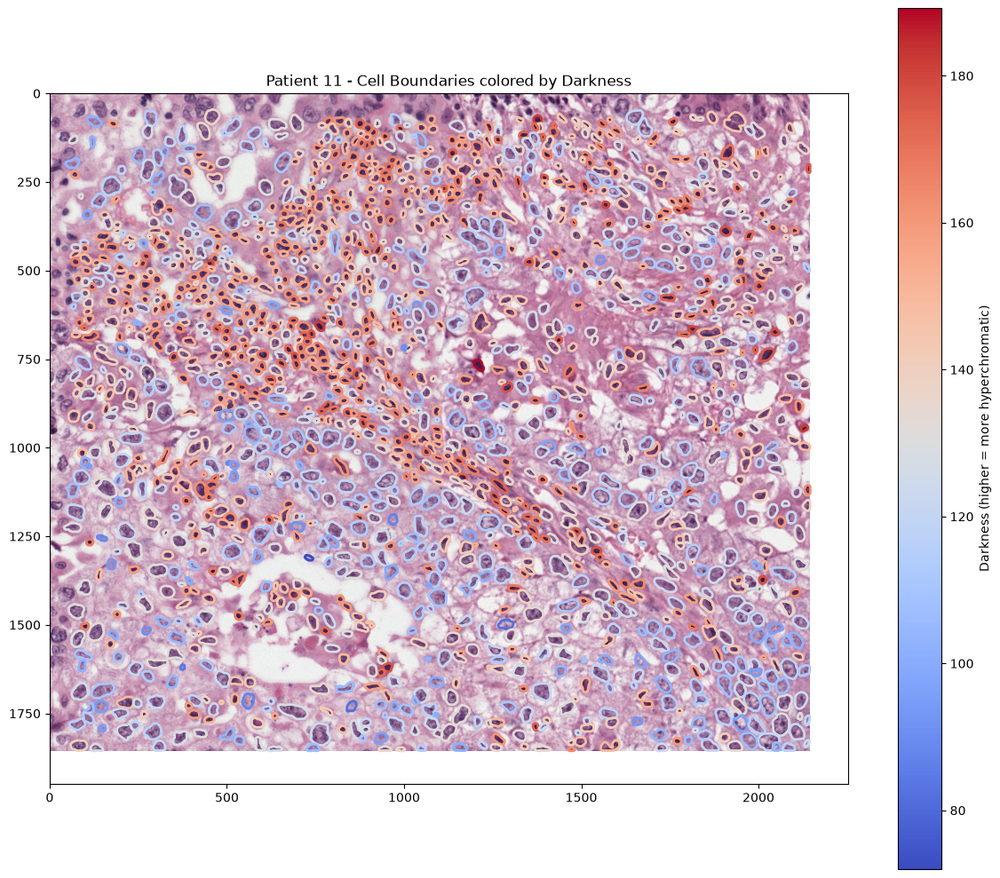

In [10]:
#patient 11 darkness visualization

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img) 
#fresh canvas & H&E img as background layer

norm = mcolors.Normalize(vmin=df1['darkness'].min(), vmax=df1['darkness'].max())
cmap = cm.coolwarm
#normalizing darkness values & maps out darkness range (72-189 onto 0-1) for colormap

patches = []
colors = []

for _, row in df1.iterrows():
    polygon = MplPolygon(row['polygon'], closed=True)
    patches.append(polygon)
    colors.append(row['darkness'])
#goes thru every cell -> polygon coord. -> matplotlib shape & stores it in patches
#key change: row['darkness'] instead of row['eccentricity']
#colors stores cells darkness instead of eccentricity

collection = PatchCollection(patches, cmap=cmap, norm=norm, alpha=1.0)
collection.set_array(np.array(colors))
collection.set_facecolor('none')
collection.set_linewidth(2.0)
ax.add_collection(collection)
#puts all polygons into 1 collection
#maps darkness values to colors
#makes interior transparent
#sets line thickness to 2
#add everything into plot

plt.colorbar(collection, ax=ax, label='Darkness (higher = more hyperchromatic)')
ax.set_title('Patient 11 - Cell Boundaries colored by Darkness')
plt.tight_layout()
plt.show()
#label & title for darkness
#colorbar: blue (~72, lightly stained) to red (~189, heavily stained/hyperchromatic)

Patient 12 features computed:
     x     y    area  eccentricity  mean_intensity    darkness    mean_red
0  514  1862  2605.0      0.309745      106.561169  148.438831  116.062036
1  770  1858   732.5      0.508417      121.647436  133.352564  140.476923
2  424  1866   633.0      0.644379       92.342688  162.657312  105.740030
3  397  1865   588.0      0.632949       90.661376  164.338624  103.679365
4  412  1893   471.0      0.628539      110.103675  144.896325  126.007874

Area stats:
count    2224.000000
mean      545.300135
std       347.416318
min        83.500000
25%       294.250000
50%       468.500000
75%       682.125000
max      2605.000000
Name: area, dtype: float64

Darkness stats:
count    2224.000000
mean      161.235711
std        19.074670
min        80.007246
25%       149.422095
50%       163.824728
75%       174.897854
max       212.031532
Name: darkness, dtype: float64


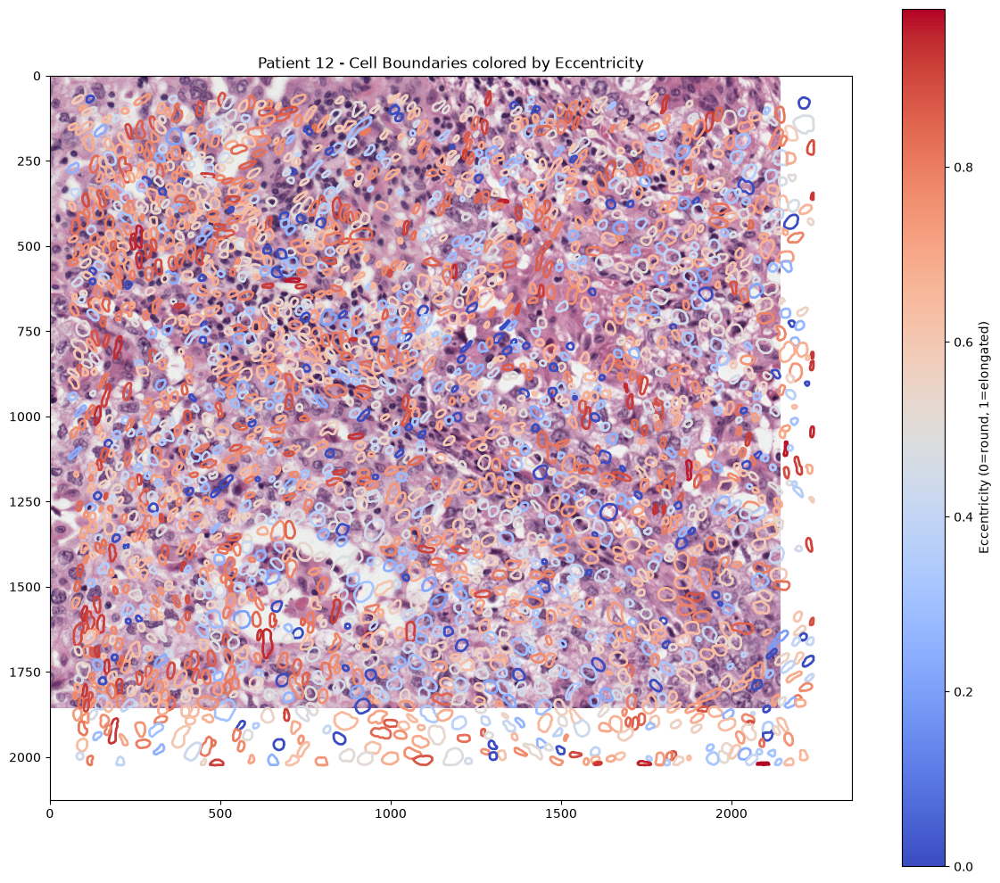

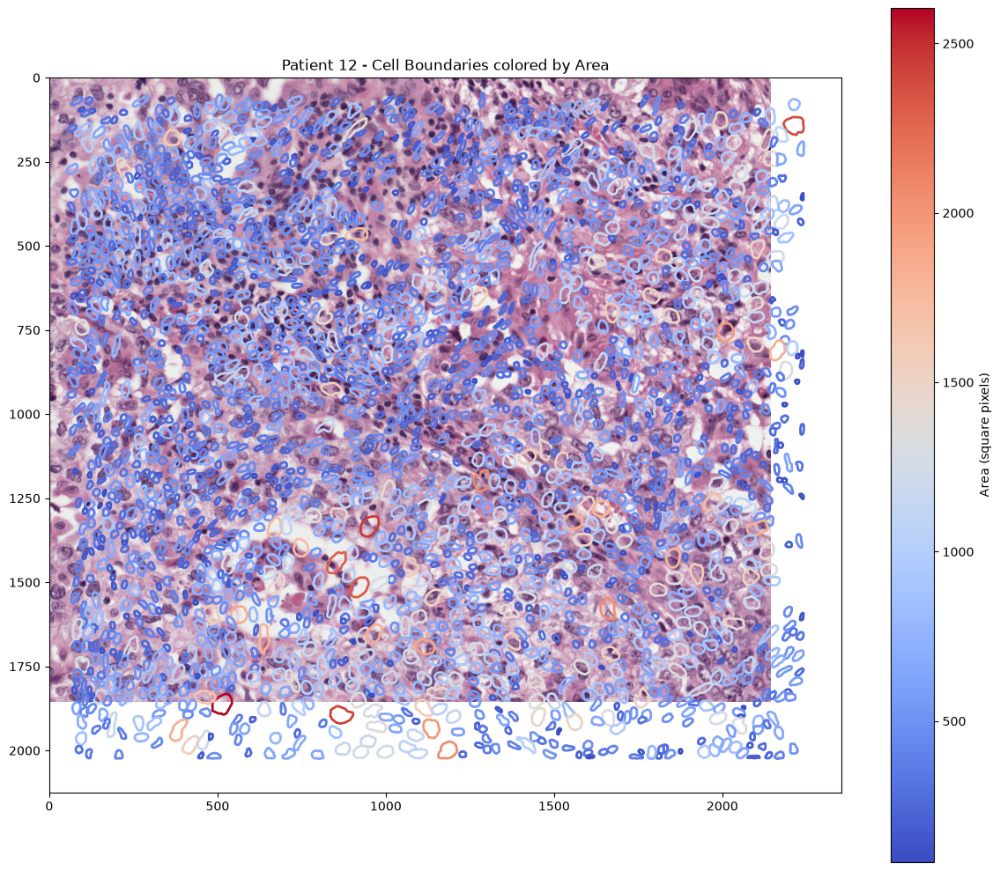

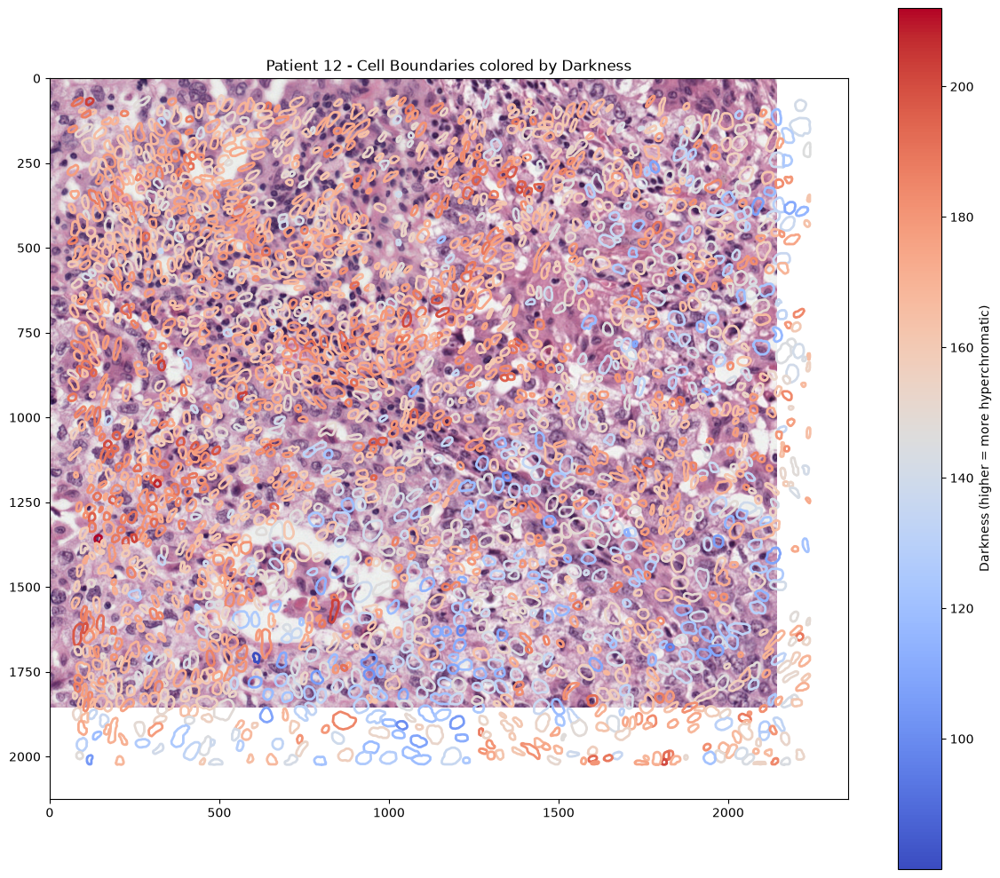

In [11]:
#patient 12 area, eccentricity, & darkness

img2 = mpimg.imread(os.path.expanduser("data/patient11_he_roi4.png"))
img2_array = cv2.imread(os.path.expanduser("data/patient12_he_roi2.png"))
img2_array = cv2.cvtColor(img2_array, cv2.COLOR_BGR2RGB)
#load patient 12 image

df2['area'] = df2['polygon'].apply(compute_area)
df2['eccentricity'] = df2['polygon'].apply(compute_eccentricity)
#find area and eccentricity for patient 12

df2[['mean_intensity', 'darkness', 'mean_red']] = df2['polygon'].apply(
    lambda p: pd.Series(compute_intensity_features(p, img2_array))
)
#find intensity features for patient 12

print("Patient 12 features computed:")
print(df2[['x', 'y', 'area', 'eccentricity', 'mean_intensity', 'darkness', 'mean_red']].head())
print("\nArea stats:")
print(df2['area'].describe())
print("\nDarkness stats:")
print(df2['darkness'].describe())

#all three features for patient 12
for feature, label in [
    ('eccentricity', 'Eccentricity (0=round, 1=elongated)'),
    ('area', 'Area (square pixels)'),
    ('darkness', 'Darkness (higher = more hyperchromatic)')
]:
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(img2)
    
    norm = mcolors.Normalize(vmin=df2[feature].min(), vmax=df2[feature].max())
    patches = []
    colors = []
    
    for _, row in df2.iterrows():
        polygon = MplPolygon(row['polygon'], closed=True)
        patches.append(polygon)
        colors.append(row[feature])
    
    collection = PatchCollection(patches, cmap=cm.coolwarm, norm=norm, alpha=1.0)
    collection.set_array(np.array(colors))
    collection.set_facecolor('none')
    collection.set_linewidth(2.0)
    ax.add_collection(collection)
    
    plt.colorbar(collection, ax=ax, label=label)
    ax.set_title(f'Patient 12 - Cell Boundaries colored by {feature.capitalize()}')
    plt.tight_layout()
    plt.show()

In [12]:
#patient 11 finds neighbors & calculates entropy
from scipy.stats import entropy as scipy_entropy
from scipy.stats import entropy
from scipy.spatial import KDTree
import numpy as np
#imports entropy: function for computing entropy from probability distribution
#KDTree: data structure that looks up spatial neighbors very quickly
    #instead of comparing cells individually -> puts into tree structure -> find all cells within given radius
#numpy: basic calculations

def compute_entropy_fast(df, sigma=75):
    coords = df[['x', 'y']].values
    eccentricities = df['eccentricity'].values
    tree = KDTree(coords)
#coords take centroid positions of cells & puts into numpy array -> makes KDTree -> looking @ neighbors = quick
#eccentricities takes out all eccentricity values as numpy array -> index later
    
    #all neighbor pairs @ once
    sparse_matrix = tree.sparse_distance_matrix(tree, max_distance=sigma, output_type='coo_matrix')
#finds all neighbor pairs within radius at once & puts them into sparse matrix
    #sparse matrix only stores non 0 values only inc pairs of cells that are within 75 pixels of each other -> saves memory
#coo_matrix stores data three arrays: row indices, column indices, and distances
    
    entropies = np.zeros(len(df))
#empty array of 0s w/1 slot per cell to store cells entropy value as you compute
#checks cell neighbors
    
    for i in range(len(df)):
        # Get neighbors of cell i from sparse matrix
        neighbors = sparse_matrix.col[sparse_matrix.row == i]
        neighbors = neighbors[neighbors != i]
#loops through each cell one at a time 
#sparse_matrix.row == i: finds all entries in left col. where source cell is cell i -> filters down to rows w/cell i
#sparse_matrix.col: gives the correct col. of those rows -> actual neighbor indices
#neighbors != 1: makes sure matrix doesnt inc cell paired w itself -> dont wanna include in eccentricity value
        
        if len(neighbors) < 2:
            entropies[i] = 0
            continue
#if cell has less than 2 neighbors within radius -> entropy = 0 & skip to next cell (need 2+ values for value to have meaning)
        
        neighbor_eccs = eccentricities[neighbors]
        hist, _ = np.histogram(neighbor_eccs, bins=10, range=(0, 1))
        hist = hist / hist.sum()
        hist = hist + 1e-10
        entropies[i] = scipy_entropy(hist)
#neighbor_eccs: gets ecc of all neighboring cells
#np.histogram: puts ecc values into categories (10 between 0-1 -> 0.1, 0.2, ...)
#hist / hist.sum(): normalizes histogram (probability dist. adds up to 1)
#1e-10: prevents errors in entropy calculation
#entropy(hist): computes dist. -> high ecc if spread across many bins & low in all in 1 bin 
    
    return entropies
    
df1['entropy'] = compute_entropy_fast(df1, sigma=75)
print("Entropy stats:")
print(df1['entropy'].describe())
#runs f(n) on all cells & stores results in new col. in df1 -> in summary statistics can see range of entropy values

Entropy stats:
count    1684.000000
mean        1.397742
std         0.361018
min         0.000000
25%         1.242453
50%         1.489750
75%         1.667462
max         2.026230
Name: entropy, dtype: float64


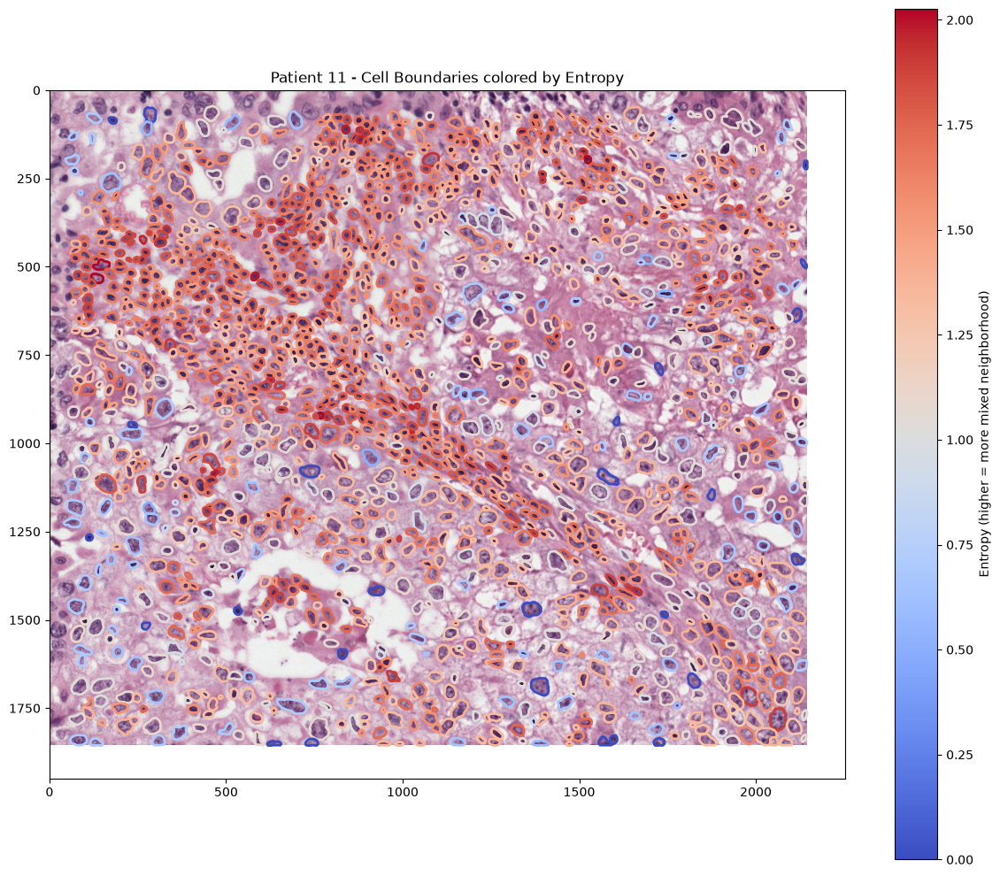

In [13]:
#patient 11 entropy visualization

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img)
#new canvas w/H&E img as background

norm = mcolors.Normalize(vmin=df1['entropy'].min(), vmax=df1['entropy'].max())
cmap = cm.coolwarm
#norm: normalizing entropy -> maps range f/0-1 as scale

patches = []
colors = []

for _, row in df1.iterrows():
    polygon = MplPolygon(row['polygon'], closed=True)
    patches.append(polygon)
    colors.append(row['entropy'])
#patches & colors: 2 empty lists
    #every time new polygon added to patches -> corresponding entropy value added to colors
#loop goes thru each row
#MplPolygon(row['polygon'], closed=True): for each cell takes list of boundary coord f/polygon col. & converts into matplotlib obj -> can be drawn on plot
#closed=True: tells matplotlib to connect first & last point in outline 
#patches.append(polygon): adds drawable shape into patches list
#colors.append(row['entropy']): adds cells entropy val. to colors list @ same position

collection = PatchCollection(patches, cmap=cmap, norm=norm, alpha=1.0)
collection.set_array(np.array(colors))
collection.set_facecolor('none')
collection.set_linewidth(2.0)
ax.add_collection(collection)
#PatchCollection(patches, cmap=cmap, norm=norm, alpha=1.0): takes all patches & bundles then into 1 obj (set of shapes is faster than drawing cells individually)
#cmap=cmap: color scheme
#norm=norm: how to map entropy values onto color scheme
#alpha=1.0: no transparency
#collection.set_array(np.array(colors)): connects polygon to its entropy val.
#collection.set_facecolor('none'): interior of every polygon transparent (don't wanna cover tissue)
#collection.set_linewidth(2.0): thickness of boundary outline (see against H&E background)
#ax.add_collection(collection): places colored outlines on top of H&E img

plt.colorbar(collection, ax=ax, label='Entropy (higher = more mixed neighborhood)')
ax.set_title('Patient 11 - Cell Boundaries colored by Entropy')
plt.tight_layout()
plt.show()

In [14]:
#patient 11 cell density

def compute_cell_density(df, patch_size=100):
    x_min, x_max = df['x'].min(), df['x'].max()
    y_min, y_max = df['y'].min(), df['y'].max()
#gets bounds - leftmost, rightmost, topmost, & bottommost cell coord.
    #tells you full region of tissue
    
    x_bins = np.arange(x_min, x_max + patch_size, patch_size)
    y_bins = np.arange(y_min, y_max + patch_size, patch_size)
#divides tissue in 100x100 pixel patch grid - grid of patches
    #20x magnification
    
    density_map, x_edges, y_edges = np.histogram2d(
        df['x'], df['y'], 
        bins=[x_bins, y_bins]
    )
#num. of centroids inside each patch -> stored as 2d grid
    #ex. 12 cells center point 100x100 -> patch density = 12
    
    x_idx = np.digitize(df['x'], x_edges[:-1]) - 1
    y_idx = np.digitize(df['y'], y_edges[:-1]) - 1
    
    x_idx = np.clip(x_idx, 0, density_map.shape[0] - 1)
    y_idx = np.clip(y_idx, 0, density_map.shape[1] - 1)
#figure out which cell belongs to which patch (finding position in grid)
    #np.digitize: which bin coord. goes to
    #np.clip: makes sure index doesn't go out of bounds f/cell near edge - makes valid range
    
    densities = density_map[x_idx, y_idx]
    return densities
#looks up density value of cells patch & assigns it to the cell
#every cell gets num. of how many cells also in 100x100 neighborhood

df1['cell_density'] = compute_cell_density(df1, patch_size=100)

print("Cell density stats:")
print(df1['cell_density'].describe())

Cell density stats:
count    1684.000000
mean        6.022565
std         2.989896
min         1.000000
25%         4.000000
50%         5.000000
75%         8.000000
max        14.000000
Name: cell_density, dtype: float64


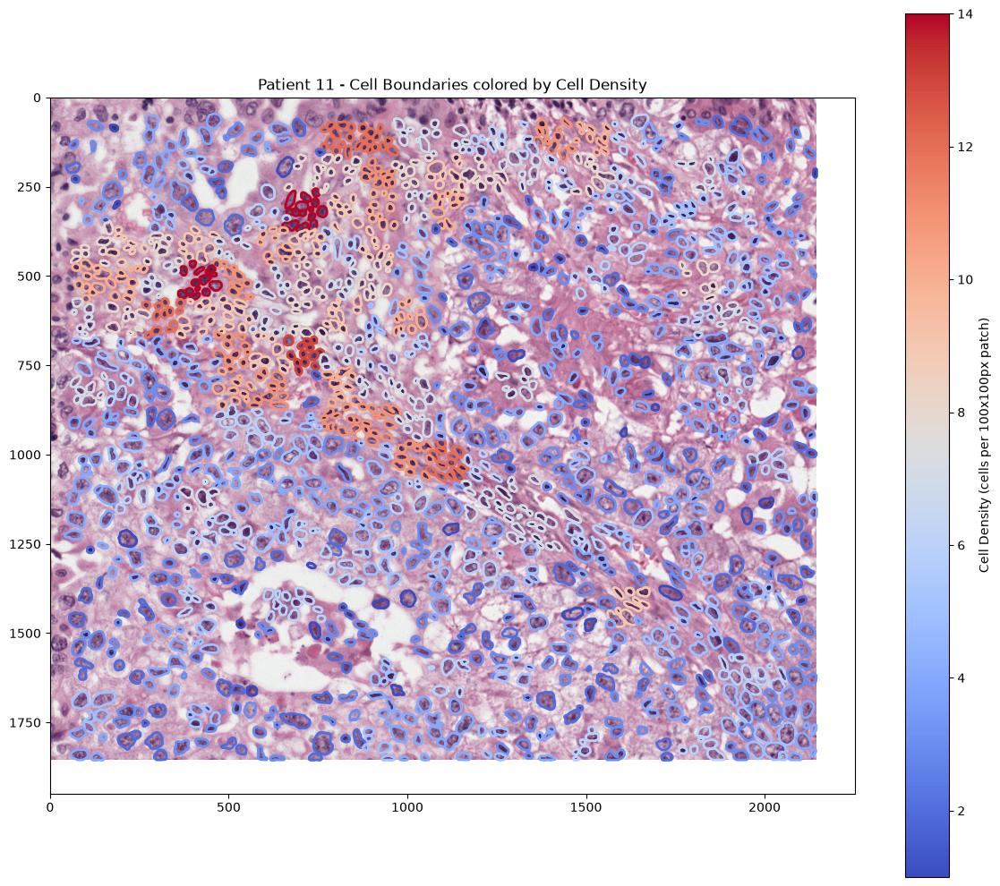

In [15]:
#patient 11 cell density visualization

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img)
#fresh slide w/H&E background image

norm = mcolors.Normalize(vmin=df1['cell_density'].min(), vmax=df1['cell_density'].max())
cmap = cm.coolwarm
#normalizing cell density values - range 1 to 14 -> 0 to 1 scale f/colormap

patches = []
colors = []

for _, row in df1.iterrows():
    polygon = MplPolygon(row['polygon'], closed=True)
    patches.append(polygon)
    colors.append(row['cell_density'])
#convert each cells polygon into drawable shape
    #polygon gets colored by number of cells in local 100x100 patch

collection = PatchCollection(patches, cmap=cmap, norm=norm, alpha=1.0)
collection.set_array(np.array(colors))
collection.set_facecolor('none')
collection.set_linewidth(2.0)
ax.add_collection(collection)
#puts all polygons into 1 collection
#maps density values to colors
#makes interior transparent
#sets line thickness to 2
#add everything into plot

plt.colorbar(collection, ax=ax, label='Cell Density (cells per 100x100px patch)')
ax.set_title('Patient 11 - Cell Boundaries colored by Cell Density')
plt.tight_layout()
plt.show()
#plot & label graph

In [16]:
#patient 11 nearest neighbor distance

from scipy.spatial import KDTree
#import KDTree: data structure that looks up spatial neighbors very quickly

def compute_nearest_neighbor_distance(df):
    coords = df[['x', 'y']].values
    tree = KDTree(coords)
#takes all cell centroid positions & puts into numpy array 
#KDTree spatial index (make KDTree of all cells) -> find cell neighbors quickly
    
    distances, _ = tree.query(coords, k=2)
#tree.query: f/each cell find k nearest neighbors & return  distances
#k=2: find 2 closest cells (bc cell will choose itself as the closest cell)
    #only finding distances here
    
    # Take the second column (index 1) which is the actual nearest neighbor distance
    nn_distances = distances[:, 1]
#2nd col. of distance array col. @ index 1 
    #has distance for nearest neighbor f/every cell (not self distance = col 0)
    
    return nn_distances

df1['nn_distance'] = compute_nearest_neighbor_distance(df1)

print("Nearest neighbor distance stats:")
print(df1['nn_distance'].describe())
#runs compute_nearest_neighbor_distance on all cells 
#stores results in new col.
#prints summary statistics (see range)

Nearest neighbor distance stats:
count    1684.000000
mean       29.835744
std        10.285929
min         0.000000
25%        22.022716
50%        27.757869
75%        35.777088
max        75.591005
Name: nn_distance, dtype: float64


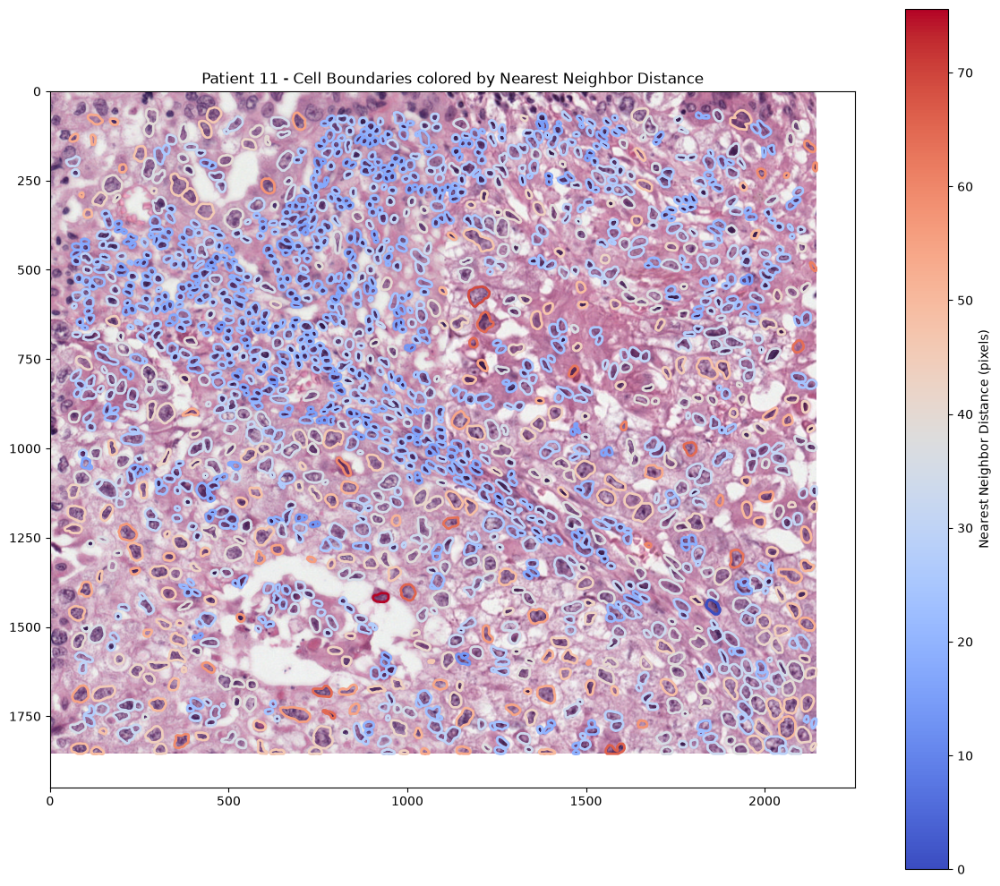

In [17]:
#patient 11 nearest neighbor distance visualization

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img)
#fresh slide w/H&E background image

norm = mcolors.Normalize(vmin=df1['nn_distance'].min(), vmax=df1['nn_distance'].max())
cmap = cm.coolwarm
#normalize values - pixel range 0 to 75.6 -> 0 to 1 scale f/colormap

patches = []
colors = []

for _, row in df1.iterrows():
    polygon = MplPolygon(row['polygon'], closed=True)
    patches.append(polygon)
    colors.append(row['nn_distance'])
#convert each cells polygon into drawable shape
#stores nearest neighbor distance in colors 
    #shorter distance = blue; long distance = red
#row['nn_distance']: tells you how many away pixels nearest cell is 

collection = PatchCollection(patches, cmap=cmap, norm=norm, alpha=1.0)
collection.set_array(np.array(colors))
collection.set_facecolor('none')
collection.set_linewidth(2.0)
ax.add_collection(collection)
#puts all polygons into 1 collection
#maps distances to colors
#makes interior transparent
#sets line thickness to 2
#add everything into plot

plt.colorbar(collection, ax=ax, label='Nearest Neighbor Distance (pixels)')
ax.set_title('Patient 11 - Cell Boundaries colored by Nearest Neighbor Distance')
plt.tight_layout()
plt.show()
#plot & label graph

In [18]:
#patient 11 batch coding shape features: perimeter, compactness, & solidity 

from shapely.geometry import Polygon
import numpy as np
#import polygon for geometry
#import numpy for math calculations

#feature 1: perimeter
def compute_perimeter(polygon):
    return Polygon(polygon).length
#compute_perimeter: converts polygon boundary coord. into shapely polygon obj & returns perimeter (in pixels)

#feature 2: compactness
def compute_compactness(polygon):
    poly = Polygon(polygon)
    if poly.area == 0:
        return 0
    return (4 * np.pi * poly.area) / (poly.length ** 2)
#compute_compactness: measures how close to a perfect circle cell is (0 - 1 = irregular - circle)
    #score 1 when cell has max area f/perimeter
    #more irregular shape -> lower score
#if poly.area == 0: stops code from breaking when error
    #ecc = elongation; compactness = overall irregularity

#feature 3: soliditiy
def compute_solidity(polygon):
    poly = Polygon(polygon)
    convex_hull = poly.convex_hull
    if convex_hull.area == 0:
        return 0
    return poly.area / convex_hull.area
#compute_solidity: compares actual cell area to smallest shape that can enclose cell (convex hull
    #score 1 - perfectly curved (convex); lower = cell boundary has dips/irregular edges (concavities)
        #lower score common in tumor cells
# if convex_hull.area == 0: stops code from breaking when error   

df1['perimeter'] = df1['polygon'].apply(compute_perimeter)
df1['compactness'] = df1['polygon'].apply(compute_compactness)
df1['solidity'] = df1['polygon'].apply(compute_solidity)
#runs each f(n) across all cells & stores output in new col.

print("Shape feature stats:")
print(df1[['perimeter', 'compactness', 'solidity']].describe())

Shape feature stats:
         perimeter  compactness     solidity
count  1684.000000  1684.000000  1684.000000
mean     85.830116     0.831131     0.966711
std      29.152855     0.083071     0.027040
min      34.384776     0.360029     0.691729
25%      65.492715     0.793671     0.959489
50%      78.444083     0.851643     0.972973
75%     102.797490     0.889707     0.982621
max     230.930416     0.962661     1.000000


In [19]:
#patient 11 batch 2 - Intensity features

def compute_intensity_features_batch2(polygon, image):
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
    pts = np.array(polygon, dtype=np.int32)
    cv2.fillPoly(mask, [pts], 1)
    pixels = image[mask == 1]
    
    if len(pixels) == 0:
        return None, None, None
#creates black img (all 0s) with same w&h as H&E img
#fill in cells polygon boundary w/1s
    #extract only pixels inside boundary
#if len(pixels) == 0: prevents code f/crashing

#mean blue measures how much hematoxylin-stained material is in the cell -> high blue = dense nucleus = likely tumor or immune cell
    mean_blue = pixels[:, 2].mean()
#extracts blue channel (col. index 2) f/every pixel inside cell & averages
#H&E staining hematoxylin binds to DNA in nucleus & stains it dark purple blue
    #cells w/dense chromatin (tumor cells or immune cells w/compact nuclei) have higher blue channel values (dark purple nuclei = high blue) than stromal cells
    
#mean green (middle channel) complete picture -> not useful on it's own but when combined w/red & blue identify cell types more precisely 
    mean_green = pixels[:, 1].mean()
#extracts green channel (col. index 1)
    #green helps differentiate tissue components -> paints full picture when given red & blue
    
#intensity standard deviation avg all 3 channels into brightness val/pixel -> measures how consistent brightness is across all pixels in cell
    #how varied staining is within the cell 
    intensity_std = pixels.mean(axis=1).std()
#avg 3 color channels -> one brightness val./pixel: pixels.mean(axis=1)
#then sd of brightness val. 
    #low sd = cells stained uniformly
    #high sd = uneven staining internally -> can be irregular chromatin dist. = feat. of aggressive tumor cells
    
    return mean_blue, mean_green, intensity_std

df1[['mean_blue', 'mean_green', 'intensity_std']] = df1['polygon'].apply(
    lambda p: pd.Series(compute_intensity_features_batch2(p, img_array))
)
#runs f(n) on every polygon -> returns 3 vals. per cell -> pd.Series splits into 3 cols.

print("Intensity feature stats:")
print(df1[['mean_blue', 'mean_green', 'intensity_std']].describe())

Intensity feature stats:
         mean_blue   mean_green  intensity_std
count  1684.000000  1684.000000    1684.000000
mean    132.483070    89.042910      20.154919
std      17.846085    20.564503       5.466277
min      81.891122    38.591290       3.974801
25%     118.394799    71.832166      16.533835
50%     132.797668    88.618629      20.161054
75%     145.952116   104.229904      23.721174
max     191.410853   165.899225      41.475107


In [20]:
#batch 3 - spatial features: mean k distances & isolation scores

from scipy.spatial import KDTree
#KDTree: data structure that looks up spatial neighbors very quickly
    #instead of comparing cells individually -> puts into tree structure -> find all cells within given radius

def compute_spatial_features_batch3(df, k=5):
    coords = df[['x', 'y']].values
    tree = KDTree(coords)
#extracts cell centroid positions and puts in numpy array -> build spatial index -> look up neighbors quickly
    
    distances, _ = tree.query(coords, k=k+1)
    mean_k_distances = distances[:, 1:].mean(axis=1)
#tree.query(coords, k=k+1): 6 nearest neighbors (k=5+1) -> bc it counts itself as nearest
#distances[:, 1:]: removes self distance col. -> in ex. before only 5 neighbors
#.mean(axis=1): avg those 5 distances for each cell
    
    # Cell isolation score - inverse of local density
    # Higher score = more isolated cell
    isolation_scores = 1 / (df['cell_density'].values + 1)
#density val. f/batch 1 & inverts (adds 1 before dividing bc prevents division by 0 if cell density = 0)
    #cell in dense patch gets lower isolation score 
    #isolation score opposite of density
    
    return mean_k_distances, isolation_scores

mean_k_dist, isolation = compute_spatial_features_batch3(df1, k=5)

df1['mean_k_distance'] = mean_k_dist
df1['isolation_score'] = isolation
#stores arrays as new cols. in dataframe (one val. per cell f/each feat.)

print("Spatial feature stats:")
print(df1[['mean_k_distance', 'isolation_score']].describe())

Spatial feature stats:
       mean_k_distance  isolation_score
count      1684.000000      1684.000000
mean         45.792411         0.172295
std          12.985561         0.080749
min          21.640141         0.066667
25%          35.285869         0.111111
50%          44.276042         0.166667
75%          53.847047         0.200000
max          95.723832         0.500000


In [21]:
#batch 4 - Nuclear texture features using GLCM
from skimage.feature import graycomatrix, graycoprops
from skimage.color import rgb2gray
from skimage.util import img_as_ubyte
#graycomatrix: builds texture matrix
#graycoprops: extracts properties f/matrix
#rgb2gray: converts colored img to grayscale
#img_as_ubyte: converts to 8 bit integer format (0-255) used for GLCM
def compute_texture_features(polygon, image):
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
    pts = np.array(polygon, dtype=np.int32)
    cv2.fillPoly(mask, [pts], 1)
#creates blank canvas then draws H&E image on it as background layer
#fill in cells polygon boundary w/1s -> isolate pixels in cell
    
    gray_image = img_as_ubyte(rgb2gray(image))
    masked_gray = gray_image * mask
#convert to grayscale
#RGB values into one brightness value per pixel
    #multiply so only pixels inside cell boundary have values (outside = 0)
#bounding box of polygon f/GLCM computation
    minx, miny, maxx, maxy = map(int, Polygon(polygon).bounds)
    minx, miny = max(0, minx), max(0, miny)
    maxx = min(image.shape[1], maxx)
    maxy = min(image.shape[0], maxy)
#crop to bounding box
    region = masked_gray[miny:maxy, minx:maxx]
#smallest rectangle that fits around cell & crops grayscale img to just region
#max(0, ...) & min(image.shape...): keeps coords. within img boundaries (f/cells near edges)
    #GLCM needs 2D img not list of pixels
    
    if region.size == 0 or region.max() == 0:
        return None, None, None
#if cropped region = 0 -> doesn't crash code

    # Reduce to 32 gray levels instead of 256 - much faster
    region_reduced = (region // 8).astype(np.uint8)
#divides each pixel value by 8 -> collapses 256 brightness levels into 32
    #reduces GLCM matrix from 256x256 to 32x32 -> 64x faster
    #still captures same texture info just at lower resolution

#compute GLCM (Gray Level Co-occurrence Matrix)
    glcm = graycomatrix(region_reduced, distances=[1], angles=[0], 
                        levels=32, symmetric=True, normed=True)
#looks @ every pair of adj. pixels in region & records how often combo of brightness vals. appear next to e/a
    #distances=[1]: looking @ immediately adj pixels
    #angles=[0]: looking horizontally 
    #levels=32: using reduced brightness range (was 256, now 32 for speed)
    #symmetric=True: (A,B) = (B,A)
    #normed=True: converting counts -> probabilities
#result: 32x32 matrix w/texture pattern of cells nucleus
    
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
#contrast: measures brightness variance between pixels
    #high contrast = big gaps between brightness among neighbors
#homogeneity: how similar adj pixels are
    #high homogeneity = smooth uniform texture
#energy: how regular & repetitive texture pattern is
    #high energy = consistent repeating pattern
#[0, 0]: gets single val. f/one distance & angle (specified)
    
    return contrast, homogeneity, energy
df1[['contrast', 'homogeneity', 'energy']] = df1['polygon'].apply(
    lambda p: pd.Series(compute_texture_features(p, img_array))
)
print("Texture feature stats:")
print(df1[['contrast', 'homogeneity', 'energy']].describe())

Texture feature stats:
          contrast  homogeneity       energy
count  1684.000000  1684.000000  1684.000000
mean     14.364391     0.677284     0.255289
std       4.671726     0.074356     0.062135
min       4.197861     0.405371     0.126487
25%      11.107703     0.628564     0.212983
50%      13.703138     0.682736     0.242277
75%      16.814829     0.727885     0.284944
max      39.333333     0.865539     0.629200


In [22]:
!pip install scikit-image

In [23]:
#patient 11 batch 5 - shape completeness features

def compute_shape_completeness(polygon):
    poly = Polygon(polygon)
    convex_hull = poly.convex_hull
#compute_shape_completeness: converts polygon coord into polygon obj
#convex_hull: smallest convex shape that wraps around cell - using it as perimeter 

    if poly.length == 0:
        convexity = 0
    else:
        convexity = convex_hull.length / poly.length
#convexity: divides convex hull perimeter/actual cell perimeter
    #if cell smooth & convex boundary = actual perimeter -> convexity = 1
    #if cell has irregularities & actual perimeter longer than convex hull perimeter -> convexity<1
#if poly.length == 0: makes sure code doesn't break
    
    minx, miny, maxx, maxy = poly.bounds
    width = maxx - minx
    height = maxy - miny
    if min(width, height) == 0:
        elongation = 0
    else:
        elongation = max(width, height) / min(width, height)
#gets bounding box of cell (smallest rectangle that fits around it) -> computes height & width 
#elongation: ratio of longer to shorter
    #circle elongation = 1
    #very elongated cell = 3
        #uses bounding box dimensions not polygon geometry
#if min(width, height) == 0: makes sure code doesn't break
    
    equiv_diameter = np.sqrt(4 * poly.area / np.pi)
#finds diameter circle would need to have same area as cell
    #instead of saying area = 500 sq. pixels -> say diameter = 25 sp. pixels
    
    return convexity, elongation, equiv_diameter

df1[['convexity', 'elongation', 'equiv_diameter']] = df1['polygon'].apply(
    lambda p: pd.Series(compute_shape_completeness(p))
)

print("Shape completeness stats:")
print(df1[['convexity', 'elongation', 'equiv_diameter']].describe())
#runs f(n) acorss all cells & stores in 3 cols.

Shape completeness stats:
         convexity   elongation  equiv_diameter
count  1684.000000  1684.000000     1684.000000
mean      0.979965     1.277159       24.831421
std       0.015496     0.260441        8.388785
min       0.764207     1.000000       10.372499
25%       0.973200     1.095238       19.145072
50%       0.981667     1.200000       22.827029
75%       0.990021     1.381303       29.502853
max       1.000000     3.142857       58.147120


In [24]:
#patient 11 rule based cell type identification

from scipy.stats import zscore

def normalize(series):
    return (series - series.min()) / (series.max() - series.min())
#for feat. cols. make scale 0-1

area_norm = normalize(df1['area'])
ecc_norm = normalize(df1['eccentricity'])
dark_norm = normalize(df1['darkness'])
compact_norm = normalize(df1['compactness'])
elong_norm = normalize(df1['elongation'])
#scales most meaningful feats. to 0-1

#immune identifiers: small, round, dark, compact
immune_score = (
    (1 - area_norm) * 0.3 +      #small cells
    (1 - ecc_norm) * 0.3 +       #round cells
    dark_norm * 0.2 +             #dark cells
    compact_norm * 0.2            #compact cells
)
#finds immune score f/each cell based on most telling factors of immune cells
    #weighted (0.2 & 0.3) based on how much they contribute - strongest discriminators between immune & other cells

#tumor identifiers: irregular, dark, low compactness
tumor_score = (
    area_norm * 0.3 +             #large area
    ecc_norm * 0.25 +             #elongated/irregular
    dark_norm * 0.25 +            #dark
    (1 - compact_norm) * 0.2      #irregular shape
)
#finds tumor score f/each cell based on most telling factors of tumor cells
    #weighted (0.2 & 0.25 & 0.3) based on how much they contribute - strongest discriminators between immune & other cells

#stromal identifiers: med. area, very elongated, lightly stained
stromal_score = (
    elong_norm * 0.4 +            # elongated/spindle shaped
    (1 - dark_norm) * 0.4 +       # lightly stained
    (1 - ecc_norm) * 0.2          # moderate shape
)
#finds stromal score f/each cell based on most telling factors of stromal cells
    #high elongation & low darkness weighted heavily (0.4) bc spindle shapes & lightly stained (most distinct stromal feat.)

total = immune_score + tumor_score + stromal_score
df1['prob_immune'] = immune_score / total
df1['prob_tumor'] = tumor_score / total
df1['prob_stromal'] = stromal_score / total
#converts scores into probabilities (dividing by total -> sum to 1)

df1['cell_type'] = df1[['prob_immune', 'prob_tumor', 'prob_stromal']].idxmax(axis=1)
df1['cell_type'] = df1['cell_type'].map({
    'prob_immune': 'immune',
    'prob_tumor': 'tumor',
    'prob_stromal': 'stromal'
})
#idxmax(axis=1): finds which col. has highest val. f/each row
    #type w/highest probability = cell type
#.map(): converts col. names -> clean readable labels

print("Cell type distribution:")
print(df1['cell_type'].value_counts())
#shows how many cells identified per type
print("\nProbability stats:")
print(df1[['prob_immune', 'prob_tumor', 'prob_stromal']].describe())

Cell type distribution:
cell_type
immune     1573
tumor        97
stromal      14
Name: count, dtype: int64

Probability stats:
       prob_immune   prob_tumor  prob_stromal
count  1684.000000  1684.000000   1684.000000
mean      0.483500     0.282884      0.233617
std       0.074157     0.063916      0.055218
min       0.196229     0.070673      0.092316
25%       0.433419     0.242905      0.186894
50%       0.487245     0.286101      0.235977
75%       0.539507     0.326197      0.274229
max       0.645223     0.521098      0.415212


In [25]:
#patient 11 cell type specific spatial features

def compute_celltype_features(df, patch_size=100):
    
    immune_cells = df[df['cell_type'] == 'immune'][['x', 'y']].values
    tumor_cells = df[df['cell_type'] == 'tumor'][['x', 'y']].values
#filters dataframe by cell type and extracts x&y coord f/immune and tumor cells seperately
    #immune_cells: array of 1573 coord. pairs
    #tumor_cells: array of 97 coord. pairs
        #spatial calculations on each cell type independtly 
    
    x_min, x_max = df['x'].min(), df['x'].max()
    y_min, y_max = df['y'].min(), df['y'].max()
    x_bins = np.arange(x_min, x_max + patch_size, patch_size)
    y_bins = np.arange(y_min, y_max + patch_size, patch_size)
#sets up 100x100 pixel grid as cell density feature
#x_min, x_max & y_min, y_max: find spatial boundaries of tissue
#np.arange: divides into bins of 100 pixels in both directions
    #can compare immune & tumor denisty patches to cell density patches
    
    immune_density_map, x_edges, y_edges = np.histogram2d(
        immune_cells[:, 0], immune_cells[:, 1], bins=[x_bins, y_bins]
    )
    tumor_density_map, _, _ = np.histogram2d(
        tumor_cells[:, 0], tumor_cells[:, 1], bins=[x_bins, y_bins]
    )
#np.histogram2d: takes x&y coord. & counts how many points fall into each bin of 2D grid -> classifies which bin the cell goes to
#immune cells & tumor cells seperately in 100x100 pixel patch (patch has immune cell and tumor cell nums. seperately)
    
    x_idx = np.clip(np.digitize(df['x'], x_edges[:-1]) - 1, 0, immune_density_map.shape[0] - 1)
    y_idx = np.clip(np.digitize(df['y'], y_edges[:-1]) - 1, 0, immune_density_map.shape[1] - 1)
    
    df['immune_density'] = immune_density_map[x_idx, y_idx]
    df['tumor_density'] = tumor_density_map[x_idx, y_idx]
#figures our which patch belongs to which cell & assigns it immune and tumor denisty values f/patch
    #cell in dataframe knows num. of immune & tumor cells in local neighborhood
    
    if len(immune_cells) > 0 and len(tumor_cells) > 0:
        immune_tree = KDTree(immune_cells)
        tumor_tree = KDTree(tumor_cells)
#builds 2 KDTrees (immune & tumor) -> ask f/nearest immune or tumor cell
        
        tumor_to_immune_dist, _ = immune_tree.query(tumor_cells, k=1)
        immune_to_tumor_dist, _ = tumor_tree.query(immune_cells, k=1)
#immune_tree.query(tumor_cells, k=1): takes tumor cell & finds neighbor in immune cell tree
#tumor_tree.query(immune_cells, k=1): takes immune cell & finds neighbor in tumor cell tree
        
        df.loc[df['cell_type'] == 'tumor', 'dist_to_nearest_immune'] = tumor_to_immune_dist
        df.loc[df['cell_type'] == 'immune', 'dist_to_nearest_tumor'] = immune_to_tumor_dist
        df['dist_to_nearest_immune'] = df['dist_to_nearest_immune'].fillna(-1)
        df['dist_to_nearest_tumor'] = df['dist_to_nearest_tumor'].fillna(-1)
#puts distances into rows for dataframe
    #tumor cells get distance to nearest immune cell
    #immune cells get distance to nearest tumor cell
#.fillna(-1): fills in -1 f/stromal cells that don't have measurement -> placeholder value that doesn't mess with calculations

    return df

df1 = compute_celltype_features(df1)

print("Immune density stats:")
print(df1['immune_density'].describe())
print("\nTumor density stats:")
print(df1['tumor_density'].describe())

print("\nTumor to immune distance (tumor cells only):")
print(df1[df1['cell_type'] == 'tumor']['dist_to_nearest_immune'].describe())
print("\nImmune to tumor distance (immune cells only):")
print(df1[df1['cell_type'] == 'immune']['dist_to_nearest_tumor'].describe())
#filers to relevant cell type -> gives stats
    #tumor to immune shows 97 tumor cells
    #immune to tumor shows 1573 immune cells

Immune density stats:
count    1684.000000
mean        5.724466
std         3.049030
min         0.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        14.000000
Name: immune_density, dtype: float64

Tumor density stats:
count    1684.000000
mean        0.263064
std         0.515051
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         2.000000
Name: tumor_density, dtype: float64

Tumor to immune distance (tumor cells only):
count    97.000000
mean     36.879201
std      11.703667
min      15.556349
25%      27.802878
50%      35.114100
75%      45.044423
max      66.272166
Name: dist_to_nearest_immune, dtype: float64

Immune to tumor distance (immune cells only):
count    1573.000000
mean      109.606578
std        57.122682
min        15.556349
25%        64.536811
50%        98.310732
75%       148.054044
max       328.536147
Name: dist_to_nearest_tumor, dtype: float64


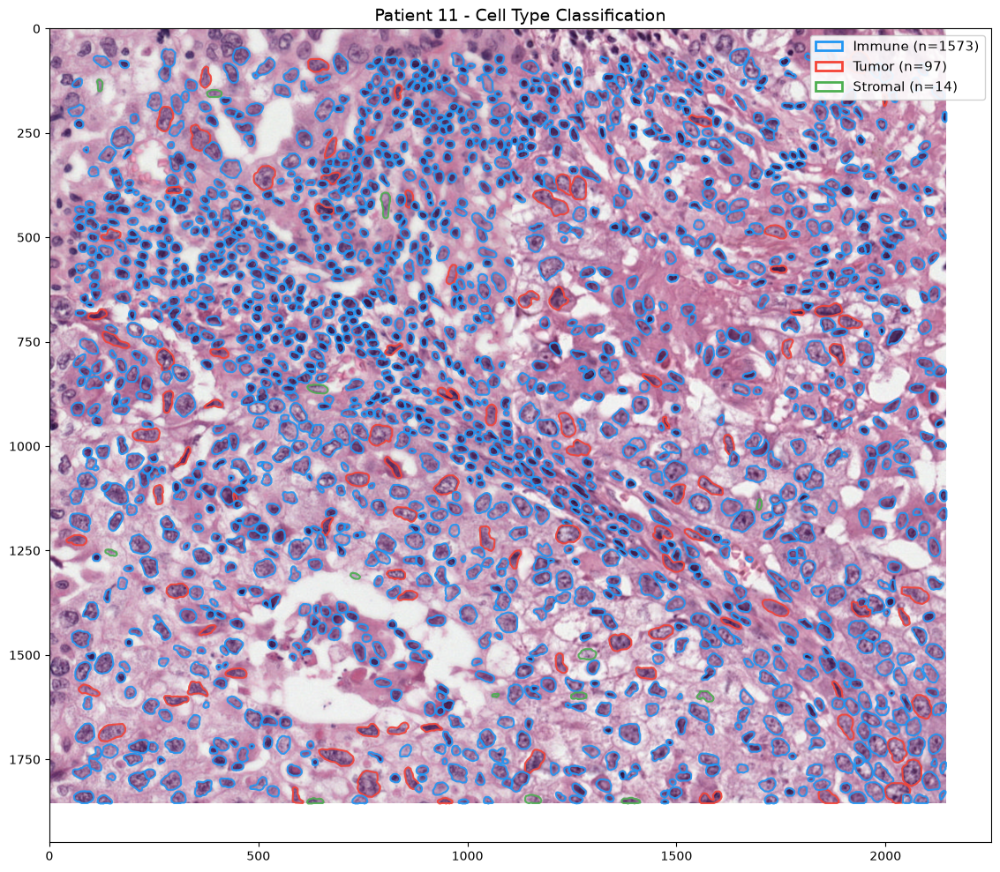

In [26]:
#patient 11 cell type visualization

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img)
#creates canvas & draws H&E img in background
#fig & ax to create new plot

color_map = {
    'immune': '#2196F3',   #blue
    'tumor': '#F44336',    #red
    'stromal': '#4CAF50'   #green
}
#gives each cell type a color

for _, row in df1.iterrows():
    polygon = MplPolygon(row['polygon'], closed=True)
    color = color_map[row['cell_type']]
    patch = PatchCollection([polygon], 
                            facecolor='none',
                            edgecolor=color,
                            linewidth=1.5,
                            alpha=0.9)
    ax.add_collection(patch)
#loop thru each cell individually and make separate PatchCollection for each cell
    #bc need 3 colors 
#color_map[row['cell_type']]: looks up color for cell based on cell type

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='none', edgecolor='#2196F3', linewidth=2, label=f'Immune (n={len(df1[df1["cell_type"]=="immune"])})'),
    Patch(facecolor='none', edgecolor='#F44336', linewidth=2, label=f'Tumor (n={len(df1[df1["cell_type"]=="tumor"])})'),
    Patch(facecolor='none', edgecolor='#4CAF50', linewidth=2, label=f'Stromal (n={len(df1[df1["cell_type"]=="stromal"])})')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=11, framealpha=0.9)
#creates legend (color patch = cell type)
#Patch(facecolor='no...: rectangle to define each cell type
#facecolor='none': keeps transparent inside
#edgecolor: border color
#f string inserts cell amount -> legend has correct nums.
#framealpha=0.9: makes box transparent so doesn't cover H&E img

ax.set_title('Patient 11 - Cell Type Classification', fontsize=14)
plt.tight_layout()
plt.show()

In [27]:
from PIL import Image
import numpy as np

# Hardcode label map from IGNITE
label_map = {
    0: "Unannotated",
    1: "Background",
    2: "Tumor epithelium",
    3: "Reactive epithelium",
    4: "Stroma",
    5: "Inflammation",
    6: "Alveolar tissue",
    7: "Fatty tissue",
    8: "Necrotic tissue",
    9: "Erythrocytes",
    10: "Bronchial epithelium",
    11: "Mucus/Plasma/Fluids",
    12: "Cartilage/Bone",
    13: "Macrophages",
    14: "Muscle",
    15: "Liver",
    16: "Keratinization"
}

mask = np.array(Image.open(os.path.expanduser("data/annotations/he/patient11_he_roi4.png")))
print("Mask shape:", mask.shape)
print("Unique pixel values:", np.unique(mask))

Mask shape: (928, 1073)
Unique pixel values: [  0 243 247 248 251 252 254]


In [28]:
#identifying annotated pixel to tissue class from IGNITE

label_map = {
    0: "Unannotated",
    1: "Background",
    2: "Tumor epithelium",
    3: "Reactive epithelium",
    4: "Stroma",
    5: "Inflammation",
    6: "Alveolar tissue",
    7: "Fatty tissue",
    8: "Necrotic tissue",
    9: "Erythrocytes",
    10: "Bronchial epithelium",
    11: "Mucus/Plasma/Fluids",
    12: "Cartilage/Bone",
    13: "Macrophages",
    14: "Muscle",
    15: "Liver",
    16: "Keratinization"
}
#hardcodes IGNITE tissue class table (instead of loading it f/file)
    #0-16 maps tissue classes annotated in dataset

unique_values = [0, 243, 247, 248, 251, 252, 254]
print("Pixel values present in patient 11 roi 4 mask:")
for v in unique_values:
    print(f"  Pixel value {v} = ???")
#loops thru pixel values in mask & looks them up in label map
    #???: bc label map 0-16 & values like 243,247,248.. (need to be normalized)
    #need to be remapped before match 0-16 tissue class & identify

print("\nNote: pixel values don't match label map integers directly")
print("Need to check if mask uses direct class indices or encoded values")
#flagging pixel values not being normalized
print("\nMask unique values:", np.unique(mask))
print("Sample pixel values from mask:", mask[mask > 0][:20])
#np.unique(mask): returns pixel values as mask array
#mask[mask > 0]: filters out background/unannotated (0 pixel val.)
#[:20]: first 20 non-0 pixels

Pixel values present in patient 11 roi 4 mask:
  Pixel value 0 = ???
  Pixel value 243 = ???
  Pixel value 247 = ???
  Pixel value 248 = ???
  Pixel value 251 = ???
  Pixel value 252 = ???
  Pixel value 254 = ???

Note: pixel values don't match label map integers directly
Need to check if mask uses direct class indices or encoded values

Mask unique values: [  0 243 247 248 251 252 254]
Sample pixel values from mask: [254 254 254 254 254 254 254 254 254 254 254 254 254 254 254 254 254 254
 254 254]


In [29]:
#patient 11 remaps cell values & assigns to tissue

mask_remapped = 254 - mask
#normalizes pixel values to fit IGNITE label map

print("Remapped unique values:", np.unique(mask_remapped))
print("\nTissue classes present in patient 11 roi 4:")
for v in np.unique(mask_remapped):
    print(f"  Class {v} = {label_map.get(v, 'Unknown')}")
#prints pixels in tissue classes after remapping based on normalization
#loops thru them & looks up in label map dictionary -> prints tissue class name
#label_map.get(v, 'Unknown'): returns tissue class name, if not found returns unknown

def get_tissue_class(x, y, mask, label_map):
    y_idx = min(int(y), mask.shape[0] - 1)
    x_idx = min(int(x), mask.shape[1] - 1)
    pixel_val = mask[y_idx, x_idx]
    class_idx = 254 - pixel_val
    return label_map.get(class_idx, 'Unknown')
#f(n) takes centroid coord. of cells & looks f/tissue class location it's in
#int(y) & int(x) convert floor coord. into integers for array
#min(..., mask.shape[0] - 1): makes index stay in mask boundaries (cells near edge would crash code otherwise)
#reads pixel val. @ location & uses 254 - pixel_val to normalize -> looks up tissue class name

df1['tissue_class'] = df1.apply(
    lambda row: get_tissue_class(row['x'], row['y'], mask, label_map), axis=1
)
#get_tissue_class: on every row in df1 w/.apply() 
    #each cell finds centroid -> finds pixel in mask -> converts to tissue class -> stores as new col. tissue_class
#lambda passes each rows x&y into f(n) w/mask & label map

print("\nTissue class distribution for patient 11 cells:")
print(df1['tissue_class'].value_counts())
#counts cells in each tissue class -> prints f/low to high

Remapped unique values: [  0   2   3   6   7  11 254]

Tissue classes present in patient 11 roi 4:
  Class 0 = Unannotated
  Class 2 = Tumor epithelium
  Class 3 = Reactive epithelium
  Class 6 = Alveolar tissue
  Class 7 = Fatty tissue
  Class 11 = Mucus/Plasma/Fluids
  Class 254 = Unknown

Tissue class distribution for patient 11 cells:
tissue_class
Unannotated            1148
Tumor epithelium        212
Mucus/Plasma/Fluids     171
Unknown                 103
Reactive epithelium      48
Fatty tissue              1
Alveolar tissue           1
Name: count, dtype: int64


In [30]:
#patient 11 contingency table
import pandas as pd

contingency = pd.crosstab(
    df1['cell_type'], 
    df1['tissue_class'],
    margins=True
)
#pd.crosstab: builds contingency table (how many cells go into predicted cell types & IGNITE tissue class)
#df1['cell_type']: cell type rows (immune, tumor, stroma)
#df1['tissue_class']: tissue type cols. (tumor epithelium, reactive epithelium, etc)
#margins=True: adds "all" row & co. w/totals f/each row & col.
    #table answers Q: "how many cells did my classifier call X and the IGNITE mask says are in tissue region Y?"

contingency_pct = pd.crosstab(
    df1['cell_type'], 
    df1['tissue_class'],
    normalize='index'
).round(3) * 100
#normalize='index': divides each row by row total -> get percentages
#.round(3): makes readable percentages

print("Contingency Table: Predicted Cell Type vs IGNITE Tissue Class")
print(contingency)
print("\nAs percentage of each predicted cell type (%):")
print(contingency_pct)
#prints raw counts & percentages

Contingency Table: Predicted Cell Type vs IGNITE Tissue Class
tissue_class  Alveolar tissue  Fatty tissue  Mucus/Plasma/Fluids  \
cell_type                                                          
immune                      1             1                  162   
stromal                     0             0                    1   
tumor                       0             0                    8   
All                         1             1                  171   

tissue_class  Reactive epithelium  Tumor epithelium  Unannotated  Unknown  \
cell_type                                                                   
immune                         43               205         1061      100   
stromal                         1                 0           12        0   
tumor                           4                 7           75        3   
All                            48               212         1148      103   

tissue_class   All  
cell_type           
immune        1573  
str

In [31]:
def compute_all_features(df, img_array):
    
    # Batch 1: Shape features
    df['area'] = df['polygon'].apply(compute_area)
    df['eccentricity'] = df['polygon'].apply(compute_eccentricity)
    df['perimeter'] = df['polygon'].apply(compute_perimeter)
    df['compactness'] = df['polygon'].apply(compute_compactness)
    df['solidity'] = df['polygon'].apply(compute_solidity)
    print("Batch 1 done")
    
    # Batch 2: Intensity features
    df[['mean_intensity', 'darkness', 'mean_red']] = df['polygon'].apply(
        lambda p: pd.Series(compute_intensity_features(p, img_array))
    )
    df[['mean_blue', 'mean_green', 'intensity_std']] = df['polygon'].apply(
        lambda p: pd.Series(compute_intensity_features_batch2(p, img_array))
    )
    print("Batch 2 done")
    
    # Batch 3: Spatial features
    df['nn_distance'] = compute_nearest_neighbor_distance(df)
    df['cell_density'] = compute_cell_density(df, patch_size=100)
    mean_k_dist, isolation = compute_spatial_features_batch3(df, k=5)
    df['mean_k_distance'] = mean_k_dist
    df['isolation_score'] = isolation
    df['entropy'] = compute_entropy_fast(df, sigma=75)
    print("Batch 3 done")
    
    # Skipping GLCM - too slow for large cell counts
    
    # Batch 5: Shape completeness
    df[['convexity', 'elongation', 'equiv_diameter']] = df['polygon'].apply(
        lambda p: pd.Series(compute_shape_completeness(p))
    )
    print("Batch 5 done")
    
    print(f"Features computed for {len(df)} cells")
    return df

In [32]:
def classify_and_validate(df, mask, label_map, patient_name):
    
    area_norm = normalize(df['area'])
    ecc_norm = normalize(df['eccentricity'])
    dark_norm = normalize(df['darkness'])
    compact_norm = normalize(df['compactness'])
    elong_norm = normalize(df['elongation'])
#normalize feat.
    
    immune_score = (
        (1 - area_norm) * 0.3 +
        (1 - ecc_norm) * 0.3 +
        dark_norm * 0.2 +
        compact_norm * 0.2
    )
    tumor_score = (
        area_norm * 0.3 +
        ecc_norm * 0.25 +
        dark_norm * 0.25 +
        (1 - compact_norm) * 0.2
    )
    stromal_score = (
        elong_norm * 0.4 +
        (1 - dark_norm) * 0.4 +
        (1 - ecc_norm) * 0.2
    )
#find cell type scores
    
    total = immune_score + tumor_score + stromal_score
    df['prob_immune'] = immune_score / total
    df['prob_tumor'] = tumor_score / total
    df['prob_stromal'] = stromal_score / total
    
    df['cell_type'] = df[['prob_immune', 'prob_tumor', 'prob_stromal']].idxmax(axis=1)
    df['cell_type'] = df['cell_type'].map({
        'prob_immune': 'immune',
        'prob_tumor': 'tumor',
        'prob_stromal': 'stromal'
    })
    
    print(f"\n{patient_name} cell type distribution:")
    print(df['cell_type'].value_counts())
#find probabilities
    
    df['tissue_class'] = df.apply(
        lambda row: get_tissue_class(row['x'], row['y'], mask, label_map), axis=1
    )
    
    print(f"\n{patient_name} tissue class distribution:")
    print(df['tissue_class'].value_counts())
#assign tissue class from IGNITE
    
    contingency = pd.crosstab(
        df['cell_type'],
        df['tissue_class'],
        margins=True
    )
    print(f"\n{patient_name} Contingency Table:")
    print(contingency)
    
    contingency_pct = pd.crosstab(
        df['cell_type'],
        df['tissue_class'],
        normalize='index'
    ).round(3) * 100
    print(f"\n{patient_name} As percentage of each predicted cell type (%):")
    print(contingency_pct)
#contigency table
    
    df = compute_celltype_features(df)
#cell type specific spatial features
    
    print(f"\n{patient_name} tumor to immune distance:")
    print(df[df['cell_type'] == 'tumor']['dist_to_nearest_immune'].describe())
    print(f"\n{patient_name} immune to tumor distance:")
    print(df[df['cell_type'] == 'immune']['dist_to_nearest_tumor'].describe())
    
    return df

In [33]:
def compare_patients(patient_dfs, patient_names):
#f(n) that takes in list of dataframes & list of names 
    #lists bc pass any # of patients and f(n) handles them the same way
    """
    Takes a list of dataframes and patient names and compares
    key features across all patients
    """
    summary = []
    
    for df, name in zip(patient_dfs, patient_names):
#makes empty list for one summary row per patient
#loop pairs dataframe w/patient name w/zip
    #patient 4's dataframe & name "Patient 4"
        
        immune_cells = df[df['cell_type'] == 'immune']
        tumor_cells = df[df['cell_type'] == 'tumor']
#filters dataframe to immune & tumor cells seperately
    #make calculations seperately
        
        row = {
            'Patient': name,
            'Total Cells': len(df),
            'Immune Count': len(immune_cells),
            'Tumor Count': len(tumor_cells),
            'Stromal Count': len(df[df['cell_type'] == 'stromal']),
            'Immune %': round(len(immune_cells) / len(df) * 100, 1),
            'Tumor %': round(len(tumor_cells) / len(df) * 100, 1),
            'Mean Tumor-to-Immune Distance': round(
                df[df['cell_type'] == 'tumor']['dist_to_nearest_immune'].mean(), 2
            ),
#summary statistics
            'Mean Immune-to-Tumor Distance': round(
                df[df['cell_type'] == 'immune']['dist_to_nearest_tumor'].mean(), 2
            ),
            'Mean Immune Density': round(df['immune_density'].mean(), 2),
            'Mean Tumor Density': round(df['tumor_density'].mean(), 2),
            'Mean Entropy': round(df['entropy'].mean(), 3),
            'Mean Darkness': round(df['darkness'].mean(), 2),
            'Mean Eccentricity': round(df['eccentricity'].mean(), 3),
        }
        summary.append(row)
    
    summary_df = pd.DataFrame(summary)
    print("Cross-Patient Feature Comparison:")
    print(summary_df.to_string(index=False))
    
    return summary_df
#converts list of dictionaries to panda dataframe (one row/patient & one col./feat.)

In [34]:
#patient 4&5 dataframes (#cells X #col.)

file4_path = os.path.expanduser("data/patient4_he_roi4.json.gz")
with gzip.open(file4_path, "rt") as f:
    data4 = json.load(f)

file5_path = os.path.expanduser("data/patient5_he_roi4.json.gz")
with gzip.open(file5_path, "rt") as f:
    data5 = json.load(f)
#load patient 4&5 JSON files
#.json.gz: loads files into Python lists (data4 & data5)
    #each list = 1 dictionary/detected cell w/polygon coord. & centroid position

print("Patient 4 cells:", len(data4))
print("Patient 5 cells:", len(data5))
#cells detected f/patients img

# Parse into dataframes
df4 = parse_cells(data4)
df5 = parse_cells(data5)
#parse_cells: extracts x&y centroids & polygon coord. f/JSON & put into pandas dataframe (3 col./each)

print("\nPatient 4 dataframe shape:", df4.shape)
print("Patient 5 dataframe shape:", df5.shape)
#dimensions of each dataframe (#cells X #col.)

Patient 4 cells: 5159
Patient 5 cells: 4230

Patient 4 dataframe shape: (5159, 3)
Patient 5 dataframe shape: (4230, 3)


In [35]:
#patient 4&5 img

img4 = mpimg.imread(os.path.expanduser("data/patient4_he_roi4.png"))
img4_array = cv2.imread(os.path.expanduser("data/patient4_he_roi4.png"))
img4_array = cv2.cvtColor(img4_array, cv2.COLOR_BGR2RGB)

img5 = mpimg.imread(os.path.expanduser("data/patient5_he_roi4.png"))
img5_array = cv2.imread(os.path.expanduser("data/patient5_he_roi4.png"))
img5_array = cv2.cvtColor(img5_array, cv2.COLOR_BGR2RGB)
#img4&img5: loads H&E img into matplotlib's img reader -> converting to numpy arrays w/pixel val. f/plotting
#img4_array&img5_array: loads imgs w/OpenCV (pixel intensity extraction -> darkness & intensity feat.) 
    #loads in BGR order by default -> cvtCoor converts to RGB f/color channel calculation

print("Patient 4 image shape:", img4.shape)
print("Patient 5 image shape:", img5.shape)

Patient 4 image shape: (3762, 3166, 3)
Patient 5 image shape: (3580, 4234, 3)


In [36]:
#features for patient 4&5
print("Computing features for Patient 4...")
#make sure you know code is running (takes several minutes)
df4 = compute_all_features(df4, img4_array)
#uses pre coded function (passes patient 4's cell dataframe & H&E img array) -> inside f(n) shape, intensity, spatial, texture, & shape completeness feat. run
    #adds 20 col. to df4 & stores back into df4

print("\nComputing features for Patient 5...")
df5 = compute_all_features(df5, img5_array)

Computing features for Patient 4...
Batch 1 done
Batch 2 done
Batch 3 done
Batch 5 done
Features computed for 5159 cells

Computing features for Patient 5...
Batch 1 done
Batch 2 done
Batch 3 done
Batch 5 done
Features computed for 4230 cells


In [37]:
#patient 4&5 masks and pixel vals. 

#load masks for patient 4 and 5
mask4 = np.array(Image.open(os.path.expanduser("data/annotations/he/patient4_he_roi4.png")))
mask5 = np.array(Image.open(os.path.expanduser("data/annotations/he/patient5_he_roi4.png")))
#Image.open: loads annotation PBG from IGNITE annotations 
#np.array: converts it into numpy array (pixel val. = tissue class)
#goes to he folder where patient H&E annotation masks are put

print("Patient 4 mask shape:", mask4.shape)
print("Patient 4 unique pixel values:", np.unique(mask4))
print("\nPatient 5 mask shape:", mask5.shape)
print("Patient 5 unique pixel values:", np.unique(mask5))
#prints dimensions and pixel vals.

Patient 4 mask shape: (1881, 1583)
Patient 4 unique pixel values: [  0 243 247 248 250 251 252 253 254 255]

Patient 5 mask shape: (1790, 2117)
Patient 5 unique pixel values: [  0 243 245 246 247 248 250 251 252 253 255]


In [38]:
#scale h&e imgs + classify and validate patient 4&5

def get_tissue_class_scaled(x, y, mask, label_map, scale=0.5):
#scales cell pos.
#tissue class lookup w scale 
    #IGNITE annotation mask 1/2 resolution of H&E imgs
    y_idx = min(int(y * scale), mask.shape[0] - 1)
    x_idx = min(int(x * scale), mask.shape[1] - 1)
#multiplies cell x&y centroid coord. by 1/2 before looking up mask
    #corresponds to same location in tissue
    #min(..., mask.shape - 1): keeps in bounds for cells near img edge
    pixel_val = mask[y_idx, x_idx]
    class_idx = 254 - pixel_val
    return label_map.get(class_idx, 'Unknown')
#reads pixel val. at coord. -> uses 254 - pixel_val to get class index -> finds tissue class name in label map
#'unknown' for every pixel val. that doesn't map onto class index

print("=== PATIENT 4 ===")
df4 = classify_and_validate(df4, mask4, label_map, "Patient 4")
print("\n=== PATIENT 5 ===")
df5 = classify_and_validate(df5, mask5, label_map, "Patient 5")
#runs on patient 4&5 
#classify_and_validate: 
    #uses rule based cell type
    #assigns tissue class from scaled mask lookup
    #contingency table
    #cell type specific spatial feat. 

=== PATIENT 4 ===

Patient 4 cell type distribution:
cell_type
immune     4850
tumor       306
stromal       3
Name: count, dtype: int64

Patient 4 tissue class distribution:
tissue_class
Unknown                1956
Tumor epithelium       1516
Reactive epithelium     688
Mucus/Plasma/Fluids     595
Fatty tissue            259
Alveolar tissue          96
Stroma                   49
Name: count, dtype: int64

Patient 4 Contingency Table:
tissue_class  Alveolar tissue  Fatty tissue  Mucus/Plasma/Fluids  \
cell_type                                                          
immune                     91           243                  570   
stromal                     0             0                    0   
tumor                       5            16                   25   
All                        96           259                  595   

tissue_class  Reactive epithelium  Stroma  Tumor epithelium  Unknown   All  
cell_type                                                                 

/var/folders/qj/j4gw7_bx0pg0k3k51h1954y40000gn/T/ipykernel_89521/3128212585.py:18: RuntimeWarning: overflow encountered in scalar subtract
  class_idx = 254 - pixel_val
/var/folders/qj/j4gw7_bx0pg0k3k51h1954y40000gn/T/ipykernel_89521/3128212585.py:18: RuntimeWarning: overflow encountered in scalar subtract
  class_idx = 254 - pixel_val


In [39]:
#patient comparison
summary = compare_patients(
    [df1, df4, df5],
    ['Patient 11', 'Patient 4', 'Patient 5']
)

Cross-Patient Feature Comparison:
   Patient  Total Cells  Immune Count  Tumor Count  Stromal Count  Immune %  Tumor %  Mean Tumor-to-Immune Distance  Mean Immune-to-Tumor Distance  Mean Immune Density  Mean Tumor Density  Mean Entropy  Mean Darkness  Mean Eccentricity
Patient 11         1684          1573           97             14      93.4      5.8                          36.88                         109.61                 5.72                0.26         1.398         138.47              0.531
 Patient 4         5159          4850          306              3      94.0      5.9                          33.30                         103.84                 5.49                0.30         1.441         158.05              0.521
 Patient 5         4230          3861          355             14      91.3      8.4                          40.45                         110.30                 4.12                0.32         1.273         156.66              0.544


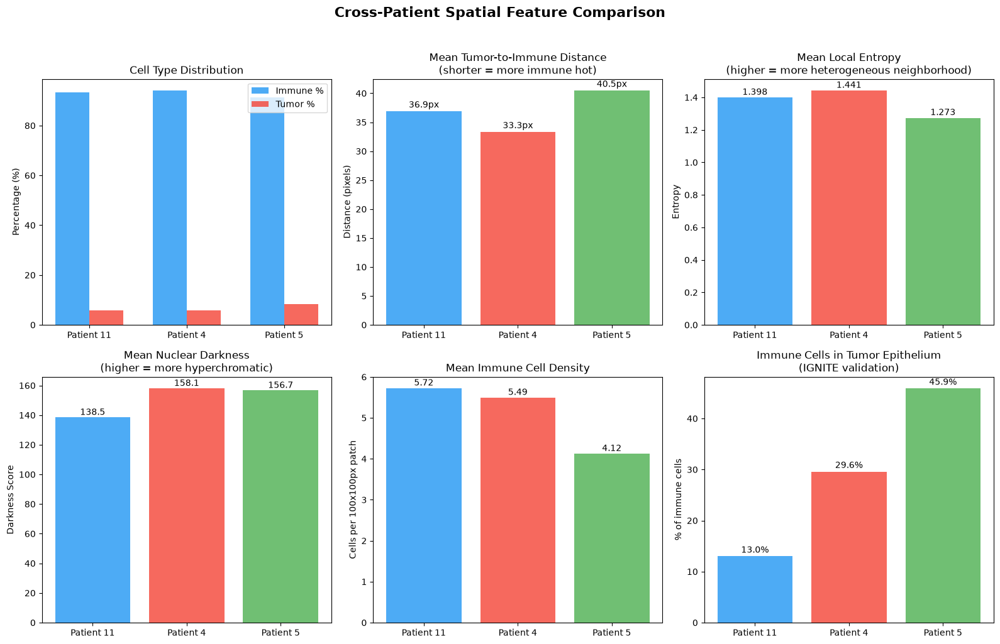

Plot saved to PredXBioData folder


In [40]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Cross-Patient Spatial Feature Comparison', fontsize=16, fontweight='bold', y=1.02)
#creates 2x3 grid of subplots = 6 plots
#figsize=(16, 10): make wide to show 6 plots next to e/a
#suptitle: one main title
#y=1.02: prevent overlap

patients = ['Patient 11', 'Patient 4', 'Patient 5']
colors = ['#2196F3', '#F44336', '#4CAF50']
#patient labels
#color scheme (blue = P11, red = P4, green = P5)

# Plot 1: Cell type distribution
ax1 = axes[0, 0]
immune_pct = [93.4, 94.0, 91.3]
tumor_pct = [5.8, 5.9, 8.4]
x = np.arange(len(patients))
width = 0.35
ax1.bar(x - width/2, immune_pct, width, label='Immune %', color='#2196F3', alpha=0.8)
ax1.bar(x + width/2, tumor_pct, width, label='Tumor %', color='#F44336', alpha=0.8)
#plot 1: bar chart showing immune % v tumor % f/each patient
#np.arange(len(patients)): 0, 1, 2 -> positions f/patients
#width/2: prevent overlap
#alpha=0.8: makes bars a little transparent
ax1.set_xticks(x)
ax1.set_xticklabels(patients)
ax1.set_ylabel('Percentage (%)')
ax1.set_title('Cell Type Distribution')
ax1.legend()

#plot 2: Tumor-to-immune distance
ax2 = axes[0, 1]
tumor_immune_dist = [36.88, 33.30, 40.45]
bars = ax2.bar(patients, tumor_immune_dist, color=colors, alpha=0.8)
ax2.set_ylabel('Distance (pixels)')
ax2.set_title('Mean Tumor-to-Immune Distance\n(shorter = more immune hot)')
for bar, val in zip(bars, tumor_immune_dist):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val:.1f}px', ha='center', va='bottom', fontsize=10)
#plot 2-6 pattern:
#ax.bar: draws bars & for loops add label f/each bar w/val.
#bar.get_x() + bar.get_width()/2: centers text
#bar.get_height() + 0.3: places text on top of bar
#f'{val:.1f}px': one decimal place

#plot 3: Mean entropy
ax3 = axes[0, 2]
entropy = [1.398, 1.441, 1.273]
bars = ax3.bar(patients, entropy, color=colors, alpha=0.8)
ax3.set_ylabel('Entropy')
ax3.set_title('Mean Local Entropy\n(higher = more heterogeneous neighborhood)')
for bar, val in zip(bars, entropy):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=10)

#plot 4: Mean darkness
ax4 = axes[1, 0]
darkness = [138.47, 158.05, 156.66]
bars = ax4.bar(patients, darkness, color=colors, alpha=0.8)
ax4.set_ylabel('Darkness Score')
ax4.set_title('Mean Nuclear Darkness\n(higher = more hyperchromatic)')
for bar, val in zip(bars, darkness):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val:.1f}', ha='center', va='bottom', fontsize=10)

#plot 5: Immune density
ax5 = axes[1, 1]
immune_density = [5.72, 5.49, 4.12]
bars = ax5.bar(patients, immune_density, color=colors, alpha=0.8)
ax5.set_ylabel('Cells per 100x100px patch')
ax5.set_title('Mean Immune Cell Density')
for bar, val in zip(bars, immune_density):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{val:.2f}', ha='center', va='bottom', fontsize=10)

#plot 6: Immune cells in tumor epithelium %
ax6 = axes[1, 2]
immune_in_tumor = [13.0, 29.6, 45.9]
bars = ax6.bar(patients, immune_in_tumor, color=colors, alpha=0.8)
ax6.set_ylabel('% of immune cells')
ax6.set_title('Immune Cells in Tumor Epithelium\n(IGNITE validation)')
for bar, val in zip(bars, immune_in_tumor):
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.expanduser('data/cross_patient_comparison.png'),
            dpi=150, bbox_inches='tight')
plt.show()
#tight_layout: spacing subplots to prevent overlap
#savefig: saves plot as PNG file to PredXBioData folder
#bbox_inches='tight': makes sure nothing gets cut off
print("Plot saved to PredXBioData folder")

In [41]:
# z score normalization

from scipy.stats import zscore
#import zscore f(n) -> takes array of val. & converts each into SDs away from mean in that array

feature_cols = ['area', 'eccentricity', 'perimeter', 'compactness', 'solidity',
                'mean_intensity', 'darkness', 'mean_red', 'mean_blue', 'mean_green',
                'intensity_std', 'nn_distance', 'cell_density', 'mean_k_distance',
                'isolation_score', 'entropy', 'convexity', 'elongation', 'equiv_diameter']
#feat. to normalize

def add_zscores(df, feature_cols):
    for col in feature_cols:
        if col in df.columns:
            df[f'{col}_z'] = zscore(df[col].fillna(df[col].mean()))
#loops thru all feat.
#if col in df.columns: checks if feat. exist in dataframe before normalizing
#fillna(df[col].mean()): replaces any missing vals. in col. before normalizing (prevents crash)
#f'{col}_z': creates new col. w/z (ex. area -> area_z - keeps original vals. + normalized vals.)
    print(f"Z-scores added for {len([c for c in feature_cols if c in df.columns])} features")
    return df

df1 = add_zscores(df1, feature_cols)
df4 = add_zscores(df4, feature_cols)
df5 = add_zscores(df5, feature_cols)
#normalizes all 3 patients

print("\nSample z-score columns for patient 11:")
z_cols = [c + '_z' for c in feature_cols if c in df1.columns]
print(df1[z_cols[:5]].describe().round(3))
#list of z score col. names & summary stats.

Z-scores added for 19 features
Z-scores added for 19 features
Z-scores added for 19 features

Sample z-score columns for patient 11:
         area_z  eccentricity_z  perimeter_z  compactness_z  solidity_z
count  1684.000        1684.000     1684.000       1684.000    1684.000
mean     -0.000          -0.000       -0.000         -0.000      -0.000
std       1.000           1.000        1.000          1.000       1.000
min      -1.180          -2.467       -1.765         -5.673     -10.172
25%      -0.652          -0.570       -0.698         -0.451      -0.267
50%      -0.338           0.103       -0.253          0.247       0.232
75%       0.374           0.741        0.582          0.705       0.589
max       5.486           1.941        4.979          1.584       1.231


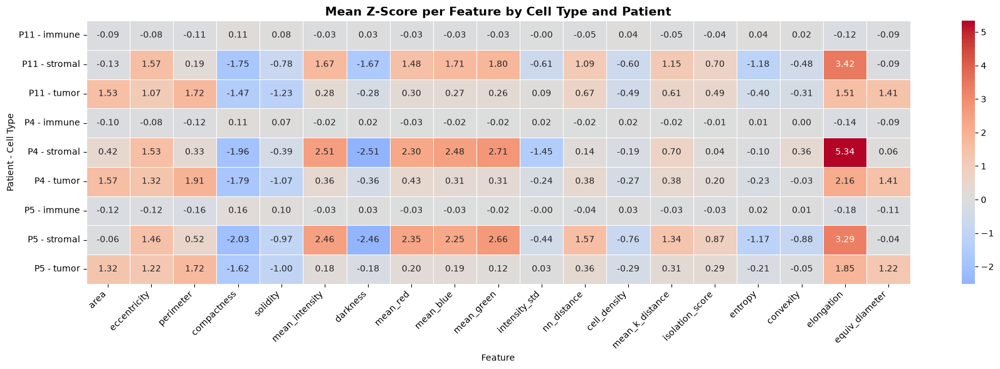

Heatmap saved


In [42]:
#p4,5,11 heatmap

import seaborn as sns
#visualization libaray f/stat. plots (ex. heatmap)

z_cols_clean = [c + '_z' for c in feature_cols if c in df1.columns]
#list of z score col. names
#if c in df1.columns: makes sure only inc. feat. in dataframe

def get_mean_zscores_by_celltype(df, patient_name, z_cols):
    result = df.groupby('cell_type')[z_cols].mean()
    result.index = [f'{patient_name} - {ct}' for ct in result.index]
    return result
#groups cell by predicted type (immune, stroma, tumor)
#mean z score f/every feat. (instead of individual cells -> 3 summary rows (one/cell type)) - avg feat. profile f/cell type
#rename index -> know which patient & cell type f/each row

heatmap_data = pd.concat([
    get_mean_zscores_by_celltype(df1, 'P11', z_cols_clean),
    get_mean_zscores_by_celltype(df4, 'P4', z_cols_clean),
    get_mean_zscores_by_celltype(df5, 'P5', z_cols_clean)
])
#stacks patients dataframes -> one table

heatmap_data.columns = [c.replace('_z', '') for c in heatmap_data.columns]
#removes _z -> looks cleaner

fig, ax = plt.subplots(figsize=(18, 6))
sns.heatmap(heatmap_data, 
            cmap='coolwarm',
            center=0,
            annot=True,
            fmt='.2f',
            linewidths=0.5,
            ax=ax)
#draw heatmap
#cmap='coolwarm': blue to red color scheme
#center=0: color scale (+ zscore = red; - zscore = blue)
#annot=True: number inside each cell
#fmt='.2f': 2 decimal places
#linewidths=0.5: lines between cells -> readable
ax.set_title('Mean Z-Score per Feature by Cell Type and Patient', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature')
ax.set_ylabel('Patient - Cell Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.expanduser('data/feature_heatmap.png'),
            dpi=150, bbox_inches='tight')
#saves heatmap as PNG to PredXBioData folder at 150 DPI
plt.show()
print("Heatmap saved")

In [43]:
!pip install seaborn

In [44]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Combine all patients for clustering
z_cols_clean = [c + '_z' for c in feature_cols if c in df1.columns]

# Add patient label to each dataframe temporarily
df1['patient'] = 'P11'
df4['patient'] = 'P4'
df5['patient'] = 'P5'

# Combine all three patients
df_all = pd.concat([df1, df4, df5], ignore_index=True)

# Drop rows with any NaN in z-score columns
df_all_clean = df_all[z_cols_clean + ['cell_type', 'patient']].dropna()

# Run k-means with 3 clusters (tumor, immune, stromal)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_all_clean['cluster'] = kmeans.fit_predict(df_all_clean[z_cols_clean])

# Compare clusters to rule-based labels
print("Cluster vs Rule-Based Cell Type:")
print(pd.crosstab(df_all_clean['cluster'], df_all_clean['cell_type'], margins=True))

print("\nCluster distribution:")
print(df_all_clean['cluster'].value_counts())

Cluster vs Rule-Based Cell Type:
cell_type  immune  stromal  tumor    All
cluster                                 
0            5099        0    111   5210
1            2853       15    139   3007
2            2332       16    508   2856
All         10284       31    758  11073

Cluster distribution:
cluster
0    5210
1    3007
2    2856
Name: count, dtype: int64


In [45]:
!pip install stardist tensorflow

In [46]:
from stardist.models import StarDist2D
from csbdeep.utils import normalize
import numpy as np

# Load pretrained model - '2D_versatile_he' is specifically trained on H&E images
model = StarDist2D.from_pretrained('2D_versatile_he')

# Use patient 4 image - convert to numpy array
img4_gray = normalize(img4)

# Run prediction
labels, details = model.predict_instances(img4_gray)

print("Segmentation complete")
print(f"Number of nuclei detected: {labels.max()}")
print(f"Output keys: {details.keys()}")
print(f"Sample polygon coords: {details['coord'][0].shape}")

Found model '2D_versatile_he' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.692478, nms_thresh=0.3.
Segmentation complete
Number of nuclei detected: 4453
Output keys: dict_keys(['coord', 'points', 'prob'])
Sample polygon coords: (2, 32)


In [47]:
# Check StarDist output format vs Marc's format
print("StarDist coord shape for first nucleus:", details['coord'][0].shape)
print("StarDist coord sample:\n", details['coord'][0])

print("\nMarc's format sample from df4:")
print(df4['polygon'][0][:3])

# Convert StarDist format to Marc's format
# StarDist gives (2, 32) = (y_coords, x_coords)
# Marc's format is [[x1,y1], [x2,y2], ...]
def convert_stardist_to_marc_format(coord):
    y_coords = coord[0]
    x_coords = coord[1]
    return [[float(x), float(y)] for x, y in zip(x_coords, y_coords)]

sample_converted = convert_stardist_to_marc_format(details['coord'][0])
print("\nConverted format sample:")
print(sample_converted[:3])

StarDist coord shape for first nucleus: (2, 32)
StarDist coord sample:
 [[2782.       2784.48     2786.9954   2789.1582   2791.3713   2793.482
  2795.8098   2797.3433   2798.925    2798.6882   2798.118    2796.3652
  2793.9287   2791.0854   2788.0903   2784.9268   2782.       2779.2795
  2776.7793   2774.7766   2773.0002   2771.5144   2769.8962   2768.9585
  2767.8281   2767.5786   2767.5193   2768.7876   2770.7864   2773.4973
  2776.3728   2779.3557  ]
 [ 113.39869   112.467255  112.05997   110.71283   109.37136   107.67204
   105.72023   103.05195   100.         96.68053    93.32378    90.40139
    88.07121    86.402794   85.296524   85.2865     85.129486   86.32386
    87.3963     89.1894     91.00037    92.99382    94.986465   97.40588
   100.        102.868614  105.99813   108.82826   111.21357   112.72525
   113.58504   113.29326 ]]

Marc's format sample from df4:
[[247.0, 3639.0], [246.0, 3641.0], [246.0, 3645.0]]

Converted format sample:
[[113.39868927001953, 2782.0], [112.467

In [48]:
#multi feat. entropy f/8 feat.

from scipy.stats import entropy as scipy_entropy
#import scipy entropy f(n) 

def compute_multi_feature_entropy(df, sigma=75):
    
    coords = df[['x', 'y']].values
    tree = KDTree(coords)
    sparse_matrix = tree.sparse_distance_matrix(tree, max_distance=sigma, output_type='coo_matrix')
    
    entropy_features = ['area', 'eccentricity', 'darkness', 'compactness', 
                        'solidity', 'nn_distance', 'elongation', 'equiv_diameter']
    
    results = {f'entropy_{feat}': np.zeros(len(df)) for feat in entropy_features}
#defines 8 feat. used find neighborhood entropy
#results creates dictionary w empty array per feat.
    #ex. entropy_area & entropy_eccentricity each w/slot per cell for computed val.
    
    for i in range(len(df)):
        neighbors = sparse_matrix.col[sparse_matrix.row == i]
        neighbors = neighbors[neighbors != i]
#neighbor lookup as entropy f(n) - cells within 75 pixels not inc itself
        
        if len(neighbors) < 2:
            for feat in entropy_features:
                results[f'entropy_{feat}'][i] = 0
            continue
        
        for feat in entropy_features:
            if feat not in df.columns:
                continue
            neighbor_vals = df.iloc[neighbors][feat].values
            hist, _ = np.histogram(neighbor_vals, bins=10)
            hist = hist / hist.sum()
            hist = hist + 1e-10
            results[f'entropy_{feat}'][i] = scipy_entropy(hist)
#f/all 8 feat. collect feat. val. f/neighboring cells -> put into histogram -> normalize -> compute entropy
    #8 entropy val.: varied area nearby; eccentricity; darkness...
    #measuring heterogeneity across multiple biological dimensions simultaneously
    
    for col, vals in results.items():
        df[col] = vals
    
    print(f"Multi-feature entropy computed for {len(entropy_features)} features")
    return df
#stores all 8 entropy arrays as new cols. in dataframe
#returns updated dataframe

print("Patient 11...")
df1 = compute_multi_feature_entropy(df1)
print("Patient 4...")
df4 = compute_multi_feature_entropy(df4)
print("Patient 5...")
df5 = compute_multi_feature_entropy(df5)
#runs on all 3 patients

Patient 11...
Multi-feature entropy computed for 8 features
Patient 4...
Multi-feature entropy computed for 8 features
Patient 5...
Multi-feature entropy computed for 8 features


Z-scores added for 8 features
Z-scores added for 8 features
Z-scores added for 8 features


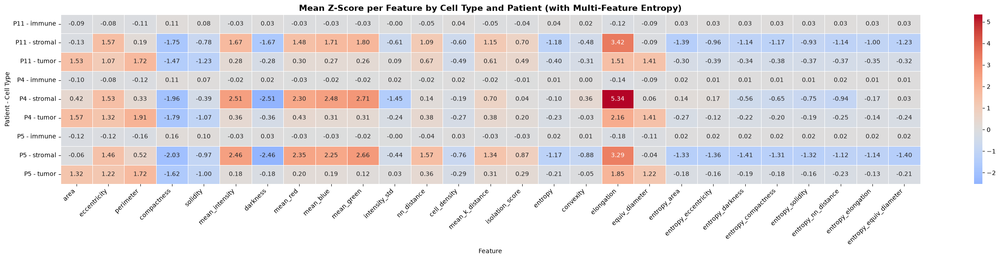

Updated heatmap saved


In [49]:
entropy_feature_cols = ['entropy_area', 'entropy_eccentricity', 'entropy_darkness',
                        'entropy_compactness', 'entropy_solidity', 'entropy_nn_distance',
                        'entropy_elongation', 'entropy_equiv_diameter']
#list of 8 new entropy col. -> one f/feat. neighborhood entropy

df1 = add_zscores(df1, entropy_feature_cols)
df4 = add_zscores(df4, entropy_feature_cols)
df5 = add_zscores(df5, entropy_feature_cols)
#normalizes (z score) 8 new entropy feat.

all_feature_cols = feature_cols + entropy_feature_cols
all_z_cols = [c + '_z' for c in all_feature_cols if c in df1.columns]
#combines 19 feat. w/8 new entropy feat. names into 1 list
#builds z score col. name by adding '_z' to end of everything
#if c in df1.columns: checks f/feat. that might not exist -> prevents code f/crashing 

heatmap_data2 = pd.concat([
    get_mean_zscores_by_celltype(df1, 'P11', all_z_cols),
    get_mean_zscores_by_celltype(df4, 'P4', all_z_cols),
    get_mean_zscores_by_celltype(df5, 'P5', all_z_cols)
])

heatmap_data2.columns = [c.replace('_z', '') for c in heatmap_data2.columns]
#groups cells by type within patient
#find z scores
#stacks 3 patients into table
#removes _z for heatmap

fig, ax = plt.subplots(figsize=(26, 6))
sns.heatmap(heatmap_data2,
            cmap='coolwarm',
            center=0,
            annot=True,
            fmt='.2f',
            linewidths=0.5,
            ax=ax)
#heatmap parameters
ax.set_title('Mean Z-Score per Feature by Cell Type and Patient (with Multi-Feature Entropy)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature')
ax.set_ylabel('Patient - Cell Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.expanduser('data/feature_heatmap_v2.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Updated heatmap saved")
#saves as feature_heatmap_v2.png (keeps og as v1)

In [50]:
#StarDist -> Pandas DataFrame format

def stardist_to_dataframe(details):
    rows = []
#f(n) takes StarDist output dictionary & converts to pandas dataframe (matches Marc's JSON files)
#rows: starts as empty list & gets filled w/one dictionary per cell
    for i in range(len(details['points'])):
#loops thru every nucleus
#details['points']: centroid coord. f/detected cells
#len(details['points']): num. of cells in StarDist
        y_centroid = details['points'][i][0]
        x_centroid = details['points'][i][1]
#StarDist centroids = [y,x] -> converts to standard [x,y] (same format in Marc's JSON files)
        
        coord = details['coord'][i]
        y_coords = coord[0]
        x_coords = coord[1]
        polygon = [[float(x), float(y)] for x, y in zip(x_coords, y_coords)]
#details['coord'][i]: gives polygon boundary f/cell in i shape
#row 0: y coord & row 1: x coord.
#zip(x_coords, y_coords): pairs up x&y -> list comprehension converts them into Marc's format (list of [x,y] pairs)
#float(): makes vals. Python floats not numpy floats
        
        rows.append({
            'x': float(x_centroid),
            'y': float(y_centroid),
            'polygon': polygon
        })
#adds one dictionary per cell to rows list within 3 fields (x centroid, y centroid, polygon boundary coord.)
    
    return pd.DataFrame(rows)
#converts list of dictionaries into pandas dataframe 
#one row per cell, 3 cols. (x, y, polygon) -> pass into compute_all_features

In [51]:
#segmentation

def segment_and_featurize(img, img_array, patient_name):
    print(f"Running StarDist segmentation on {patient_name}...")
#pipeline f(n) that takes 3 inputs 
    #img: H&E img (loaded as float32 numpy array f/StarDist
    #img_array: same img loaded w/OpenCV in BGR->RGB f/pixel intensity extraction 
    #patient_name: string label f/print statements
    
    img_normalized = normalize(img)
#normalize img pixel val. to 0-1 w/csbdeep's normalize f(n)
    #StarDist requires normalized output bc trained on normalized imgs
    labels, details = model.predict_instances(img_normalized)
#runs StarDist 2D_versatile_he pretrained model on normalized img
#labels: 2D array -> same size as img where pixel labeled w which nucleus it belongs to
#details: dictionary containing points (centroids), coord (polygon boundaries), & prob (detection confidence scores) f/every nucleus
    print(f"Detected {len(details['points'])} cells")
    
    df = stardist_to_dataframe(details)
#converts StarDists output into pandas dataframe using prev. f(n)
    print(f"Dataframe created: {df.shape}")
    
    print(f"Computing features...")
    df = compute_all_features(df, img_array)
#run all feat. on batches of segmented cells
    #shape feat. f/shapely polygons 
    #intensity feat. f/OpenCV pixel mashing
    #spatial feat. f/KDTree neighbor lookups
    #shape completeness feat.
    #takes 3 col. dataframe (x, y, polygon) -> returns w/22 add. feat. cols.
    
    print(f"Done with {patient_name}")
    return df
#returns updated dataframe

In [52]:
import pandas as pd
import glob
import os
#pandas: reading & using CSV file 
#glob: file path pattern matching
#os: handling file paths

data_overview = pd.read_csv(os.path.expanduser("data/data_overview.csv"))
#load IGNITE dataset metadata CSV into pandas dataframe 
    #file - one row per ROI w/col. inc. patient ID, ROI name, histological subtype, scanner, specimen type, & data split -> everything in IGNITE

he_data = data_overview[data_overview['task'] == 'he_tissue_segmentation'].copy()
#filters only h&e tissue segmentation rows 
#.copy(): creates new dataframe (avoid pandas warnings when modifying later)

one_roi_per_patient = he_data.groupby('patient_id').first().reset_index()
#groups by patient ID & takes 1st ROI f/each patient
    #each parient has multiple ROIs only want one per patient (avoid overrepresentation)
#.first(): takes 1st rows in each group which corresponds to ROI1 f/most patients
#.reset_index(): converts group index into reg. col.

print(f"Total unique patients: {len(one_roi_per_patient)}")
print(f"Histological subtypes:")
print(one_roi_per_patient['histological_subtype'].value_counts())
print(f"\nSample ROI names:")
print(one_roi_per_patient['name'].head(10).tolist())
#unique patients; dist. of cancer subtypes; 1st 10 ROI names

Total unique patients: 82
Histological subtypes:
histological_subtype
adenocarcinoma             47
squamous_cell_carcinoma    30
adenosquamous               2
large_cell                  2
unknown                     1
Name: count, dtype: int64

Sample ROI names:
['patient1_he_roi1', 'patient2_he_roi1', 'patient3_he_roi1', 'patient4_he_roi1', 'patient5_he_roi1', 'patient6_he_roi1', 'patient7_he_roi1', 'patient8_he_roi1', 'patient9_he_roi1', 'patient10_he_roi1']


In [53]:
#save 82 patient data without doing computation every time

import pickle
#save any Python obj inc. dictionary of 82 dataframes

with open(os.path.expanduser("data/all_patient_dfs.pkl"), 'rb') as f:
    all_patient_dfs = pickle.load(f)
#opens pkl file (binary mode - 'rb') & loads back into memory as Python dictionary
#pickle.load: reconstructs same dictionary of 82 patient dataframes saved during batch pipeline run
#lets you work with data without doing computation every time

print(f"Total patients: {len(all_patient_dfs)}")
print(f"\nSample cell counts:")
for name, df in list(all_patient_dfs.items())[:5]:
    print(f"  {name}: {len(df)} cells, columns: {len(df.columns)}")
#confirms file loaded correctly 
#prints num. of patients, cell counts, & col. counts f/1st 5 patients

Total patients: 395

Sample cell counts:
  patient1_he_roi1: 4046 cells, columns: 30
  patient2_he_roi1: 1442 cells, columns: 30
  patient3_he_roi1: 839 cells, columns: 30
  patient4_he_roi1: 868 cells, columns: 30
  patient5_he_roi1: 814 cells, columns: 30


In [54]:
# Build summary dataframe - one row per patient with mean feature values
feature_cols = ['area', 'eccentricity', 'perimeter', 'compactness', 'solidity',
                'mean_intensity', 'darkness', 'mean_red', 'mean_blue', 'mean_green',
                'intensity_std', 'nn_distance', 'cell_density', 'mean_k_distance',
                'isolation_score', 'entropy', 'convexity', 'elongation', 'equiv_diameter']
#defines 19 feat. want to use

summary_rows = []
for patient_name, df in all_patient_dfs.items():
    row = {'patient': patient_name}
    for col in feature_cols:
        if col in df.columns:
            row[col] = df[col].mean()
#loops thru patients dataframe & finds mean of each feat. f/patient
#if col in df.columns: stops code from  breaking if feat. not computed f/patient
    row['histological_subtype'] = df['histological_subtype'].iloc[0] if 'histological_subtype' in df.columns else 'unknown'
    row['n_cells'] = len(df)
    summary_rows.append(row)
#adds cancer subtype label & total cell counts to each patients summary row -> adds to list
#summary_rows: 82 dictionaries (one per person)


summary_df = pd.DataFrame(summary_rows)
print(f"Summary dataframe shape: {summary_df.shape}")
print(summary_df[['patient', 'n_cells', 'histological_subtype', 'area', 'darkness', 'entropy']].head(10))
#converts list of dictionaries into dataframe w/82 rows & 22 col. 
#print first 10 patients

Summary dataframe shape: (395, 22)
             patient  n_cells     histological_subtype        area  \
0   patient1_he_roi1     4046  squamous_cell_carcinoma  188.072173   
1   patient2_he_roi1     1442           adenocarcinoma   94.472752   
2   patient3_he_roi1      839           adenocarcinoma  193.834840   
3   patient4_he_roi1      868  squamous_cell_carcinoma  277.382309   
4   patient5_he_roi1      814           adenocarcinoma  268.138620   
5   patient6_he_roi1     1173           adenocarcinoma  191.496570   
6   patient7_he_roi1      980  squamous_cell_carcinoma  135.639695   
7   patient8_he_roi1      721           adenocarcinoma  219.141006   
8   patient9_he_roi1      705           adenocarcinoma  179.860181   
9  patient10_he_roi1     1179           adenocarcinoma  212.808366   

     darkness   entropy  
0  149.857959  1.695292  
1  168.191405  1.722138  
2  161.739554  1.606719  
3  161.678630  1.609824  
4  147.091842  1.642364  
5  162.938113  1.737026  
6  170.96943

Features after cleaning: 18 out of 19


_stats_py.py (1162): invalid value encountered in subtract


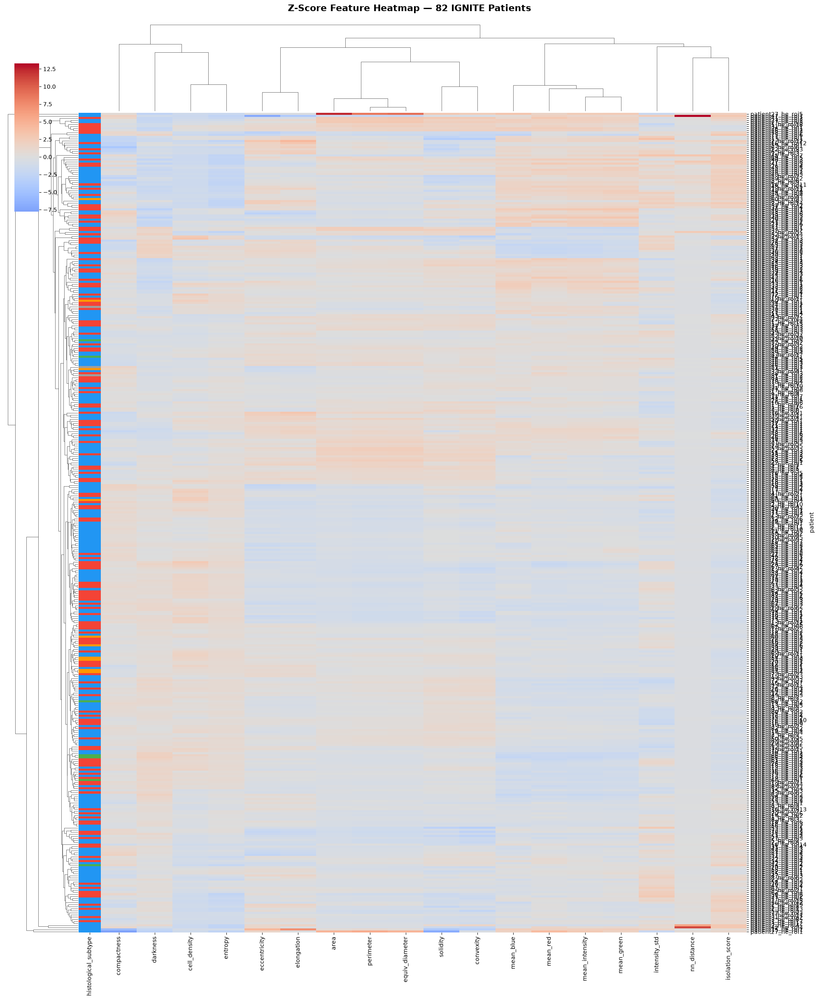

Heatmap saved


In [55]:
import seaborn as sns
import numpy as np
from scipy.stats import zscore
#seaborn: clustermap visualization
#numpy: handling infinite values
#zscore: scipy f/normalization

feature_cols_available = [c for c in feature_cols if c in summary_df.columns]
summary_z = summary_df[feature_cols_available].apply(zscore)
summary_z.index = summary_df['patient']
#filters to only feat. in summary dataframe -> zscore normalization to every feat. col. f/82 patients
    #converts feat. into SDs away f/mean in all patients
    #ex. patient w/high darkness = high positive z-score; low darkness = negative score
#sets index to patient name -> row labeled by patient

summary_z_clean = summary_z.replace([np.inf, -np.inf], np.nan).dropna(axis=1)
print(f"Features after cleaning: {summary_z_clean.shape[1]} out of {len(feature_cols_available)}")
#replaces infinite val. w/NaN & drops feat. w/NaN
    #removed 1 feat. -> 18 real feat.
    #infinite val. happen when 0 feat. variance across all patients -> not useful f/comparison 

subtype_colors = {
    'adenocarcinoma': '#2196F3', #blue
    'squamous_cell_carcinoma': '#F44336', #red
    'adenosquamous': '#4CAF50', #green
    'large_cell': '#FF9800', #orange
    'unknown': '#9E9E9E' #grey
}
row_colors = summary_df['histological_subtype'].map(subtype_colors)
row_colors.index = summary_df['patient']
#color map 
#map(subtype_colors): converts each patients subtype string to corresponding color

g = sns.clustermap(summary_z_clean,
                   cmap='coolwarm',
                   center=0,
                   row_colors=row_colors,
                   figsize=(20, 24),
                   xticklabels=True,
                   yticklabels=True,
                   dendrogram_ratio=0.1,
                   cbar_pos=(0.02, 0.8, 0.03, 0.15))
#draws clustermap (heatmap w/hierarchial clustering on rows & cols.)
#cmap='coolwarm: blue to red colors
#center=0: white @ 0
#row_colors: adds subtype color sidebar
#dendrogram_ratio=0.1: keeps dendogram small
#cbar_pos: position color legend
    #clustermap automatically reorders rows & cols. to group similar patients & feat. tg -> shows biological pattern

g.fig.suptitle('Z-Score Feature Heatmap — 82 IGNITE Patients',
               fontsize=16, fontweight='bold', y=1.01)

plt.savefig(os.path.expanduser('data/patient_heatmap_82.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Heatmap saved")
#title
#saves to PredXBio folder 
#displays plot

In [56]:
#converts summary dictionaries into dataframe -> feed into Cox Model
from scipy.stats import zscore

def normalize(series):
    min_val = series.min()
    max_val = series.max()
    if max_val == min_val:
        return series * 0
    return (series - min_val) / (max_val - min_val)
#min-max normalization f(n) that scales feat. col. to 0-1 range
#if max_val == min_val: checks for when cells have similar vals. -> returns all 0s
    #make sure weighted scores comparable when combined

all_patient_summaries = []

for patient_name, df in all_patient_dfs.items():
#empty list -> one summary row per patient -> loops thru 82 patient dataframes
    try:
        area_norm = normalize(df['area'])
        ecc_norm = normalize(df['eccentricity'])
        dark_norm = normalize(df['darkness'])
        compact_norm = normalize(df['compactness'])
        elong_norm = normalize(df['elongation'])
#normalizes 5 most biologically meaningful feat. f/cell type classification on 0-1 scale

        immune_score = (1 - area_norm) * 0.3 + (1 - ecc_norm) * 0.3 + dark_norm * 0.2 + compact_norm * 0.2
        tumor_score = area_norm * 0.3 + ecc_norm * 0.25 + dark_norm * 0.25 + (1 - compact_norm) * 0.2
        stromal_score = elong_norm * 0.4 + (1 - dark_norm) * 0.4 + (1 - ecc_norm) * 0.2
#finds raw score f/cell type based on weighted feat. combos 
        #ex. immune cells small (low area), round (low eccentricity), dark (high darkness), & compact
        #ex. tumor cells large, irregular, dark, & low compactness
        #ex. stromal cells elongated & lightly stained 

        total = immune_score + tumor_score + stromal_score
        df['prob_immune'] = immune_score / total
        df['prob_tumor'] = tumor_score / total
        df['prob_stromal'] = stromal_score / total
#converts 3 scores into probabilities = 1 f/every cell dividing score by total
        #every cell gets prob_immune, prob_tumor, prob_stromal -> see how likely cell is each type
        df['cell_type'] = df[['prob_immune', 'prob_tumor', 'prob_stromal']].idxmax(axis=1)
        df['cell_type'] = df['cell_type'].map({
            'prob_immune': 'immune',
            'prob_tumor': 'tumor',
            'prob_stromal': 'stromal'
        })
#assigns label to highest probability
#idxmax(axis=1): returns col. name w/highest val. f/each row 
        #ex. cell w/prob_immune=0.6, prob_tumor=0.3, prob_stromal=0.1 gets labeled prob_immune
#.map(): converts col. names into labels

        immune_cells = df[df['cell_type'] == 'immune'][['x', 'y']].values
        tumor_cells = df[df['cell_type'] == 'tumor'][['x', 'y']].values

        tumor_to_immune_dist = np.nan
        immune_to_tumor_dist = np.nan

        if len(immune_cells) > 0 and len(tumor_cells) > 0:
            immune_tree = KDTree(immune_cells)
            tumor_tree = KDTree(tumor_cells)
            t2i, _ = immune_tree.query(tumor_cells, k=1)
            i2t, _ = tumor_tree.query(immune_cells, k=1)
            tumor_to_immune_dist = t2i.mean()
            immune_to_tumor_dist = i2t.mean()
#centroid coord. f/immune & tumor cells separately
#KDTree spatial index f/tumor & immune
        #tumor cell = how far nearest immune cell; immune cell how far = nearest tumor cell 
        #short distances = immune cells engaging w/tumor cells

        row = {
            'patient': patient_name,
            'patient_id': df['patient_id'].iloc[0] if 'patient_id' in df.columns else None,
            'histological_subtype': df['histological_subtype'].iloc[0] if 'histological_subtype' in df.columns else None,
            'n_cells': len(df),
            'immune_pct': (df['cell_type'] == 'immune').mean() * 100,
            'tumor_pct': (df['cell_type'] == 'tumor').mean() * 100,
            'stromal_pct': (df['cell_type'] == 'stromal').mean() * 100,
            'tumor_to_immune_dist': tumor_to_immune_dist,
            'immune_to_tumor_dist': immune_to_tumor_dist,
            'mean_darkness': df['darkness'].mean(),
            'mean_entropy': df['entropy'].mean(),
            'mean_area': df['area'].mean(),
            'mean_eccentricity': df['eccentricity'].mean(),
            'mean_cell_density': df['cell_density'].mean(),
            'mean_nn_distance': df['nn_distance'].mean(),
        }
        all_patient_summaries.append(row)
        all_patient_dfs[patient_name] = df
#builds summary dictionary f/patient w/key metrics
#stores updated dataframe (cell labels inc.) into all_patient_dfs & adds summary row to list  
        print(f"✓ {patient_name}")

    except Exception as e:
        print(f"✗ {patient_name}: {e}")
        continue

patient_summary_df = pd.DataFrame(all_patient_summaries)
print(f"\nSummary dataframe: {patient_summary_df.shape}")
print(patient_summary_df[['patient', 'immune_pct', 'tumor_pct', 'tumor_to_immune_dist', 'mean_entropy']].head(10))
#converts summary into dataframe

✓ patient1_he_roi1
✓ patient2_he_roi1
✓ patient3_he_roi1
✓ patient4_he_roi1
✓ patient5_he_roi1
✓ patient6_he_roi1
✓ patient7_he_roi1
✓ patient8_he_roi1
✓ patient9_he_roi1
✓ patient10_he_roi1
✓ patient11_he_roi1
✓ patient12_he_roi1
✓ patient13_he_roi1
✓ patient14_he_roi1
✓ patient15_he_roi1
✓ patient16_he_roi1
✓ patient17_he_roi1
✓ patient18_he_roi1
✓ patient19_he_roi1
✓ patient20_he_roi1
✓ patient21_he_roi1
✓ patient22_he_roi1
✓ patient23_he_roi1
✓ patient24_he_roi1
✓ patient25_he_roi1
✓ patient26_he_roi1
✓ patient27_he_roi1
✓ patient28_he_roi1
✓ patient29_he_roi1
✓ patient30_he_roi1
✓ patient31_he_roi1
✓ patient32_he_roi1
✓ patient33_he_roi1
✓ patient34_he_roi1
✓ patient35_he_roi1
✓ patient36_he_roi1
✓ patient37_he_roi1
✓ patient38_he_roi1
✓ patient39_he_roi1
✓ patient40_he_roi1
✓ patient41_he_roi1
✓ patient42_he_roi1
✓ patient43_he_roi1
✓ patient44_he_roi1
✓ patient45_he_roi1
✓ patient46_he_roi1
✓ patient47_he_roi1
✓ patient48_he_roi1
✓ patient49_he_roi1
✓ patient50_he_roi1
✓ patient

In [57]:
#patient summary -> CSV (format f/Cox Model)
patient_summary_df.to_csv(
    os.path.expanduser('data/patient_feature_summary.csv'),
    index=False
)
#saves summary dataframe -> CSV file in PredXBioData folder
#index=False: prevents pandas f/writing the row nums. as extra col.
#CVS output -> format for Cox model
print("Saved patient_feature_summary.csv")
print(f"\nShape: {patient_summary_df.shape}")
print(f"\nColumns: {list(patient_summary_df.columns)}")
#makes sure file saved & prints dimensions & col. names
print(f"\nHistological subtype distribution:")
print(patient_summary_df['histological_subtype'].value_counts())
#num. of patients f/cancer subtype (context for Cox model)
print(f"\nKey feature ranges:")
print(patient_summary_df[['tumor_to_immune_dist', 'immune_pct', 'tumor_pct', 'mean_entropy', 'mean_darkness']].describe().round(2))
#prints summary stats. of 5 most bio meaningful feat. 

Saved patient_feature_summary.csv

Shape: (395, 15)

Columns: ['patient', 'patient_id', 'histological_subtype', 'n_cells', 'immune_pct', 'tumor_pct', 'stromal_pct', 'tumor_to_immune_dist', 'immune_to_tumor_dist', 'mean_darkness', 'mean_entropy', 'mean_area', 'mean_eccentricity', 'mean_cell_density', 'mean_nn_distance']

Histological subtype distribution:
histological_subtype
adenocarcinoma             226
squamous_cell_carcinoma    149
large_cell                  10
adenosquamous                7
unknown                      3
Name: count, dtype: int64

Key feature ranges:
       tumor_to_immune_dist  immune_pct  tumor_pct  mean_entropy  \
count                388.00      395.00     395.00        395.00   
mean                  45.23       85.91       9.34          1.21   
std                   44.01       12.65       7.61          0.48   
min                   17.25        0.00       0.00          0.00   
25%                   27.80       83.08       4.42          1.01   
50%         

In [58]:
#compares adenocarcinoma v squamous

import matplotlib.pyplot as plt
#import matplotlib f/future visualizations

adeno = patient_summary_df[patient_summary_df['histological_subtype'] == 'adenocarcinoma']
squamous = patient_summary_df[patient_summary_df['histological_subtype'] == 'squamous_cell_carcinoma']
print(f"Adenocarcinoma: {len(adeno)} patients")
print(f"Squamous cell carcinoma: {len(squamous)} patients")
#filters patient group into 2 using subtype (47 adeno, 30 squamous)
    #adenocarcinoma grows in glandular patterns in the lung periphery
    #squamous cell carcinoma grows in the central airways in nesting patterns\
        #diff immune microenv. -> diff spatial feat. 

features_to_compare = ['tumor_to_immune_dist', 'immune_pct', 'tumor_pct', 
                        'mean_entropy', 'mean_darkness', 'mean_area',
                        'mean_eccentricity', 'mean_cell_density']
#8 most biologically meaningful feat. f/comparing subtypes

print("\nFeature comparison by subtype:")
print(f"{'Feature':<25} {'Adeno mean':>12} {'Squamous mean':>14} {'p-value':>10}")
print("-" * 65)

from scipy.stats import mannwhitneyu
for feat in features_to_compare:
    adeno_vals = adeno[feat].dropna()
    squamous_vals = squamous[feat].dropna()
    stat, p = mannwhitneyu(adeno_vals, squamous_vals, alternative='two-sided')
    print(f"{feat:<25} {adeno_vals.mean():>12.3f} {squamous_vals.mean():>14.3f} {p:>10.4f}")
#loops thru each feat. & runs Mann-Whitney U test comparing adenocarcinoma values against squamous cell carcinoma values
    #Mann-Whitney U test: bc can't assume feat. vals. normally dist. across patients
#dropna(): removes missing vals. before testing
#alternative='two-sided': testing if groups differ both ways (not saying one is higher or lower)
#p val. says is subtypes diffs. is statistically significant

Adenocarcinoma: 226 patients
Squamous cell carcinoma: 149 patients

Feature comparison by subtype:
Feature                     Adeno mean  Squamous mean    p-value
-----------------------------------------------------------------
tumor_to_immune_dist            43.821         47.658     0.5870
immune_pct                      85.140         86.336     0.3503
tumor_pct                        9.568          9.369     0.6320
mean_entropy                     1.158          1.268     0.0031
mean_darkness                  155.672        156.887     0.2409
mean_area                      177.218        172.329     0.7484
mean_eccentricity                0.478          0.481     0.3973
mean_cell_density                5.540          6.548     0.0010


In [59]:
#gets all ROIs

all_rois = he_data.copy()
print(f"Total ROIs available: {len(all_rois)}")
print(f"ROIs per patient distribution:")
print(all_rois.groupby('patient_id').size().describe())
#takes full H&E tissye segmentation dataframe 
    #takes all ROIs not just 1st one/patient
#groupby('patient_id').size(): counts num. of ROIs patient has
#.describe(): shows dist. 

image_folder = os.path.expanduser("data/ignite_images/images/he/")
all_rois['image_exists'] = all_rois['name'].apply(
    lambda x: os.path.exists(os.path.join(image_folder, f"{x}.png"))
)
#checks which ROIs have img files in ignite_images folder
#os.path.join: builds full file path f/each ROI name
#os.path.exists: returns t/f based on if file is on disk
#lambda applies check to every row in dataframe -> result in new col.: image_exists

available_rois = all_rois[all_rois['image_exists']]
print(f"\nROIs with images available: {len(available_rois)}")
print(f"Unique patients: {available_rois['patient_id'].nunique()}")
#filters to rows where img file exists -> 406 available ROIs
#nunique(): counts distinct patient IDs (make sure 82 patients represented after filtering)
print(f"\nSample:")
print(available_rois[['name', 'histological_subtype']].head(10))

Total ROIs available: 408
ROIs per patient distribution:
count    82.000000
mean      4.975610
std       3.162182
min       1.000000
25%       3.000000
50%       4.000000
75%       6.000000
max      19.000000
dtype: float64

ROIs with images available: 406
Unique patients: 82

Sample:
               name     histological_subtype
0  patient1_he_roi1  squamous_cell_carcinoma
1  patient1_he_roi2  squamous_cell_carcinoma
2  patient1_he_roi3  squamous_cell_carcinoma
3  patient1_he_roi4  squamous_cell_carcinoma
4  patient1_he_roi5  squamous_cell_carcinoma
5  patient1_he_roi6  squamous_cell_carcinoma
6  patient1_he_roi7  squamous_cell_carcinoma
7  patient2_he_roi1           adenocarcinoma
8  patient2_he_roi2           adenocarcinoma
9  patient2_he_roi3           adenocarcinoma


In [60]:
import pickle
from PIL import Image as PILImage
#pickle: saving & loading dictionary of patient dataframes to disk
#PIL f/loading PNG imgs as float arrays f/StarDist

with open(os.path.expanduser("data/all_patient_dfs.pkl"), 'rb') as f:
    all_patient_dfs = pickle.load(f)
print(f"Already processed: {len(all_patient_dfs)} ROIs")
#loads 82 current ROIs f/disk -> memory (saves time)

skip_patients = ['patient80_he_roi1']
image_folder = os.path.expanduser("data/ignite_images/images/he/")
#patient80_he_roi1 -> got stuck last time -> skips

for _, row in available_rois.iterrows():
    roi_name = row['name']
#loops thru 406 available ROIs f/available_rois dataframe
    #row = ROI name, patient ID, histological subtype
    
    if roi_name in all_patient_dfs:
        print(f"⏭ Already done: {roi_name}")
        continue
    
    if roi_name in skip_patients:
        print(f"⚠ Skipping: {roi_name}")
        continue
#checks if ROI alr in dictionary f/prev. run (if yes -> skip)
#checks if in skip list
#continue: goeos into next iteration w/o processing
    
    img_path = os.path.join(image_folder, f"{roi_name}.png")
    if not os.path.exists(img_path):
        print(f"✗ {roi_name}: image not found")
        continue
#full file path f/ROIs img & checks if exists on disk before loading (some img can't extract cause of zip bc disk full -> prevents code breaking)
    
    try:
        img_float = np.array(PILImage.open(img_path), dtype=np.float32)
        img_cv = cv2.imread(img_path)
        img_cv = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
        df = segment_and_featurize(img_float, img_cv, roi_name)
        df['patient_id'] = row['patient_id']
        df['histological_subtype'] = row['histological_subtype']
        df['roi_name'] = roi_name
        all_patient_dfs[roi_name] = df
#loads img 2x 
    #float32 f/StarDist normalization 
    #feat. pipeline -> adds patient ID, subtype, ROI name as col. to dataframe -> puts in dictionary
        
        with open(os.path.expanduser("data/all_patient_dfs.pkl"), 'wb') as f:
            pickle.dump(all_patient_dfs, f)
        print(f"✓ {roi_name} saved")
#saves dictionary to disk right after every ROI finishes (prevents losing all ROIs if crash)
        
    except Exception as e:
        print(f"✗ {roi_name}: ERROR - {e}")
        continue
#catches error f/specifc ROI -> if ROI doesn't work prints why & moves onto next -> doesn't break loop

print(f"\nTotal ROIs processed: {len(all_patient_dfs)}")

Already processed: 395 ROIs
⏭ Already done: patient1_he_roi1
⏭ Already done: patient1_he_roi2
⏭ Already done: patient1_he_roi3
⏭ Already done: patient1_he_roi4
⏭ Already done: patient1_he_roi5
⏭ Already done: patient1_he_roi6
⏭ Already done: patient1_he_roi7
⏭ Already done: patient2_he_roi1
⏭ Already done: patient2_he_roi2
⏭ Already done: patient2_he_roi3
⏭ Already done: patient2_he_roi4
⏭ Already done: patient2_he_roi5
⏭ Already done: patient3_he_roi1
⏭ Already done: patient3_he_roi2
⏭ Already done: patient3_he_roi3
⏭ Already done: patient4_he_roi1
⏭ Already done: patient4_he_roi2
⏭ Already done: patient4_he_roi3
⏭ Already done: patient5_he_roi1
⏭ Already done: patient5_he_roi2
⏭ Already done: patient5_he_roi3
⏭ Already done: patient6_he_roi1
⏭ Already done: patient6_he_roi2
⏭ Already done: patient6_he_roi3
⏭ Already done: patient6_he_roi4
⏭ Already done: patient6_he_roi5
⏭ Already done: patient6_he_roi6
⏭ Already done: patient7_he_roi1
⏭ Already done: patient7_he_roi2
⏭ Already done:

In [61]:
#check num. of ROIs in dictionary

import pickle
with open(os.path.expanduser("data/all_patient_dfs.pkl"), 'rb') as f:
    all_patient_dfs = pickle.load(f)

print(f"Total ROIs in dictionary: {len(all_patient_dfs)}")
#loads ROIs f/dataframe f/disk -> memory

processed = set(all_patient_dfs.keys())
expected = set(available_rois['name'].tolist())
missing = expected - processed
#checks which ROIs are missing & what is processed v saved
#set: bc set diff. faster than list comparison

print(f"Expected: {len(expected)}")
print(f"Missing: {len(missing)}")
if missing:
    print("Missing ROIs:")
    for m in sorted(missing):
        print(f"  {m}")
#expected v processed ROIs & lists missing ROIs 
    #if missing blank or corrupted imgs

Total ROIs in dictionary: 395
Expected: 406
Missing: 11
Missing ROIs:
  patient11_he_roi6
  patient19_he_roi5
  patient1_he_roi10
  patient2_he_roi13
  patient2_he_roi16
  patient2_he_roi17
  patient43_he_roi3
  patient46_he_roi6
  patient47_he_roi2
  patient50_he_roi4
  patient9_he_roi9


In [62]:
#updated ROI summary

import matplotlib.pyplot as plt
import seaborn as sns
#import f/visualization libraries

roi_summaries = []
for roi_name, df in all_patient_dfs.items():
#makes empty list & loops thru all processed ROI dataframes in dictionary
    try:
        row = {
            'roi': roi_name,
            'histological_subtype': df['histological_subtype'].iloc[0] if 'histological_subtype' in df.columns else 'unknown',
            'patient_id': df['patient_id'].iloc[0] if 'patient_id' in df.columns else None,
#uses try/except so one bad ROI won't break the code
#extracts patient level metadata -> histological subtype & patient ID
    #f/1st row of dataframe -> every cell in same ROI = same values 
#if column in df.columns else: checks ROIs missing in cols.
            'tumor_to_immune_dist': df[df['cell_type'] == 'tumor']['dist_to_nearest_immune'].mean() if 'dist_to_nearest_immune' in df.columns else np.nan,
            'immune_pct': (df['cell_type'] == 'immune').mean() * 100 if 'cell_type' in df.columns else np.nan,
            'tumor_pct': (df['cell_type'] == 'tumor').mean() * 100 if 'cell_type' in df.columns else np.nan,
#computes cell type specific spatial feat. 
    #tumor to immune distance filters to tumor cells & avergaes distance to closest immune cell
    #immune & tumor %'s count num. of cells of each type to exist as fraction -> *100
            'mean_entropy': df['entropy'].mean() if 'entropy' in df.columns else np.nan,
            'mean_darkness': df['darkness'].mean() if 'darkness' in df.columns else np.nan,
            'mean_area': df['area'].mean() if 'area' in df.columns else np.nan,
            'mean_eccentricity': df['eccentricity'].mean() if 'eccentricity' in df.columns else np.nan,
            'mean_cell_density': df['cell_density'].mean() if 'cell_density' in df.columns else np.nan,
        }
        roi_summaries.append(row)
#averages morphological & spatial feat. left in all cells across ROI
    #puts cell level measurements -? one val./ROI 
#adds updated dictionary to list
    except Exception as e:
        continue

roi_summary_df = pd.DataFrame(roi_summaries)
print(f"ROI summary shape: {roi_summary_df.shape}")
print(roi_summary_df['histological_subtype'].value_counts())
#converts summary dictionaries -> dataframe (one row/ROI & 11 cols.)
#prints dimesnion & subtype dist. 

ROI summary shape: (395, 11)
histological_subtype
adenocarcinoma             226
squamous_cell_carcinoma    149
large_cell                  10
adenosquamous                7
unknown                      3
Name: count, dtype: int64


In [63]:
#cell classification f/all ROIs

from scipy.spatial import KDTree

print("Running classification on all 395 ROIs...")
#imports KFTree f/quick spaital neighbor lookups

for roi_name, df in all_patient_dfs.items():
    try:
        if 'cell_type' in df.columns:
            continue
#loops thru ROI dataframes 
        #if cell type alr exists in dataframe skips so dont overwrite already classified data 
            
        area_norm = normalize(df['area'])
        ecc_norm = normalize(df['eccentricity'])
        dark_norm = normalize(df['darkness'])
        compact_norm = normalize(df['compactness'])
        elong_norm = normalize(df['elongation'])
#min-max normalizes classification feat. f/0-1 in each ROI
#normalizing each ROI so classifier responds to relative cell diff in tissue not diff based on scanner or staining
        
        immune_score = (1 - area_norm) * 0.3 + (1 - ecc_norm) * 0.3 + dark_norm * 0.2 + compact_norm * 0.2
        tumor_score = area_norm * 0.3 + ecc_norm * 0.25 + dark_norm * 0.25 + (1 - compact_norm) * 0.2
        stromal_score = elong_norm * 0.4 + (1 - dark_norm) * 0.4 + (1 - ecc_norm) * 0.2
#computes weighted score f/each cell type w/bio feat. combos
        #immune cells: small round dark compact
        #tumor cells: large irregular dark low compactness
        #stromal cells: elongated lightly stained
        
        total = immune_score + tumor_score + stromal_score
        df['prob_immune'] = immune_score / total
        df['prob_tumor'] = tumor_score / total
        df['prob_stromal'] = stromal_score / total
        df['cell_type'] = df[['prob_immune', 'prob_tumor', 'prob_stromal']].idxmax(axis=1)
        df['cell_type'] = df['cell_type'].map({
            'prob_immune': 'immune',
            'prob_tumor': 'tumor',
            'prob_stromal': 'stromal'
        })
#converts score -> probabilities (add to 1 & / by total)
#final label assigned based on which probability = highest using idxmax
#maps cols. to labels
        
        immune_cells = df[df['cell_type'] == 'immune'][['x', 'y']].values
        tumor_cells = df[df['cell_type'] == 'tumor'][['x', 'y']].values
        
        if len(immune_cells) > 0 and len(tumor_cells) > 0:
            immune_tree = KDTree(immune_cells)
            tumor_tree = KDTree(tumor_cells)
            t2i, _ = immune_tree.query(tumor_cells, k=1)
            i2t, _ = tumor_tree.query(immune_cells, k=1)
            df.loc[df['cell_type'] == 'tumor', 'dist_to_nearest_immune'] = t2i
            df.loc[df['cell_type'] == 'immune', 'dist_to_nearest_tumor'] = i2t
#centroid coord. f/immune & tumor cells separately & builds KDTree spatial indexes
#computes distances f/how far tumor cell is to nearest immune cell & how far immune cell is to nearest tumor cell
#assigns back to rows w/.loc -> prevents code f/breaking when onne cell type in ROIs has 0 cells
        
        all_patient_dfs[roi_name] = df
        
    except Exception as e:
        print(f"✗ {roi_name}: {e}")
        continue

print("Classification complete")

import pickle
with open(os.path.expanduser("data/all_patient_dfs.pkl"), 'wb') as f:
    pickle.dump(all_patient_dfs, f)
print("Saved")
#puts updated dataframe into dictionary -> saves to disk after classification

Running classification on all 395 ROIs...
Classification complete
Saved


In [64]:
# ROI summary w/classification feat.

roi_summaries = []
for roi_name, df in all_patient_dfs.items():
    try:
#makes empty list & loops thru all processed ROI dataframes in dictionary
#uses try/except so one bad ROI won't break the code
        row = {
            'roi': roi_name,
            'histological_subtype': df['histological_subtype'].iloc[0] if 'histological_subtype' in df.columns else 'unknown',
            'patient_id': df['patient_id'].iloc[0] if 'patient_id' in df.columns else None,
            'tumor_to_immune_dist': df[df['cell_type'] == 'tumor']['dist_to_nearest_immune'].mean() if 'dist_to_nearest_immune' in df.columns else np.nan,
            'immune_to_tumor_dist': df[df['cell_type'] == 'immune']['dist_to_nearest_tumor'].mean() if 'dist_to_nearest_tumor' in df.columns else np.nan,
#filter specific cell types before finding distances
#df[df['cell_type'] == 'tumor']: gets only tumor cells
#['dist_to_nearest_immune'].mean(): avg distance to nearest immune cell
    #measures tumor immune proximity instead of cell to cell proximity
            'immune_pct': (df['cell_type'] == 'immune').mean() * 100 if 'cell_type' in df.columns else np.nan,
            'tumor_pct': (df['cell_type'] == 'tumor').mean() * 100 if 'cell_type' in df.columns else np.nan,
#compute % of cells in each ROI that are immune v tumor
#(df['cell_type'] == 'immune').mean(): fraction of true vals. *100 = %
            'mean_entropy': df['entropy'].mean() if 'entropy' in df.columns else np.nan,
            'mean_darkness': df['darkness'].mean() if 'darkness' in df.columns else np.nan,
            'mean_area': df['area'].mean() if 'area' in df.columns else np.nan,
            'mean_eccentricity': df['eccentricity'].mean() if 'eccentricity' in df.columns else np.nan,
            'mean_cell_density': df['cell_density'].mean() if 'cell_density' in df.columns else np.nan,
#morphological feat. averaged across all cells in ROI (cell type doesnt matter)        
        }
        roi_summaries.append(row)
    except Exception as e:
        continue

roi_summary_df = pd.DataFrame(roi_summaries)
print(f"ROI summary shape: {roi_summary_df.shape}")
print(roi_summary_df[['roi', 'immune_pct', 'tumor_pct', 'tumor_to_immune_dist']].head())
#converts to dataframe & confirms key classification cols. (immune_pct, tumor_pct, & tumor_to_immune_dist) have real vals. -> know classification ran correctly

ROI summary shape: (395, 12)
                roi  immune_pct  tumor_pct  tumor_to_immune_dist
0  patient1_he_roi1   94.784973   4.028670             27.753596
1  patient2_he_roi1   94.590846   4.091540             17.253393
2  patient3_he_roi1   82.002384  17.282479             25.729197
3  patient4_he_roi1   89.861751   9.792627             28.610954
4  patient5_he_roi1   85.135135  13.636364             24.235916


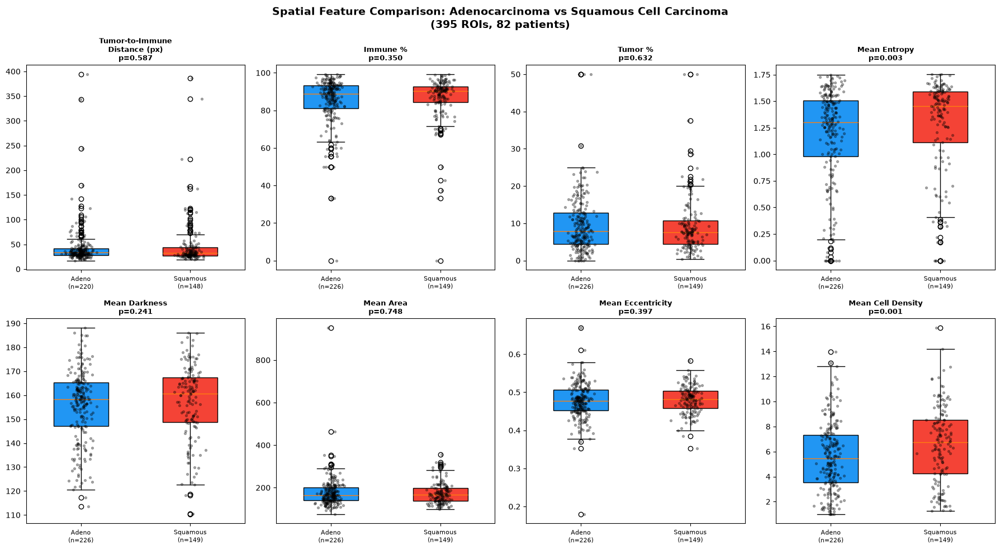

Boxplots saved


In [65]:
#strip plot

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
fig.suptitle('Spatial Feature Comparison: Adenocarcinoma vs Squamous Cell Carcinoma\n(395 ROIs, 82 patients)', 
             fontsize=14, fontweight='bold')
#creates 2x4 grid w/8 subplots (one/feat.)
#suptitle: adds title f/entire plot

features_to_plot = ['tumor_to_immune_dist', 'immune_pct', 'tumor_pct', 
                    'mean_entropy', 'mean_darkness', 'mean_area',
                    'mean_eccentricity', 'mean_cell_density']

labels = ['Tumor-to-Immune\nDistance (px)', 'Immune %', 'Tumor %',
          'Mean Entropy', 'Mean Darkness', 'Mean Area',
          'Mean Eccentricity', 'Mean Cell Density']
#defines 8 feat. to plot & shows labels

plot_df = roi_summary_df[roi_summary_df['histological_subtype'].isin(
    ['adenocarcinoma', 'squamous_cell_carcinoma'])].copy()
#filters to 2 main subtypes (adenocarcinoma & squamous cell carcinoma)
    #excludes small groups bc not enough patients = inaccurate comparison

from scipy.stats import mannwhitneyu

for idx, (feat, label) in enumerate(zip(features_to_plot, labels)):
    ax = axes[idx // 4][idx % 4]
#loops thru 8 feat. @ same time
    #idx // 4: row = 0 or 1
    #idx % 4: col. = 0 - 3
#so plot placed in correct area
    
    adeno_vals = plot_df[plot_df['histological_subtype'] == 'adenocarcinoma'][feat].dropna()
    sq_vals = plot_df[plot_df['histological_subtype'] == 'squamous_cell_carcinoma'][feat].dropna()
    
    bp = ax.boxplot([adeno_vals, sq_vals],
                    patch_artist=True,
                    positions=[1, 2],
                    widths=0.5)
    
    bp['boxes'][0].set_facecolor('#2196F3')
    bp['boxes'][1].set_facecolor('#F44336')
#split data by subtypes
#drops missing vals. 
#draws boxplots @ pos. 1&2
#patch_artist=True: fill box w/color
    #blue = adenocarcinoma
    #red = squamous
    
    ax.scatter(np.random.normal(1, 0.05, len(adeno_vals)), adeno_vals,
               alpha=0.3, s=8, color='black', zorder=3)
    ax.scatter(np.random.normal(2, 0.05, len(sq_vals)), sq_vals,
               alpha=0.3, s=8, color='black', zorder=3)
#individual points on top of boxplots
#np.random.normal(1, 0.05, ...): so points don't stack on top of e/a
#zorder=3: puts points on top of boxes
    
    stat, p = mannwhitneyu(adeno_vals, sq_vals, alternative='two-sided')
    p_text = f'p={p:.3f}' if p >= 0.001 else 'p<0.001'
    
    ax.set_title(f'{label}\n{p_text}', fontsize=9, fontweight='bold')
#Mann Whitney U test on each feat. & formats p val. 
#if p val. less than 0.001 shows p<0.001 instead of decimal
#p val. added to each subplot -> shows statistical significance
    ax.set_xticks([1, 2])
    ax.set_xticklabels([f'Adeno\n(n={len(adeno_vals)})', 
                        f'Squamous\n(n={len(sq_vals)})'], fontsize=8)
    ax.set_ylabel('')

plt.tight_layout()
plt.savefig(os.path.expanduser('data/subtype_comparison_boxplots_395rois.png'),
            dpi=150, bbox_inches='tight')
plt.show()
#adjusts spacing
#put in disk @ 150 DPI & displays
print("Boxplots saved")

In [66]:
#composite immune architecture score

from scipy.stats import zscore

roi_summary_df['dist_z'] = zscore(roi_summary_df['tumor_to_immune_dist'].fillna(roi_summary_df['tumor_to_immune_dist'].mean()))
roi_summary_df['density_z'] = zscore(roi_summary_df['mean_cell_density'].fillna(roi_summary_df['mean_cell_density'].mean()))
roi_summary_df['entropy_z'] = zscore(roi_summary_df['mean_entropy'].fillna(roi_summary_df['mean_entropy'].mean()))
#z scores most bio meaningful spatial feats. 
#.fillna(mean): replacing missing vals. w/col. mean before z scoring 
#z scores so all 3 vals. can be combined into 1 score 

#composite score:
#high immune density + low distance + high entropy = immune hot
#low immune density + high distance + low entropy = immune cold
#in between = immune excluded
roi_summary_df['immune_architecture_score'] = (
    -roi_summary_df['dist_z'] * 0.4 +      # shorter distance = hotter
    roi_summary_df['density_z'] * 0.3 +     # higher density = hotter
    roi_summary_df['entropy_z'] * 0.3       # higher entropy = hotter
)
#combines z scored feat. into 1 composite score
    #distance = not good bc shorter distance = more immune engagement 
    #closer immune cells to tumor cells = hot signal
    #density & entropy positive bc higher = more immune activity
#0.4/0.3/0.3: spatial proximity more important bc directly shows if immune cells physically engage w/tumor cells

low = roi_summary_df['immune_architecture_score'].quantile(0.33)
high = roi_summary_df['immune_architecture_score'].quantile(0.67)

def classify_architecture(score):
    if score >= high:
        return 'Immune Hot'
    elif score <= low:
        return 'Immune Cold'
    else:
        return 'Immune Excluded'

roi_summary_df['immune_architecture'] = roi_summary_df['immune_architecture_score'].apply(classify_architecture)
#divides patients into 3 equal groups (33 & 67 percentiles as cut off)
    #bottom 3rd: immune cold
    #middle 3rd: immune excluded
    #top 3rd: immune hot

print("Immune architecture distribution:")
print(roi_summary_df['immune_architecture'].value_counts())
print("\nBy histological subtype:")
print(pd.crosstab(roi_summary_df['histological_subtype'], roi_summary_df['immune_architecture']))
#makes sure dist. equal across 3 groups

Immune architecture distribution:
immune_architecture
Immune Excluded    133
Immune Hot         131
Immune Cold        131
Name: count, dtype: int64

By histological subtype:
immune_architecture      Immune Cold  Immune Excluded  Immune Hot
histological_subtype                                             
adenocarcinoma                    85               83          58
adenosquamous                      1                3           3
large_cell                         1                2           7
squamous_cell_carcinoma           42               45          62
unknown                            2                0           1


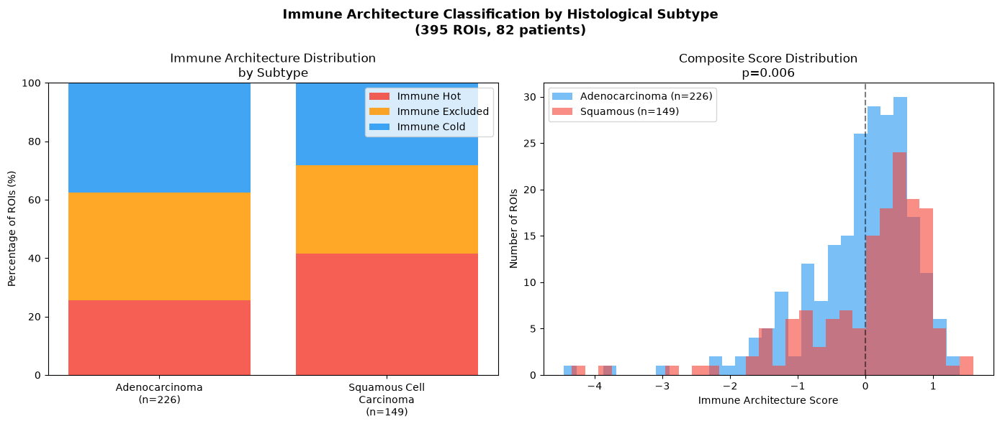

Saved


In [67]:
#immune architecture classification visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Immune Architecture Classification by Histological Subtype\n(395 ROIs, 82 patients)',
             fontsize=13, fontweight='bold')
#1x2 figure w/2 side by side plots
#suptitle does both plots & master title

#plot 1: stacked bar chart
subtypes = ['adenocarcinoma', 'squamous_cell_carcinoma']
labels = ['Adenocarcinoma\n(n=226)', 'Squamous Cell\nCarcinoma\n(n=149)']
colors = {'Immune Hot': '#F44336', 'Immune Excluded': '#FF9800', 'Immune Cold': '#2196F3'}
#2 subtypes to compare
#show label & sample sizes & colors (red = immune hot, orange = immune excluded, blue = immune cold)

plot_data = pd.crosstab(roi_summary_df['histological_subtype'], 
                         roi_summary_df['immune_architecture'],
                         normalize='index') * 100
plot_data = plot_data.loc[subtypes]
#crosstab of subtype v immune architecture 
#row normalize='index': normalizes -> each subtypes vals. sum to 100%
#filters to 2 main subtypes

bottom = np.zeros(len(subtypes))
for arch, color in colors.items():
    if arch in plot_data.columns:
        values = plot_data[arch].values
        axes[0].bar(labels, values, bottom=bottom, 
                   label=arch, color=color, alpha=0.85)
        bottom += values
#loop thru each immune architecture category & stack bar onto of prev. one w/bottom
#iterations add vals. to bottom -> next category starts where prev. ended -> proportional breakdown

axes[0].set_ylabel('Percentage of ROIs (%)')
axes[0].set_title('Immune Architecture Distribution\nby Subtype')
axes[0].legend(loc='upper right')
axes[0].set_ylim(0, 100)
#labels y axis & adds %'s (bc normalized)
#title
#legend

#plot 2: composite score distribution
adeno_scores = roi_summary_df[roi_summary_df['histological_subtype'] == 'adenocarcinoma']['immune_architecture_score'].dropna()
sq_scores = roi_summary_df[roi_summary_df['histological_subtype'] == 'squamous_cell_carcinoma']['immune_architecture_score'].dropna()

axes[1].hist(adeno_scores, bins=30, alpha=0.6, color='#2196F3', label=f'Adenocarcinoma (n={len(adeno_scores)})')
axes[1].hist(sq_scores, bins=30, alpha=0.6, color='#F44336', label=f'Squamous (n={len(sq_scores)})')
#gets composite immune architecture scores f/each subtypes & plots overlapping histograms
#alpha=0.6: semi transparent -> see overlap

stat, p = mannwhitneyu(adeno_scores, sq_scores, alternative='two-sided')
axes[1].set_xlabel('Immune Architecture Score')
axes[1].set_ylabel('Number of ROIs')
axes[1].set_title(f'Composite Score Distribution\np={p:.3f}')
axes[1].legend()
axes[1].axvline(x=0, color='black', linestyle='--', alpha=0.5)
#Mann Whitney test & adds p val to title -> confirms both types have diff immune architecture scores
#axvline(x=0): line @ -> midpoint of composite z score -> ROI to right = immune hot; ROI to left = immune cold

plt.tight_layout()
plt.savefig(os.path.expanduser('data/immune_architecture_classification.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved")
#adjusts space
#saves to disk

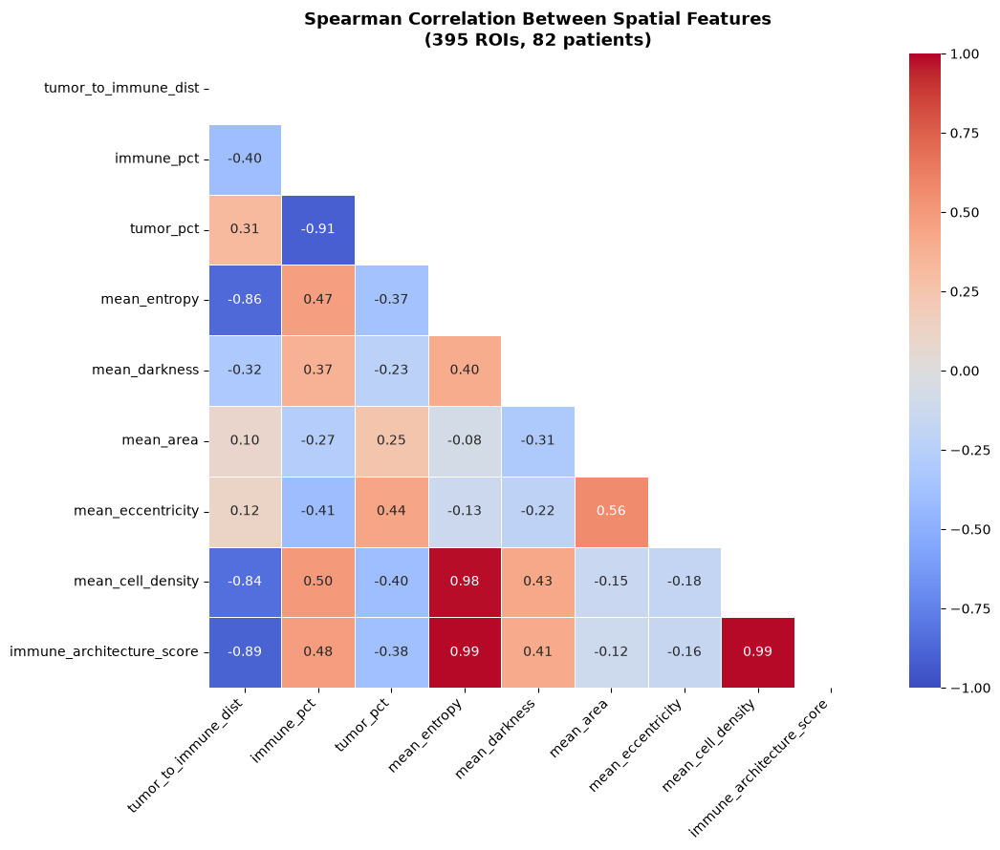

Saved


In [68]:
#feat. correlation analysis
    #which feats. to use in Cox Modeling

import seaborn as sns

corr_features = ['tumor_to_immune_dist', 'immune_pct', 'tumor_pct',
                 'mean_entropy', 'mean_darkness', 'mean_area',
                 'mean_eccentricity', 'mean_cell_density',
                 'immune_architecture_score']

corr_df = roi_summary_df[corr_features].dropna()
#9 most bio meaningful feat. & composite architecture score
#drops rows w/missing vals. before finding correlations
    #only 9 feat. bc makes sure heatmap = readable & most relevant feat. f/Cox Modeling

corr_matrix = corr_df.corr(method='spearman')
#finds Spearman rank correlation bc feat. aren't normally dist. 

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
#makes figure
#mask f/upper tri

sns.heatmap(corr_matrix,
            mask=mask,
            cmap='coolwarm', #blue = neg. correlations; red = pos. correlations
            center=0, #white @ 0
            annot=True, #prints correlation val. in each cell
            fmt='.2f', #2 decimal places
            linewidths=0.5,
            ax=ax,
            vmin=-1,
            vmax=1) #color scale -> correlation comparable across cells
#lower tri heatmap

ax.set_title('Spearman Correlation Between Spatial Features\n(395 ROIs, 82 patients)',
             fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.expanduser('data/feature_correlation_heatmap.png'),
            dpi=150, bbox_inches='tight')
plt.show()
#title
#rotates x axis 45 deg. (no overlap)
#spacing 
#saves to disk
#displays
print("Saved")

In [69]:
#KMeans clustering analysis

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
#KMeans clustering
#StandardScaler: f/normalizarion
#PCA: f/dimensionality reduction

cluster_features = ['tumor_to_immune_dist', 'mean_darkness', 
                    'mean_area', 'mean_eccentricity', 
                    'mean_entropy', 'mean_cell_density']
#6 feat. f/clusering based on correlation heatmap
    #most independent feat. w/low redundancy
    #no immune_pct, tumor_pct, and immune_architecture_score bc derived f/other feats.

cluster_df = roi_summary_df[cluster_features + ['histological_subtype', 'roi']].dropna()
X = cluster_df[cluster_features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
#filters to rows w/complete data & gets feat. vals. in numpy array
#StandardScaler: z score normalizes each feat. 
    #for KMeans bc Euclidean distance & feat. would scale diff. -> clustering = biased -> scaling needed

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_df['cluster'] = kmeans.fit_predict(X_scaled)
#KMeans w/3 clusters matches rule-based hot/excluded/cold classification 
#random_state=42: makes results reproducible 
#n_init=10: runs algorithm 10 times w/diff staring points & keeps best result 

# Label clusters by their mean immune architecture score
cluster_means = cluster_df.groupby('cluster')['tumor_to_immune_dist'].mean()
sorted_clusters = cluster_means.sort_values()
cluster_labels = {sorted_clusters.index[0]: 'Immune Hot',
                  sorted_clusters.index[1]: 'Immune Excluded', 
                  sorted_clusters.index[2]: 'Immune Cold'}
cluster_df['cluster_label'] = cluster_df['cluster'].map(cluster_labels)
#KMeans makes clusters w/no bio meaning
#gives labels by ranking clusters on mean tumor to immune distance
    #shortest distance: labeled immune hot (immune cells are closest of tumor cells)
    #longest distance: labeled immune cold (immune cells are farthest from tumor cells)


print("K-means cluster distribution:")
print(cluster_df['cluster_label'].value_counts())
print("\nCluster vs histological subtype:")
print(pd.crosstab(cluster_df['histological_subtype'], cluster_df['cluster_label']))
#prints num. of ROIs in each cluster & cross tabulation by subtype

merged = cluster_df.merge(roi_summary_df[['roi', 'immune_architecture']], on='roi')
print("\nAgreement between k-means and rule-based:")
print(pd.crosstab(merged['cluster_label'], merged['immune_architecture']))
#merges KMeans cluster labels w/rule based architecture labels on ROI name
#cross tabulates shows how methods agree

K-means cluster distribution:
cluster_label
Immune Hot         208
Immune Excluded    117
Immune Cold         63
Name: count, dtype: int64

Cluster vs histological subtype:
cluster_label            Immune Cold  Immune Excluded  Immune Hot
histological_subtype                                             
adenocarcinoma                    36               68         116
adenosquamous                      1                2           4
large_cell                         1                1           8
squamous_cell_carcinoma           25               44          79
unknown                            0                2           1

Agreement between k-means and rule-based:
immune_architecture  Immune Cold  Immune Excluded  Immune Hot
cluster_label                                                
Immune Cold                   63                0           0
Immune Excluded               39               60          18
Immune Hot                    22               73         113


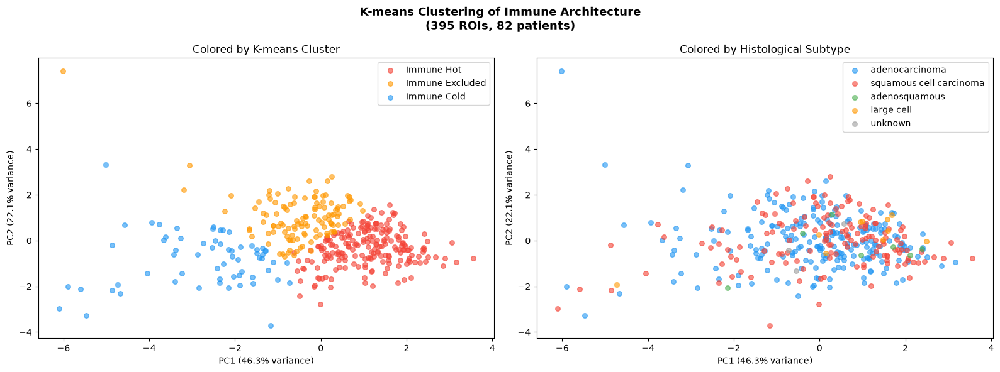

Saved


In [70]:
#PCA visualization of KMeans clusters

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

cluster_df['pca1'] = X_pca[:, 0]
cluster_df['pca2'] = X_pca[:, 1]
#principal component analysis compresses 6 feat. to 2 dimensions f/visualization
#PCA finds 2 direcctions f/max variance in data
#2 PCA coord. get stored as new cols. -> used f/x&y axes f/scatter plots

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('K-means Clustering of Immune Architecture\n(395 ROIs, 82 patients)',
             fontsize=13, fontweight='bold')
#makes 2 side by side plots (same PCA, diff coloring) -> compare cluster structure v subtype structure

#plot 1: colored by cluster label
cluster_colors = {'Immune Hot': '#F44336', 'Immune Excluded': '#FF9800', 'Immune Cold': '#2196F3'}
for label, color in cluster_colors.items():
    mask = cluster_df['cluster_label'] == label
    axes[0].scatter(cluster_df[mask]['pca1'], cluster_df[mask]['pca2'],
                   c=color, label=label, alpha=0.6, s=30)

axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
axes[0].set_title('Colored by K-means Cluster')
axes[0].legend()
#loops thru each cluster label -> filters to only those ROIs -> plots as colored dots
#x axis: % if variance by PC1 -> plot = self documenting

#plot 2: colored by histological subtype
subtype_colors = {'adenocarcinoma': '#2196F3', 
                  'squamous_cell_carcinoma': '#F44336',
                  'adenosquamous': '#4CAF50',
                  'large_cell': '#FF9800',
                  'unknown': '#9E9E9E'}

for subtype, color in subtype_colors.items():
    mask = cluster_df['histological_subtype'] == subtype
    if mask.sum() > 0:
        axes[1].scatter(cluster_df[mask]['pca1'], cluster_df[mask]['pca2'],
                       c=color, label=subtype.replace('_', ' '), alpha=0.6, s=30)
#if mask.sum() > 0: stops errors f/subtypes w/no ROIs in cluster dataframe
#.replace('_', ' '): underscores -> spaces f/legend lables (more readable)

axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
axes[1].set_title('Colored by Histological Subtype')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.expanduser('data/kmeans_pca_plot.png'),
            dpi=150, bbox_inches='tight')
plt.show()
#label axes
#legend
#saves to downloads 
#shows plot
print("Saved")

In [71]:
#TCGA patients
tcga_patients = data_overview[data_overview['original_tcga_id'].notna() & 
                               (data_overview['original_tcga_id'] != '')]

print(f"Patients with TCGA IDs: {tcga_patients['patient_id'].nunique()}")
print(f"\nSample TCGA IDs:")
print(tcga_patients[['patient_id', 'original_tcga_id', 'histological_subtype']].drop_duplicates('patient_id').head(10))
#check num. of IGNITE patients w/TCGA IDs that could be linked to survival data
#14 patients: not enough for Cox modeling

Patients with TCGA IDs: 14

Sample TCGA IDs:
     patient_id         original_tcga_id     histological_subtype
69           21  TCGA-22-1012-01Z-00-DX1  squamous_cell_carcinoma
72           22  TCGA-50-5931-01Z-00-DX1           adenocarcinoma
77           23  TCGA-50-6673-01Z-00-DX1           adenocarcinoma
80           24  TCGA-55-7728-01Z-00-DX1           adenocarcinoma
83           25  TCGA-55-8089-01Z-00-DX1           adenocarcinoma
86           26  TCGA-56-8504-01Z-00-DX1  squamous_cell_carcinoma
91           27  TCGA-62-A46O-01Z-00-DX1           adenocarcinoma
98           28  TCGA-77-A5GB-01Z-00-DX1  squamous_cell_carcinoma
104          29  TCGA-86-8280-01Z-00-DX1           adenocarcinoma
107          30  TCGA-97-7938-01Z-00-DX1           adenocarcinoma


In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
import scipy.stats as stats
#imports logistic regression 
#scaling f/sklearn
#cross visualization f/model eval. 
#scipy f/statistical testing

model_df = roi_summary_df[roi_summary_df['histological_subtype'].isin(
    ['adenocarcinoma', 'squamous_cell_carcinoma'])].copy().dropna(
    subset=['tumor_to_immune_dist', 'mean_entropy', 'mean_darkness',
            'mean_area', 'mean_eccentricity', 'mean_cell_density'])
#filters to only adeno & squa ROIs + drops rows w/missing vals. in 6 feat. modeled

model_df['outcome'] = (model_df['histological_subtype'] == 'squamous_cell_carcinoma').astype(int)
#binary outcome var. 0 = adeno, 1 = squa -> what logisitic regression predicts

features = ['tumor_to_immune_dist', 'mean_entropy', 'mean_darkness',
            'mean_area', 'mean_eccentricity', 'mean_cell_density']
#6 most independent feat. based on correlation heatmap (avoid multicollinearity in model)

print(f"{'Feature':<25} {'Odds Ratio':>12} {'95% CI':>20} {'p-value':>10}")
print("-" * 70)

for feat in features:
    X = model_df[[feat]].values
    y = model_df['outcome'].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
#loops thru feat. individually (univariate analysis -> one feat. @ time)
#StandardScaler zscores feat. -> odds ratio = interpretable (change in odds/one SD inc.)
    
    lr = LogisticRegression(random_state=42)
    lr.fit(X_scaled, y)
    
    import statsmodels.api as sm
    X_sm = sm.add_constant(X_scaled)
    logit_model = sm.Logit(y, X_sm)
    result = logit_model.fit(disp=0)
#statsmodels to fit logistic regression bc gives p vals. & confidence intervals
#sm.add_constant: adds intercept term
#disp=0: supresses optimization output
    
    coef = result.params[1]
    odds_ratio = np.exp(coef)
    ci_low = np.exp(result.conf_int()[0][1])
    ci_high = np.exp(result.conf_int()[1][1])
    p_val = result.pvalues[1]
#gets coeff. f/feat. (0 = intercept -> starts @ index 1) -> converts to odds ratio (exponentiating) -> computes f/95% of confidence intervals -> gets p val.
    #odds ratio>1 higher feat. val. associated w/squa
    #odds ratio<1 higher feat. val. associated w/adeno
    
    print(f"{feat:<25} {odds_ratio:>12.3f} {f'({ci_low:.2f}-{ci_high:.2f})':>20} {p_val:>10.4f}")

Feature                     Odds Ratio               95% CI    p-value
----------------------------------------------------------------------
tumor_to_immune_dist             1.090          (0.83-1.34)     0.4122
mean_entropy                     1.221          (0.83-1.52)     0.0717
mean_darkness                    1.070          (0.83-1.32)     0.5292
mean_area                        0.907          (0.83-1.14)     0.4036
mean_eccentricity                1.044          (0.83-1.29)     0.6872
mean_cell_density                1.383          (0.82-1.71)     0.0029


In [73]:
!pip install statsmodels

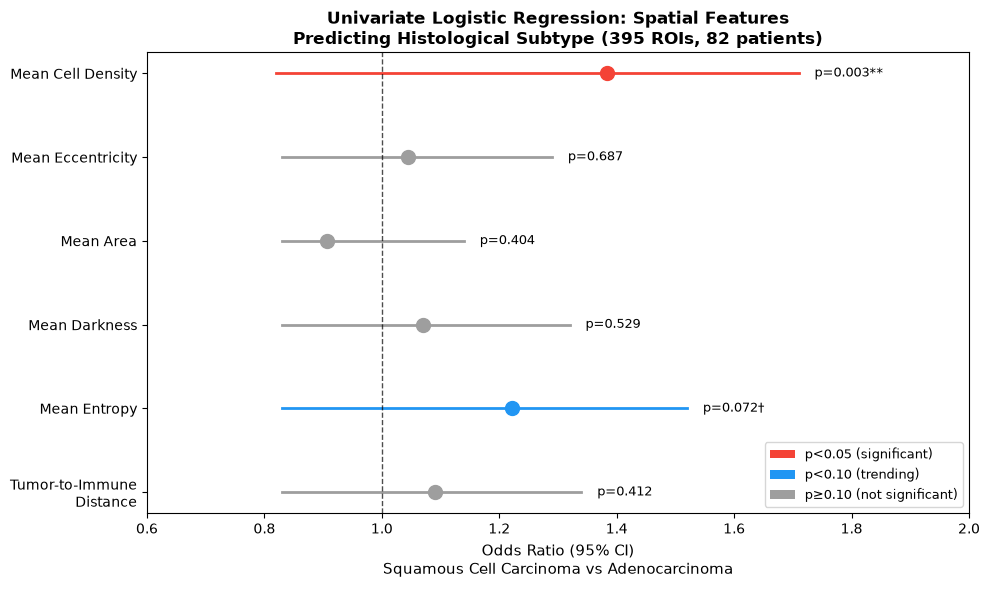

Forest plot saved


In [86]:
#univariate logistic regression: spatial feat. predicting histological subtype

import matplotlib.pyplot as plt
import numpy as np
#matplotlib f/plotting
#numpy f/y axis pos. array 

features = ['tumor_to_immune_dist', 'mean_entropy', 'mean_darkness',
            'mean_area', 'mean_eccentricity', 'mean_cell_density']

odds_ratios = [1.090, 1.221, 1.070, 0.907, 1.044, 1.383]
ci_low =      [0.83,  0.83,  0.83,  0.83,  0.83,  0.82]
ci_high =     [1.34,  1.52,  1.32,  1.14,  1.29,  1.71]
p_values =    [0.412, 0.072, 0.529, 0.404, 0.687, 0.003]

labels = ['Tumor-to-Immune\nDistance', 'Mean Entropy', 'Mean Darkness',
          'Mean Area', 'Mean Eccentricity', 'Mean Cell Density']
#univariate logistic regression: odds ratios; 95% confidence interval; p val. f/6 feat.
#labels list: nanmes f/y axis 
#vals. f/statsmodels logistic regression output

fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(features))
#creates fig. & generates y axis pos. 0-5 -> one pos./feat. -> each feat. = own horiz. row in plot

for i, (or_val, low, high, p) in enumerate(zip(odds_ratios, ci_low, ci_high, p_values)):
    color = '#F44336' if p < 0.05 else '#2196F3' if p < 0.1 else '#9E9E9E'
#loops thru 6 feat. @ same time w/zip
#color assigned based on statistical significance -> red = p<0.05 (significant); blue = p<0.10 (trending); gray = not significant
    ax.plot([low, high], [i, i], color=color, linewidth=2)
    ax.scatter(or_val, i, color=color, s=100, zorder=5)
#confidence interval = horiz. line f/low to high @ row i
#filled dot @ odds ratio estimate -> zorder=5: puts dot @ top of line
    
    sig = '**' if p < 0.01 else '*' if p < 0.05 else '†' if p < 0.1 else ''
    ax.text(high + 0.02, i, f' p={p:.3f}{sig}', va='center', fontsize=9)
#significance marker: ** f/p<0.01; * f/p<0.05; † f/trending
#prints p val. 
#0.02: so text doesn't overlap

ax.axvline(x=1, color='black', linestyle='--', alpha=0.7, linewidth=1)
#draws reference lines @ odds ratio = 1 -> null hypothesis line (if feat. confidence interval crosses 1 = feat. doesn't distinguish between 2 subtypes -> above 1 squa; below 1 adeno) 
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=10)
ax.set_xlabel('Odds Ratio (95% CI)\nSquamous Cell Carcinoma vs Adenocarcinoma', fontsize=11)
ax.set_title('Univariate Logistic Regression: Spatial Features\nPredicting Histological Subtype (395 ROIs, 82 patients)',
             fontsize=12, fontweight='bold')
ax.set_xlim(0.6, 2.0)
#y axis pos. & labels 
#x axis label & range 0.6 - 2 (fits into confidence intervals)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#F44336', label='p<0.05 (significant)'),
    Patch(facecolor='#2196F3', label='p<0.10 (trending)'),
    Patch(facecolor='#9E9E9E', label='p≥0.10 (not significant)')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
#legend w/colored patches (based on significance colors)
#patch: small colored rect. f/each category

plt.tight_layout()
plt.savefig(os.path.expanduser('data/forest_plot.png'),
            dpi=150, bbox_inches='tight')
plt.show()
#adjusts spacing
#saves @ 150 DPI
#displays
print("Forest plot saved")

In [77]:
#TCGA clinical outcome data (f/Cox model)

import pandas as pd
#pandas f/reading & using excel file

tcga_cdr = pd.read_excel(os.path.expanduser("data/1-s2.0-S0092867418302290-mmc1.xlsx"))
#loads TCGA supplemental table -> dataset

print(f"Shape: {tcga_cdr.shape}")
print(f"Columns: {tcga_cdr.columns.tolist()[:15]}")
#makes sure file loaded

lung = tcga_cdr[tcga_cdr['type'].isin(['LUAD', 'LUSC'])]
#filters to only adeno & squa
print(f"\nLung cancer patients: {len(lung)}")
print(lung['type'].value_counts())
print(f"\nSample survival columns:")
print(lung[['bcr_patient_barcode', 'type', 'OS', 'OS.time', 'PFI', 'PFI.time']].head(10))
#count & subtype dist. 
#OS: survival (1 = dead; 0 = alive)
#OS.time: days survived
#PFI: progression free interval status
#PFI.time: days until progression

Shape: (11160, 34)
Columns: ['Unnamed: 0', 'bcr_patient_barcode', 'type', 'age_at_initial_pathologic_diagnosis', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'clinical_stage', 'histological_type', 'histological_grade', 'initial_pathologic_dx_year', 'menopause_status', 'birth_days_to', 'vital_status', 'tumor_status']

Lung cancer patients: 1026
type
LUAD    522
LUSC    504
Name: count, dtype: int64

Sample survival columns:
     bcr_patient_barcode  type   OS  OS.time  PFI  PFI.time
5802        TCGA-05-4244  LUAD  0.0      0.0  0.0       0.0
5803        TCGA-05-4245  LUAD  0.0    730.0  1.0     334.0
5804        TCGA-05-4249  LUAD  0.0   1523.0  0.0    1523.0
5805        TCGA-05-4250  LUAD  1.0    121.0  0.0     121.0
5806        TCGA-05-4382  LUAD  0.0    607.0  1.0     334.0
5807        TCGA-05-4384  LUAD  0.0    426.0  1.0     183.0
5808        TCGA-05-4389  LUAD  0.0   1369.0  0.0    1369.0
5809        TCGA-05-4390  LUAD  0.0   1126.0  1.0     395.0
5810        TCGA-05-4395  LUA

In [76]:
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]━━ 1/2 [openpyxl]


In [78]:
# Get the 14 TCGA patients from IGNITE
tcga_ignite = data_overview[data_overview['original_tcga_id'].notna() & 
                            (data_overview['original_tcga_id'] != '') &
                            (data_overview['task'] == 'he_tissue_segmentation')].copy()
#filters IGNITE data overview to rows w/TCGA patient ID in original_tcga_id col. & belong to H&E tissue segmentation task
#.notna(): doesnt inc rows where TCGA ID missing
#!= '': doesnt inc empty strings
#task filter makes sure only H&E images not IHC

tcga_ignite['tcga_barcode'] = tcga_ignite['original_tcga_id'].str[:12]
#makes sure TCGA barcodes match CDR format 

lung_survival = lung[['bcr_patient_barcode', 'type', 'OS', 'OS.time', 'PFI', 'PFI.time']].copy()
lung_survival['tcga_barcode'] = lung_survival['bcr_patient_barcode'].str[:12]
#gets survival outcomes needed f/TCGA CDR dataframe -> created barcode col. -> dataframes have matching key to join

merged = tcga_ignite.merge(lung_survival, on='tcga_barcode', how='inner')
#inner join on barcode -> only patient in IGNITE dataset & TCGA CDR survival data
#how='inner': patients that don't match are dropped
print(f"Matched patients: {merged['patient_id'].nunique()}")
print(merged[['patient_id', 'tcga_barcode', 'OS', 'OS.time', 'PFI', 'PFI.time']].drop_duplicates('patient_id'))
#drop_duplicates('patient_id'): one row/patient -> each patient has mult. ROIs in IGNITE dataset 

Matched patients: 14
    patient_id  tcga_barcode   OS  OS.time  PFI  PFI.time
0           21  TCGA-22-1012  1.0    429.0  0.0     429.0
3           22  TCGA-50-5931  1.0    434.0  1.0     425.0
8           23  TCGA-50-6673  1.0     22.0  0.0      22.0
11          24  TCGA-55-7728  0.0    704.0  0.0     704.0
14          25  TCGA-55-8089  1.0    702.0  0.0     702.0
17          26  TCGA-56-8504  0.0    510.0  0.0     510.0
22          27  TCGA-62-A46O  1.0   1454.0  1.0     943.0
29          28  TCGA-77-A5GB  1.0    937.0  1.0     229.0
35          29  TCGA-86-8280  0.0    701.0  0.0     701.0
38          30  TCGA-97-7938  1.0     18.0  0.0      18.0
41          31  TCGA-98-A53D  1.0    645.0  1.0     413.0
45          32  TCGA-J1-A4AH  0.0    581.0  0.0     581.0
49          33  TCGA-MF-A522  1.0    360.0  1.0     173.0
52          34  TCGA-NC-A5HF  1.0    138.0  1.0     132.0


### Cox survival models (exploratory)
Only 14 patients have both these spatial features and linked TCGA survival data (10 events). Six univariate Cox models and one multivariable model (ridge penalty 0.1) are fitted, with no correction for multiple testing. Hazard ratios are per standard deviation of each z-scored feature. Treat these as hypothesis-generating, not as evidence of prognostic value.

In [81]:
from lifelines import CoxPHFitter
import warnings
warnings.filterwarnings('ignore')
#imports Cox proportional hazards fitter f/lifelines library (Python survival analysis package)
#suppresses warnings that happen during model fitting w/small sample sizes

tcga_patient_ids = merged['patient_id'].unique()

tcga_features = []
for _, match_row in merged.drop_duplicates('patient_id').iterrows():
    patient_id = match_row['patient_id']
#gets list of TCGA patient IDs & loops thru
#drop_duplicates('patient_id'): makes sure patient processed one @ a time bc mult. ROIs
    
    patient_rois = {k: v for k, v in all_patient_dfs.items() 
                   if f'patient{patient_id}_' in k}
#ROIs in patient by looking thru dictionary keys f/patient ID pattern
    #using all ROIs bc more representative feat. avg f/patient
    
    if not patient_rois:
        print(f"No ROIs found for patient {patient_id}")
        continue
    
    all_dfs = list(patient_rois.values())
    combined = pd.concat(all_dfs, ignore_index=True)
#gets all ROI in dataframe f/patient & puts them into 1 large dataframe (cells f/all ROIs in 1 place)
#ignore_index=True: resets row #'s -> no duplicate indices 
    
    row = {
        'patient_id': patient_id,
        'OS': match_row['OS'],
        'OS.time': match_row['OS.time'],
        'PFI': match_row['PFI'],
        'PFI.time': match_row['PFI.time'],
        'tumor_to_immune_dist': combined[combined['cell_type'] == 'tumor']['dist_to_nearest_immune'].mean() if 'dist_to_nearest_immune' in combined.columns else np.nan,
        'immune_pct': (combined['cell_type'] == 'immune').mean() * 100,
        'mean_entropy': combined['entropy'].mean(),
        'mean_darkness': combined['darkness'].mean(),
        'mean_area': combined['area'].mean(),
        'mean_cell_density': combined['cell_density'].mean(),
    }
    tcga_features.append(row)
#one summary row per patient combining survival outcomes f/TCGA CDR w/spatial feat. avg across cells in ROIs
    #gives 1 representative val. per patient f/Cox model

tcga_df = pd.DataFrame(tcga_features)
print(f"Patients with features: {len(tcga_df)}")
print(tcga_df[['patient_id', 'OS', 'OS.time', 'tumor_to_immune_dist', 'immune_pct', 'mean_entropy']].to_string())
#puts patient summaries into clean dataframe & prints to confirm every patient has survival data & spatial feat.

Patients with features: 14
    patient_id   OS  OS.time  tumor_to_immune_dist  immune_pct  mean_entropy
0           21  1.0    429.0             38.794687   94.111192      1.320646
1           22  1.0    434.0             33.442252   80.116959      1.189022
2           23  1.0     22.0             32.983534   84.147386      1.338982
3           24  0.0    704.0             36.410921   89.230769      1.212052
4           25  1.0    702.0             36.094893   88.438438      1.363424
5           26  0.0    510.0             38.902003   77.435575      1.321727
6           27  1.0   1454.0             48.059993   83.410138      0.976327
7           28  1.0    937.0             39.341926   92.153228      1.552160
8           29  0.0    701.0             36.906086   90.213178      1.446246
9           30  1.0     18.0             29.881786   88.975357      1.487328
10          31  1.0    645.0             38.179769   77.893057      1.354880
11          32  0.0    581.0             38.51355

In [80]:
!pip install lifelines

In [82]:
#Cox modeling

from lifelines import CoxPHFitter
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')
#imports Cox model fitter 
#suppresses convergence warnings that show up w/small sample sizes

cox_features = ['tumor_to_immune_dist', 'immune_pct', 'mean_entropy', 
                'mean_darkness', 'mean_area', 'mean_cell_density']

cox_df = tcga_df[cox_features + ['OS', 'OS.time']].dropna()
print(f"Patients for Cox model: {len(cox_df)}")
#6 independent feat. based on correlation heatmap + 2 survival cols.
#dropna(): removes patient w/missing vals. -> complete data (not dropped)

scaler = StandardScaler()
cox_df_scaled = cox_df.copy()
cox_df_scaled[cox_features] = scaler.fit_transform(cox_df[cox_features])
#zscore normalizes 6 feat. before fitting -> hazard ratios interpretable (change in one risk per SD inc. in feat.) -> w/o scaling incomparable hazard ratios

print(f"\n{'Feature':<25} {'HR':>8} {'95% CI':>20} {'p-value':>10}")
print("-" * 70)

for feat in cox_features:
    cph = CoxPHFitter()
    try:
        cph.fit(cox_df_scaled[['OS.time', 'OS', feat]], 
                duration_col='OS.time', event_col='OS')
#loops thru each feat. & fits separate univariate Cox model (one feat @ time)
#univariate analysis -> tests feats. individ. association w/survival w/o controlling other feat. 
#duration_col='OS.time': tells model how long patient was followed
#event_col='OS': if died during follow up
        
        hr = np.exp(cph.params_[feat])
        ci_low = np.exp(cph.confidence_intervals_.loc[feat, '95% lower-bound'])
        ci_high = np.exp(cph.confidence_intervals_.loc[feat, '95% upper-bound'])
        p = cph.summary.loc[feat, 'p']
        print(f"{feat:<25} {hr:>8.3f} {f'({ci_low:.2f}-{ci_high:.2f})':>20} {p:>10.4f}")
#gets results f/fitted model
#Cox model has coeff. as log hazard ratios -> converts to hazard ratios = more interpretable (thru exponenation) -> applied to confidence interval bounds
#hazard ratio < 1 = feat. = protective; >1 = associated w/worse survival
    except Exception as e:
        print(f"{feat:<25} ERROR: {e}")

print("\n--- Multivariable Cox Model ---")
cph_multi = CoxPHFitter(penalizer=0.1)
cph_multi.fit(cox_df_scaled[['OS.time', 'OS'] + cox_features],
              duration_col='OS.time', event_col='OS')
cph_multi.print_summary()
#fits multivariable Cox model w/6 feats.
#penalizer=0.1: adds L2 regularization (prevents overfitting)

Patients for Cox model: 14

Feature                         HR               95% CI    p-value
----------------------------------------------------------------------
tumor_to_immune_dist         0.314          (0.14-0.72)     0.0059
immune_pct                   1.139          (0.58-2.24)     0.7058
mean_entropy                 1.722          (0.88-3.37)     0.1134
mean_darkness                1.602          (0.82-3.14)     0.1700
mean_area                    0.639          (0.30-1.38)     0.2567
mean_cell_density            1.646          (0.91-2.97)     0.0982

--- Multivariable Cox Model ---


<lifelines.CoxPHFitter: fitted with 14 total observations, 4 right-censored observations>
             duration col = 'OS.time'
                event col = 'OS'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 14
number of events observed = 10
   partial log-likelihood = -14.23
         time fit was run = 2026-07-16 20:12:58 UTC

---
                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                             
tumor_to_immune_dist -1.03      0.36      0.52           -2.05           -0.01                0.13                0.99
immune_pct           -0.11      0.90      0.53           -1.16            0.94                0.31                2.55
mean_entropy          0.13      1.13      0.58           -1.02            1.27                0.36                3.56
mean_darkness         0.40      1.49      0.42           -0.42            1.23                0.65                3.41
mean_area            -0.06      0.95      0.56           -1.16            1.04                0.31                2.84
mean_cell_density    -0.24      0.79      0.55           -1.32            0.84                0.27                2.32

                      cmp to     z    p  -log2(p)
covariate                                        
tumor_to_immune_dist    0.00 -1.99 0.05      4.41
immune_pct              0.00 -0.21 0.84      0.26
mean_entropy            0.00  0.22 0.83      0.27
mean_darkness           0.00  0.95 0.34      1.56
mean_area               0.00 -0.10 0.92      0.12
mean_cell_density       0.00 -0.43 0.66      0.59
---
Concordance = 0.81
Partial AIC = 40.46
log-likelihood ratio test = 8.45 on 6 df
-log2(p) of ll-ratio test = 2.27

Median tumor-to-immune distance: 36.7 pixels
immune_group
Immune Cold\n(long distance)    7
Immune Hot\n(short distance)    7
Name: count, dtype: int64


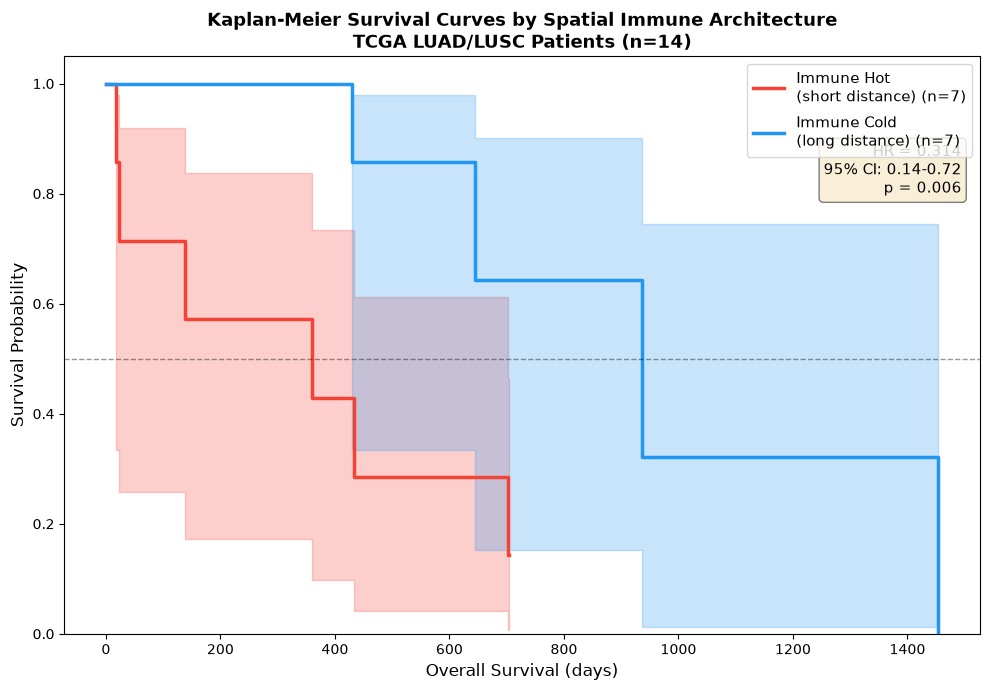

Kaplan-Meier curve saved


In [83]:
#Kaplan Meier survival visualization

from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt
#Kaplan-Meier fitter f/lifelines 
#matplotlib f/plotting

median_dist = tcga_df['tumor_to_immune_dist'].median()
tcga_df['immune_group'] = tcga_df['tumor_to_immune_dist'].apply(
    lambda x: 'Immune Hot\n(short distance)' if x <= median_dist else 'Immune Cold\n(long distance)'
)
#splits patients -> 2 groups w/median tumor-to-immune distance as cutoff
    #makes KM curves more visually balanced

print(f"Median tumor-to-immune distance: {median_dist:.1f} pixels")
print(tcga_df['immune_group'].value_counts())

fig, ax = plt.subplots(figsize=(10, 7))

colors = {'Immune Hot\n(short distance)': '#F44336',  #red
          'Immune Cold\n(long distance)': '#2196F3'} #blue
#makes fig

for group, color in colors.items():
    mask = tcga_df['immune_group'] == group
    kmf = KaplanMeierFitter()
    kmf.fit(tcga_df[mask]['OS.time'], 
            tcga_df[mask]['OS'],
            label=f'{group} (n={mask.sum()})')
    kmf.plot_survival_function(ax=ax, color=color, linewidth=2.5)
#loops thru both groups each one gets KaplanMeierFitter: fits on groups survival times & event indicators & plots survival curve
    #KaplanMeier estimator finds probability of surviving past each time point 
    #curve steps down each time death happens
#OS.time: gives time axis
#OS: died (1) or alive (0)

ax.axhline(y=0.5, color='black', linestyle='--', alpha=0.4, linewidth=1)
#horiz. dashed line @ survival probability 0.5 -> median survival line
    #where KM curve crosses line = median survival time f/group

ax.set_xlabel('Overall Survival (days)', fontsize=12)
ax.set_ylabel('Survival Probability', fontsize=12)
ax.set_title('Kaplan-Meier Survival Curves by Spatial Immune Architecture\nTCGA LUAD/LUSC Patients (n=14)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0, 1.05)

ax.text(0.98, 0.85, 
        f'HR = 0.314\n95% CI: 0.14-0.72\np = 0.006',
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
#adds annotation w/hazard ratio; confidence interval; p val. f/Cox model
#transform=ax.transAxes: uses relative coord. (0-1) not data coord.

plt.tight_layout()
plt.savefig(os.path.expanduser('data/kaplan_meier_survival.png'),
            dpi=150, bbox_inches='tight')
plt.show()
#spacing
#save to disk
#display
print("Kaplan-Meier curve saved")

In [84]:
#Cox model w/composite immune architecture score predictor

tcga_patient_ids = tcga_df['patient_id'].tolist()

arch_scores = []
for pid in tcga_patient_ids:
    patient_rois = roi_summary_df[roi_summary_df['patient_id'] == pid]
    if len(patient_rois) > 0:
        arch_scores.append({
            'patient_id': pid,
            'mean_architecture_score': patient_rois['immune_architecture_score'].mean(),
            'pct_immune_hot': (patient_rois['immune_architecture'] == 'Immune Hot').mean() * 100
        })
#loops thru TCGA patient IDs & finds ROIs in roi_summary_df dataframe
#avg each patient immune architecture score across ROIs & finds % of ROIs are immune hot
    #gives 1 architecture score per patient not one per ROI

arch_df = pd.DataFrame(arch_scores)
tcga_df = tcga_df.merge(arch_df, on='patient_id', how='left')
#converts architecture scores into dataframe & merges into your tcga_df (has survival data & morphological feat.)
#how='left': keeps all patients even if no architecture score found

print("Architecture scores for TCGA patients:")
print(tcga_df[['patient_id', 'OS', 'OS.time', 'mean_architecture_score', 'pct_immune_hot']].to_string())

cox_df2 = tcga_df[['OS.time', 'OS', 'mean_architecture_score']].dropna()
scaler2 = StandardScaler()
cox_df2_scaled = cox_df2.copy()
cox_df2_scaled['mean_architecture_score'] = scaler2.fit_transform(
    cox_df2[['mean_architecture_score']])
#clean dataset w/survival cols. & architecture score -> drops missing vals. & zscore normalizes architecture score
    #same process as main Cox model -> normalize hazard ratio -> risk change per one SD inc in architecture score

cph2 = CoxPHFitter()
cph2.fit(cox_df2_scaled, duration_col='OS.time', event_col='OS')

hr = np.exp(cph2.params_['mean_architecture_score'])
ci_low = np.exp(cph2.confidence_intervals_.loc['mean_architecture_score', '95% lower-bound'])
ci_high = np.exp(cph2.confidence_intervals_.loc['mean_architecture_score', '95% upper-bound'])
p = cph2.summary.loc['mean_architecture_score', 'p']

print(f"\nComposite Architecture Score Cox Result:")
print(f"HR = {hr:.3f} ({ci_low:.2f}-{ci_high:.2f}), p = {p:.4f}")
#fits univariate Cox model w/architecture score as predictor & gets hazard ratio; confidence interval; p val.

Architecture scores for TCGA patients:
    patient_id   OS  OS.time  mean_architecture_score  pct_immune_hot
0           21  1.0    429.0                -0.301768        0.000000
1           22  1.0    434.0                -0.336213        0.000000
2           23  1.0     22.0                 0.114456        0.000000
3           24  0.0    704.0                -0.174929        0.000000
4           25  1.0    702.0                 0.103493       33.333333
5           26  0.0    510.0                -0.142040        0.000000
6           27  1.0   1454.0                -0.706689        0.000000
7           28  1.0    937.0                 0.326558       50.000000
8           29  0.0    701.0                -0.192076       33.333333
9           30  1.0     18.0                 0.393100       33.333333
10          31  1.0    645.0                -0.149632       25.000000
11          32  0.0    581.0                -0.286477        0.000000
12          33  1.0    360.0                 1.0020

The hazard ratios, confidence intervals and p-values in the next cell are **typed in from the printed Cox outputs above** (univariate results and the composite architecture score result) so the forest plot can be drawn. They are not recomputed in this cell.

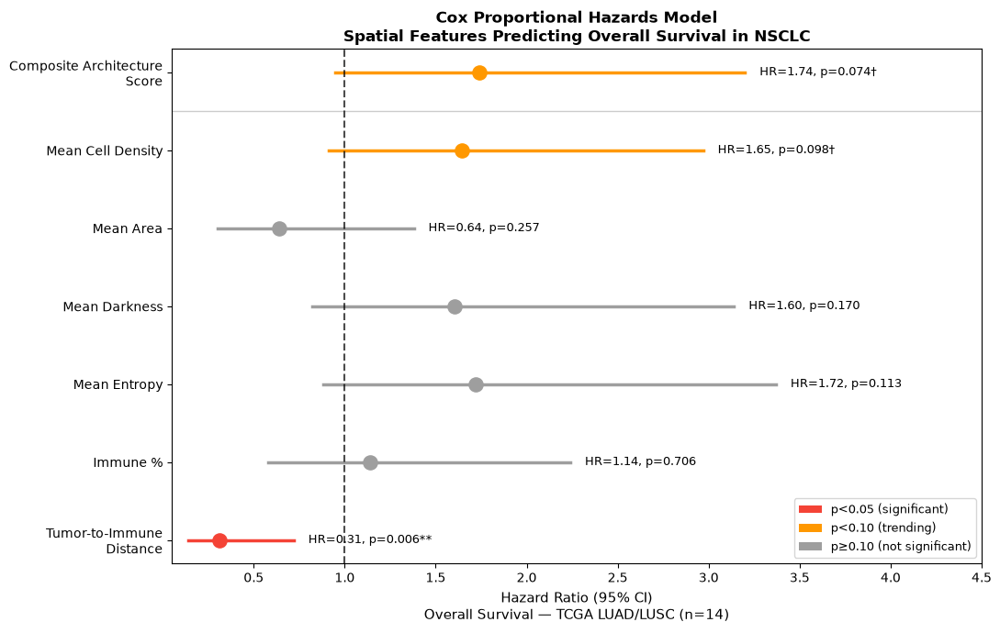

Final Cox forest plot saved


In [85]:
#Cox model based on spatial feat. 

fig, ax = plt.subplots(figsize=(11, 7))

all_features = ['tumor_to_immune_dist', 'immune_pct', 'mean_entropy', 
                'mean_darkness', 'mean_area', 'mean_cell_density',
                'mean_architecture_score']

all_labels = ['Tumor-to-Immune\nDistance', 'Immune %', 'Mean Entropy',
              'Mean Darkness', 'Mean Area', 'Mean Cell Density',
              'Composite Architecture\nScore']

all_hrs =    [0.314, 1.139, 1.722, 1.602, 0.639, 1.646, 1.741]
all_ci_low = [0.14,  0.58,  0.88,  0.82,  0.30,  0.91,  0.95]
all_ci_high =[0.72,  2.24,  3.37,  3.14,  1.38,  2.97,  3.20]
all_pvals =  [0.006, 0.706, 0.113, 0.170, 0.257, 0.098, 0.074]
#hardcodes Cox model results inc. composite architecture score as 7th feat.
    #came f/univariate Cox model & architecture score model

y_pos = np.arange(len(all_features))

for i, (hr, low, high, p, label) in enumerate(zip(all_hrs, all_ci_low, all_ci_high, all_pvals, all_labels)):
    if p < 0.05:
        color = '#F44336'
    elif p < 0.10:
        color = '#FF9800'
    else:
        color = '#9E9E9E'
    
    ax.plot([low, high], [i, i], color=color, linewidth=2.5)
    ax.scatter(hr, i, color=color, s=120, zorder=5)
    
    sig = '**' if p < 0.01 else '*' if p < 0.05 else '†' if p < 0.1 else ''
    ax.text(high + 0.08, i, f'HR={hr:.2f}, p={p:.3f}{sig}', 
            va='center', fontsize=9)
#logistic regression forest plot logic
    #loops thru 7 feat -> assigns colors -> confidence intervaln line -> hazard ratio dot -> p val. annotation

ax.axvline(x=1, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
#null hypothesis 
    #feat. w/confidence interval<1 protective; >1 inc. risk
ax.set_yticks(y_pos)
ax.set_yticklabels(all_labels, fontsize=10)
ax.set_xlabel('Hazard Ratio (95% CI)\nOverall Survival — TCGA LUAD/LUSC (n=14)', fontsize=11)
ax.set_title('Cox Proportional Hazards Model\nSpatial Features Predicting Overall Survival in NSCLC',
             fontsize=12, fontweight='bold')
ax.set_xlim(0.05, 4.5)
#sets x axis range wider to accommodate tumor-to-immune distance HR<1; extends to 4.5 f/wide confidence intervals of the entropy & darkness feats.

ax.axhline(y=5.5, color='black', linestyle='-', alpha=0.2, linewidth=1)
#subtitle separator f/feat 5 (mean_cell_density) & 6 (mean_architecture_score)
    #separates individ. morphological feat. f/composite score
    #architecture score derived f/combo of others

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#F44336', label='p<0.05 (significant)'),
    Patch(facecolor='#FF9800', label='p<0.10 (trending)'),
    Patch(facecolor='#9E9E9E', label='p≥0.10 (not significant)')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.expanduser('data/cox_forest_plot_final.png'),
            dpi=150, bbox_inches='tight')
plt.show()
#3 color legend
#img saved as cox_forest_plot_final.png
print("Final Cox forest plot saved")